# openpilot supercombo on KITScenes: what the image does to ten turns

The [open-loop analysis](openpilot_drv_supcombo_kitscenes_openloop_analysis.ipynb) found that the model reads the road as if its camera were lower than it is (1.39 or 1.62 m, where the camera is 1.88 m up). It reads its speed 12% slow, its lane 19–27% narrow, and it plans most turns too gently or not at all. [The four questions](openpilot_drv_supcombo_kitscenes_four_questions.md) traced the speed to that height reading, and found one image change, a height scale, that fixes it.

This notebook asks the same question of the turns. **Can a change to the image alone, before the model sees it, make openpilot plan ten turns better?** Here the image is a homography, a resampling, a filter or a tone curve, and "better" means the score, the heading through the turn, and whether the plan takes the turn at all.

**In short** (measured; the answers after §12 and §13 give the numbers):
- **An image change can cut the score, but only by fixing the speed.** Showing the road as from lower down, with a height scale near 1.2, takes the ten turns' ADE from 1.60 to about 0.9 m.
- **No image change makes the plan turn much more.** Across 95 settings, the heading error over the scored 3 s stays within 3.6° of stock's −19.4°, and at most one more plan of the ten takes its turn.
- **The route, sent as a desire, does make it turn, but later.** The score gets worse on the far turns. Sent only on the near ones, with the speed fixed as well, it still costs ADE on the ten, and gains none on the other 29.
- **Rescaling the plan by the car's own speed beats every image change** on the 29 turns this notebook did not choose on: −0.94 m, against −0.33 m for the image. The image adds nothing on top of it.

- **Ten turns** (§2): five left and five right, 12–66 m ahead. They cover every way the stock model gets a turn wrong, plus two controls it gets right or overdoes.
- **One `Setting` per image** (§3). Every manipulation is a field with a default that leaves the image alone, so settings compose, and `Setting()` is the stock adapter.
    - **Geometry:** height scale, zoom, horizontal stretch, yaw, pitch, roll, and a shift over the road.
    - **Sampling:** supersampling and sharpening.
    - **Tone:** gamma, contrast, brightness and saturation.
    - **Time:** how many model ticks each 10 Hz frame gets.
    - **Ablation:** blanking a view.
    - **Not image changes:** the route sent as a desire, the comparator from Q1 of the note, and output-side rescales (§9). They are here so the image knobs have something to beat.
- **Drawn** (§5): `look(key, **knobs)` shows one turn under one setting:
    - what the camera shows, with each model view's footprint and horizon;
    - the two images the model is handed, with the GT where it really is and the plan where the model thinks it is;
    - how the setting moves the road in the model's eyes;
    - the plan, its speed and its heading.
- **Measured** (§6–§10):
    - **§6, signs and the noise floor.** Each knob's sign is checked, and a half-pixel shift gives the floor: how much any change at all moves the score.
    - **§7, one knob at a time.**
    - **§8, pairs on a grid.**
    - **§9, comparators:** the route as a desire, settings a car could choose from the model's own readings, and rescaling the plan instead of the image.
    - **§10, leave one turn out,** to see how much of the best setting is chosen on noise.
- **Tweaked by hand** (§11): `look()` takes every knob as a keyword. With `WIDGETS = True`, `explore()` puts them on sliders.
- **Scored** (§12), and checked on the other 29 turns (§13).
- **Scratch** (§14), for experiments.

**How it runs.**
- **Paddock never imports a model, and neither does this notebook.**
    - [`openpilot_drv_supcombo_image_node.py`](openpilot_drv_supcombo_image_node.py), beside it, is the adapter (`OpenpilotPolicy`, subclassed). The only change is how each view's warp and tensor are made.
    - The notebook launches it in openpilot's own interpreter, as `paddock run` launches a model, and sends it matrices and lookup tables over localhost.
    - That module is the one file this notebook needs besides paddock and the data. §4 checks that, with no setting, it is the stock adapter bit for bit.
- **CPU by default.** The GPUs here are shared, so `DEVICE = "cuda"` is opt-in.
    - On CPU a keyframe costs about 4 s: 49 frames, 90 model ticks.
    - Every result is cached under `{runs}/kitscenes/_analysis/openpilot/image_calibration/`, keyed by the setting, the sample and a hash of the code it ran. A re-execution costs nothing until the code changes.

**The committed outputs** were made with every `PADDOCK_ANALYSIS_*` variable unset, on CPU, by `.venv/bin/jupyter execute --inplace`. The §1 defaults are the run. Findings are summarised after §12 and §13, and labelled as in the note: *verified* (in code or data), *measured* (computed here), *argued* (a reading).

In [1]:
import atexit
import base64
import hashlib
import importlib.util
import io
import json
import os
import re
import subprocess
import sys
import time
import uuid
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, fields, replace
from pathlib import Path
from types import SimpleNamespace

import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Markdown, display
from matplotlib import patheffects
from PIL import Image

from paddock.adapters.benchmarks.kitscenes import loader as L
from paddock.adapters.benchmarks.kitscenes.harness import INTERVAL_S, RING, _read_calibration
from paddock.adapters.models.openpilot.supercombo import WarpPlan, rgb_to_yuv420
from paddock.config import REPO_ROOT, SiteConfig
from paddock.policy.protocol import Command, Trajectory, load_frame
from paddock.registry import Registry
from paddock.render import load_runs
from paddock.runner import load_benchmark
from paddock.runtime import env as env_builder
from paddock.runtime import ports, proc
from paddock.viz import bev, palette

try:
    import ipywidgets as W
except ImportError:  # the widgets are conveniences; each one wraps a function you can call directly
    W = None

## 1 Parameters

**This is the only cell to edit for a normal run.** `FOCUS` and `WIDGETS` can also come from the environment (`PADDOCK_ANALYSIS_FOCUS`, `PADDOCK_ANALYSIS_WIDGETS=1`).

**Choosing what runs**
- **`SCENES`** are the ten turns.
    - Anywhere a function takes a `key`, it takes:
        - a sample id;
        - a label such as `"03ed2585/40"` (the first 8 characters of the scene id, then the keyframe);
        - or any unique prefix of either.
    - A key may name any of the 39 turns, not only these ten.
- **`FOCUS`** restricts every section to some of `SCENES`, for debugging. A string or a list of keys.
- **`EXAMPLE`** is the turn that §5–§8 draw.
- **`TRY`** is the setting §5 draws. Edit it and re-run §5, or call `look(key, **knobs)` in any cell.
- **`SWEEPS`** (§7) and **`GRIDS`** (§8) are the settings measured.
    - A value may be a dict, to set several knobs at once.
    - The grids were chosen after §7's results, which §8 says.

**How plans and heights are read**
- **`PLAN_FRAME`** chooses how a plan is read.
    - `"model"`: the plan at face value. That is what a car would drive, and what the benchmark scores.
    - `"world"`: the plan mapped back through the setting's road map (§3). It answers "did the model change its mind, or only see a rescaled world?"
- **`HEIGHT`** is the camera's real height, used for projecting and for the road map:
    - `"context"`: scenario mining's height, per scene, near 1.88 m;
    - `"harness"`: about 2.0 m;
    - or a number in metres.

**Running the model**
- **`DEVICE`, `NODES` and `THREADS`** set where the model runs.
    - Each node is one process with its own frame cache, about 0.6 GB per scene.
    - Each scene stays on one node.
- **`RECOMPUTE = True`** ignores the cached results.

**Tag parameters.** `OVERRIDES` replaces tag parameters for this run only: the thresholds that classify a turn, from the shared tags file. An unknown name raises.

In [2]:
BENCH, MODEL = "kitscenes", "openpilot"
# The ten turns; §2 says why these. The comment is the route, and what the stock model does with it.
SCENES = [
    "dbba76d9-91ec-b44f-f3d3-6348d55f7849/130",  # left in 18 m: not planned
    "5bf1c78c-46c7-2e4d-7295-00a1de902965/40",  # left in 18 m: the wrong way
    "d96782f8-760b-8970-bfad-2a3552d207a4/220",  # left in 15 m: the wrong way
    "8c501afb-5a9b-e881-1c7d-99c21f39b1cc/40",  # left in 17 m: understeer
    "18775d16-38f0-156e-4733-07553c14186b/40",  # left in 66 m at 11.7 m/s: not planned (far)
    "03ed2585-0729-92ad-98af-fdd9ac1c3a80/40",  # right in 28 m: understeer
    "2673dca8-c7f5-c2d9-78eb-a06e201776dc/220",  # right in 12 m: understeer
    "5d443f77-d840-c7ff-55cd-beeec5249316/40",  # right in 28 m: not planned
    "0cfdeb83-2a4a-00d2-a500-787346d98e63/40",  # right in 24 m: oversteer (a control)
    "b8002a79-ac44-b7bb-c7d6-0136e49e016f/40",  # right in 64 m at 12.8 m/s: matched (far, a control)
]
FOCUS = os.environ.get("PADDOCK_ANALYSIS_FOCUS") or None  # debug: every section on these of SCENES only
# FOCUS = "03ed2585"                 # one turn, by a prefix of its scene id
# FOCUS = ["03ed2585", "2673dca8"]   # or several
EXAMPLE = "03ed2585/40"  # the turn §5-§8 draw (the first of FOCUS when FOCUS leaves it out)
TRY = {"height_scale": 1.15, "hstretch": 1.2}  # the setting §5 draws: edit and re-run §5
SWEEPS = {  # §7: each knob alone, at these values; stock is every knob's default
    "height_scale": [1.1, 1.15, 1.22, 1.3, 1.4, 1.53],
    "zoom": [0.8, 0.9, 1.1, 1.2, 1.3],
    "hstretch": [0.8, 0.9, 1.1, 1.2, 1.35],
    "turn_yaw_deg": [-4, -2, -1, 1, 2, 4],
    "pitch_deg": [-1, -0.5, 0.5, 1, 1.5],
    "roll_deg": [-2, 2],
    "ahead_m": [2.5, 5],
    "supersample": [2, 3, 4, {"supersample": 2, "ss_views": "both"}],
    "sharpen": [-1, -0.5, 0.5, 1],
    "gamma": [0.7, 1.4],
    "contrast": [0.7, 1.3],
    "saturation": [0, 1.5],
    "blank": ["img", "big_img"],
    "tick_rate": [1.6, 1.75, 1.9, 2.2],
    "big_img only": [  # the wide view alone, widened or turned toward the route: it is the view a near turn leaves
        {"zoom": 0.7, "views": "big_img"},
        {"zoom": 0.85, "views": "big_img"},
        {"turn_yaw_deg": 4, "views": "big_img"},
        {"turn_yaw_deg": 8, "views": "big_img"},
    ],
}
GRIDS = {  # §8: two knobs on a grid, {name: (knob_x, values_x, knob_y, values_y)}; chosen from a first run of §7
    "height x pitch": ("height_scale", [1.0, 1.1, 1.15, 1.22, 1.3], "pitch_deg", [-1.5, -1.0, -0.5, 0.0]),
    "height x hstretch": ("height_scale", [1.0, 1.1, 1.15, 1.22, 1.3], "hstretch", [0.8, 0.9, 1.0, 1.2]),
    "height x turn_yaw": ("height_scale", [1.0, 1.15, 1.22], "turn_yaw_deg", [-4.0, -2.0, 0.0, 2.0, 4.0]),
    "zoom x hstretch": ("zoom", [0.8, 0.9, 1.0, 1.1], "hstretch", [0.8, 0.9, 1.0, 1.2]),
}
PLAN_FRAME = "model"  # "model": plans at face value | "world": mapped back through the setting's road map
HEIGHT = "context"  # the camera's real height: "context" (mined, per scene) | "harness" | metres
OVERRIDES = {}  # tag params for this run only, e.g. {"turn_pred_deg": 10.0}
BASELINE_RUN = "20260930T154018-242869"  # the recorded stock run: §2's turn table, §4's check
SWEEP_RUNS = {1.15: "20260930T160509-57c362", 1.30: "20260930T160954-02dd77"}  # §4: recorded height scales
INTENT_RUN = "20260930T014333-d329a6"  # §9: the note's intent arm, stock with the route as a desire
DEVICE = "cpu"  # "cpu" | "cuda": the GPUs are shared, so check before taking one
NODES, THREADS = 5, 8  # model nodes run in parallel, and ONNX Runtime threads in each
RECOMPUTE = False  # True: ignore every cached result and run the model again
HOLDOUT = True  # §13: run §12's settings on the other 29 turns as well
WIDGETS = os.environ.get("PADDOCK_ANALYSIS_WIDGETS") == "1"  # True: §11 draws controls
TAGS = REPO_ROOT / "tools/models/openpilot/analysis/openpilot_drv_supcombo_tags.yaml"
NODE_PY = REPO_ROOT / "tools/models/openpilot/analysis/openpilot_drv_supcombo_image_node.py"

## 2 The turns

**What counts as a turn.** A turn is a keyframe whose `driving_command` is left or right. The sample list derives that from the GT: the 4 s path ends 5 m or more to one side. There are 39 of them, over 33 scenes.

**The turn table.** `turn_table()` classifies each turn by the recorded stock run, `BASELINE_RUN`, with the open-loop notebook's thresholds from the tags file:
- **not_planned:** over its 10 s, the plan turns less than `turn_pred_deg` toward the route.
- **wrong_way:** it turns that far the other way.
- **understeer, matched, oversteer:** over H = 3 s, the plan turns under 0.7, 0.7–1.3, or over 1.3 times as much as the GT (`curv_ratio`).

**Why these ten** (verified against the table below):
- **Every way the stock model fails a turn:**
    - 3 not_planned;
    - 2 wrong_way;
    - 3 understeer.
- **Two controls:**
    - 1 oversteer: a knob that only turns the plan harder makes it worse;
    - 1 matched far turn: a knob must not break what works.
- **Five left and five right,** each from its own scene.
- **Two far turns,** 64 and 66 m ahead at about 12 m/s. The note's Q1 found that the model does not see far turns yet, and the route as a desire makes them worse. The rest are 12–28 m ahead at 2.5–5 m/s.
- **Four of the ten are in the recorded height-scale sweep.** §4 checks the node against those runs.

**The other 29 turns are the holdout** (§13).

In [3]:
cfg = SiteConfig.load()
CFG = yaml.safe_load(TAGS.read_text())
BENCH_PARAMS = CFG.get("bench_params", {}).get(BENCH, {})
unknown = sorted((set(OVERRIDES) | set(BENCH_PARAMS)) - set(CFG["params"]))
if unknown:
    raise KeyError(f"not tag params: {unknown}")
P = CFG["params"] | BENCH_PARAMS | OVERRIDES
DT = INTERVAL_S  # the plan's and the GT's step, 0.5 s
N_H = round(P["horizon_s"] / DT)  # waypoints within H = 3 s, the benchmark's horizon
N_LONG = 20  # the plan's whole 10 s; the GT read to that length where the scene lasts

HARNESS = load_benchmark(Registry.load().benchmarks[BENCH], cfg)
_ROWS = {HARNESS._sample_id(r): r for r in HARNESS.coverage()[0]}  # the sample list's rows, by sample id
FRONT = next(s for s, c in RING.items() if c == "CAM_FRONT")  # the only camera openpilot is given
CMDS = ["left", "straight", "right", "other"]  # kitscenes' one-hot driving_command, in that order


def _cmd(row):
    c = [int(v) for v in row["driving_command"]]
    return CMDS[c.index(1)] if c.count(1) == 1 and c.count(0) == len(c) - 1 else "other"


def _label(sid):
    """kitscenes/<split>/<scene_id>/<keyframe> -> '<scene_id[:8]>/<keyframe>'."""
    _, _, scene_id, kf = sid.split("/")
    return f"{scene_id[:8]}/{kf}"


TURNS = sorted(sid for sid, r in _ROWS.items() if _cmd(r) in ("left", "right"))


def _matches(sid, key):
    key = str(key)
    return sid == key or _label(sid) == key or any(sid.split("/", k)[-1].startswith(key) for k in range(3))


def sid_of(key):
    """The sample id a key names: a sample id, a label, or a unique prefix of either. Turns are searched first."""
    if key in _ROWS:
        return key
    for pool in (TURNS, list(_ROWS)):
        hit = [s for s in pool if _matches(s, key)]
        if len(hit) == 1:
            return hit[0]
        if len(hit) > 1:
            raise KeyError(f"{key!r} names {len(hit)} samples, e.g. {[_label(s) for s in hit[:4]]}")
    raise KeyError(f"{key!r} names no {BENCH} sample")


def _mined_heights():
    """{"<split>/<scene_id>": metres}: scenario mining's front-camera height, where the tags file points to it."""
    spec = CFG.get("context", {}).get(BENCH, {})
    if "json" not in spec:
        return {}
    root = Path(cfg.resolve(spec["json"]))
    out = {}
    for name in spec.get("files", []):
        path = root / name
        if path.exists():
            for k, v in json.loads(path.read_text())["scenes"].items():
                if v.get("height_ring_front_m") is not None:
                    out[k] = float(v["height_ring_front_m"])
    return out


MINED = _mined_heights()


def _real_height(row, E):
    """(metres, how): the camera's height over the road, per HEIGHT."""
    if HEIGHT == "context":
        h = MINED.get(f"{row['split']}/{row['scene_id']}")
        return (h, "mined") if h is not None else (float(E[2, 3]), "harness; no mined height")
    if HEIGHT == "harness":
        return float(E[2, 3]), "harness"
    return float(HEIGHT), "set"


_SC = {}


def scene(key):
    """Everything about one keyframe that does not depend on a setting, read once."""
    sid = sid_of(key)
    if sid not in _SC:
        row = _ROWS[sid]
        path = HARNESS._scene_path(row["scene_id"], row["split_dir"])
        kf = int(row["keyframe_index"])
        poses = L.load_poses(path)
        K, E = _read_calibration(path, ground_offset=HARNESS._ground_offset())
        K, E = np.asarray(K["CAM_FRONT"], float)[:3, :3], np.array(E["CAM_FRONT"], float)
        h, how = _real_height(row, E)
        Eh = E.copy()
        Eh[2, 3] = h
        E0 = Eh.copy()
        E0[:2, 3] = 0.0  # the camera over the origin: openpilot plans from the camera, not the car's origin
        gt = L.ground_truth(poses, kf, n=N_LONG)[:, :2]
        side = _cmd(row)
        nav = re.fullmatch(r"Turn (left|right) in ([\d.]+)\s*m", str(row["nav_text"]).strip())
        sample = HARNESS._sample(row)
        _SC[sid] = SimpleNamespace(
            sid=sid,
            label=_label(sid),
            split=row["split"],
            scene_id=row["scene_id"],
            kf=kf,
            side=side,
            sign={"left": 1.0, "right": -1.0}.get(side, 0.0),  # heading toward the route is + for both sides
            nav=str(row["nav_text"]).strip(),
            nav_m=float(nav.group(2)) if nav else np.nan,
            v=float(L.ego_speed(poses, kf)),  # the pose speed: "the right speed" (the note's Q4)
            sample=sample,
            wire=[o.to_wire() for o in sample.observations],
            frame=sample.observations[-1].image_paths["CAM_FRONT"],
            gt=np.vstack([gt, np.full((N_LONG - len(gt), 2), np.nan)]),
            gt_n=len(gt),
            K=K,
            E=Eh,
            E0=E0,
            h=h,
            h_how=how,
            h_harness=float(E[2, 3]),
            front=HARNESS._sensor_scene(row["scene_id"], row["split_dir"], FRONT),
        )
    return _SC[sid]


TEN = [sid_of(k) for k in SCENES]
if len(set(TEN)) != len(TEN):
    raise ValueError("SCENES names a keyframe twice")
ACTIVE = (
    TEN
    if FOCUS is None
    else [s for s in TEN if any(_matches(s, k) for k in ([FOCUS] if isinstance(FOCUS, str) else FOCUS))]
)
if not ACTIVE:
    raise ValueError(f"FOCUS = {FOCUS!r} leaves none of SCENES")
EXAMPLE_SID = sid_of(EXAMPLE) if sid_of(EXAMPLE) in ACTIVE else ACTIVE[0]
OTHERS = [s for s in TURNS if s not in TEN]
print(
    f"{len(TURNS)} turns over {len({s.split('/')[2] for s in TURNS})} scenes; "
    f"{len(ACTIVE)} of the ten active{' (FOCUS)' if FOCUS else ''}; {len(OTHERS)} held out"
)

39 turns over 33 scenes; 10 of the ten active; 29 held out


**Metrics.** `turn_metrics()` scores a plan on one turn. Every helper below goes through it, the recorded stock run included.

*Benchmark*
- `ade`, `fde_3s`, `lat`, `lon`: the harness's own score over H = 3 s, by its own code.

*Heading*
- `dpsi`, `gt_dpsi`: the heading change over H, positive toward the route's side, for both left and right turns.
    - It is the last usable step's heading minus the first's, as the open-loop notebook computes it.
    - `dpsi_err = dpsi − gt_dpsi`: negative means the plan turns too little.
- `curv_ratio`, `dpsi_10s`, `mode`: the classification above.
    - `planned` is a turn in neither `not_planned` nor `wrong_way`.

*Speed and height*
- `v0_ratio`: the plan's first step over the GT's (the note's Q3–Q4).
- `head_ratio`: the pose head's speed over the pose speed.
- `cam_h`: the road head's reading of the camera's height.

*Error decomposition*
- `ade_net`: ADE with the plan's start speed set to the GT's. It is the error that is not the start speed.

*The whole turn*
- `ade_long`, `fde_long`: the error over as much of the 10 s as the scene's GT covers. Most of these turns happen 3–6 s ahead, after H.
- `turn_frac`: how much of the GT's heading change over that span the plan makes.

In [4]:
def _dpsi(xy, n, min_step=None):
    """Heading change (deg, left +) over a path's first n waypoints: the last usable step's heading minus the
    first's, a step being usable when it is at least min_step_m long. NaN without two usable steps."""
    min_step = P["min_step_m"] if min_step is None else min_step
    pts = np.vstack([[0.0, 0.0], np.asarray(xy, float)[:n]])
    step = np.diff(pts, axis=0)
    ds = np.linalg.norm(step, axis=1)
    if len(ds) < n or not np.isfinite(ds).all():
        return np.nan
    ok = ds >= min_step
    if not ok.any():
        return np.nan
    first, last = ok.argmax(), n - 1 - ok[::-1].argmax()
    if last <= first:
        return np.nan
    psi = np.arctan2(step[:, 1], step[:, 0])
    return float(np.degrees(np.angle(np.exp(1j * (psi[last] - psi[first])))))


def _mode(dpsi_10s, curv_ratio, p):
    """The open-loop notebook's turn classes, first match wins."""
    if not np.isfinite(dpsi_10s) or abs(dpsi_10s) < p["turn_pred_deg"]:
        return "not_planned"
    if dpsi_10s <= -p["turn_pred_deg"]:
        return "wrong_way"
    if not np.isfinite(curv_ratio):
        return "gt_straight"  # the GT turns less than curve_min_deg within H
    if curv_ratio < 0:
        return "wrong_dir_H"
    if curv_ratio < p["curv_under"]:
        return "understeer"
    if curv_ratio >= p["curv_over"]:
        return "oversteer"
    return "matched"


def _first_speed(xy):
    return float(np.linalg.norm(np.asarray(xy, float)[0])) / DT


def turn_metrics(sc, xy, extras=None, params=None):
    """One plan on one turn, as a dict (the cell above lists the keys)."""
    p = params or P
    xy = np.asarray(xy, float)[:, :2]
    ex = extras or {}
    out = {}
    if np.isfinite(xy[:N_H]).all():
        m = HARNESS.score(sc.sample, Trajectory(np.nan_to_num(xy), dt=DT))
        out |= {"ade": m["ade"], "fde_3s": m.get("fde@3s"), "lat": m["lateral_mae"], "lon": m["longitudinal_mae"]}
    else:  # a "world"-frame plan whose first points fall behind the road map's horizon
        out |= {"ade": np.nan, "fde_3s": np.nan, "lat": np.nan, "lon": np.nan}
    d, g = _dpsi(xy, N_H) * sc.sign, _dpsi(sc.gt, N_H) * sc.sign
    out |= {"dpsi": d, "gt_dpsi": g, "dpsi_err": d - g}
    out["curv_ratio"] = d / g if abs(g) >= p["curve_min_deg"] else np.nan
    out["dpsi_10s"] = _dpsi(xy, N_LONG) * sc.sign
    out["mode"] = _mode(out["dpsi_10s"], out["curv_ratio"], p)
    out["planned"] = out["mode"] not in ("not_planned", "wrong_way")
    v_plan, v_gt = _first_speed(xy), _first_speed(sc.gt)
    head = ((ex.get("pose") or {}).get("velocity") or [np.nan])[0]
    out["v0_ratio"] = v_plan / v_gt if v_gt >= p["v_go"] else np.nan
    out["head_ratio"] = head / sc.v if sc.v >= p["v_go"] else np.nan
    out["cam_h"] = (ex.get("road") or {}).get("camera_height", np.nan)
    k0 = v_gt / v_plan if v_gt >= p["v_go"] and v_plan > 0 else 1.0
    if np.isfinite(xy[:N_H]).all():
        out["ade_net"] = HARNESS.score(sc.sample, Trajectory(np.nan_to_num(xy * k0), dt=DT))["ade"]
    else:
        out["ade_net"] = np.nan
    n = sc.gt_n
    err = np.linalg.norm(xy[:n] - sc.gt[:n], axis=1)
    out["ade_long"], out["fde_long"] = float(np.mean(err)), float(err[-1])
    g_long = _dpsi(sc.gt, n) * sc.sign
    out["turn_frac"] = _dpsi(xy, n) * sc.sign / g_long if abs(g_long) >= p["curve_min_deg"] else np.nan
    return out


def turn_table(run_id=BASELINE_RUN, keys=None, params=None):
    """Every turn as a recorded run planned it, with turn_metrics(); empty if the run's records are not here."""
    try:
        runs = load_runs(cfg, BENCH, models=[MODEL], run_ids=[run_id])
    except Exception as e:  # results/ without this run, or a run recorded elsewhere
        print(f"no records of {run_id}: {type(e).__name__}: {e}")
        return pd.DataFrame()
    if not runs or not runs[0].samples:
        print(f"no records of {run_id} on this machine")
        return pd.DataFrame()
    by = {s["sample_id"]: s for s in runs[0].samples}
    rows = []
    for sid in [sid_of(k) for k in keys] if keys else TURNS:
        if sid not in by:
            continue
        sc, rec = scene(sid), by[sid]
        rows.append(
            {"key": sc.label, "route": sc.side, "nav_m": sc.nav_m, "v": sc.v, "chosen": sid in TEN}
            | turn_metrics(sc, rec["prediction"], rec.get("extras"), params)
            | {"h_mined": MINED.get(f"{sc.split}/{sc.scene_id}", np.nan), "h_harness": sc.h_harness}
        )
    return pd.DataFrame(rows).set_index("key")


TT = turn_table()
if len(TT):
    show = ["route", "nav_m", "v", "mode", "ade", "dpsi", "gt_dpsi", "curv_ratio", "dpsi_10s", "head_ratio", "cam_h"]
    print(f"the {len(TT)} turns as {BASELINE_RUN} planned them; the ten are marked *")
    display(
        TT.assign(key=[("* " if c else "  ") + k for k, c in zip(TT.index, TT.chosen)])
        .set_index("key")[show]
        .sort_values(["route", "nav_m"])
        .round(2)
    )
    print("modes, all 39:", TT["mode"].value_counts().to_dict())
    print("modes, the ten:", TT[TT.chosen]["mode"].value_counts().to_dict())

the 39 turns as 20260930T154018-242869 planned them; the ten are marked *


,route,nav_m,v,mode,ade,dpsi,gt_dpsi,curv_ratio,dpsi_10s,head_ratio,cam_h
key,,,,,,,,,,,
873eebf4/130,left,9.0,2.93,understeer,6.58,18.82,50.56,0.37,25.76,1.00,1.36
* d96782f8/220,left,15.0,4.37,wrong_way,0.90,-0.34,32.93,-0.01,-56.62,0.88,1.39
6f47eb66/130,left,16.0,2.15,matched,1.10,58.64,55.18,1.06,72.22,0.81,1.40
* 8c501afb/40,left,17.0,4.21,understeer,0.74,41.02,62.88,0.65,57.86,0.72,1.38
e6826f0a/40,left,17.0,2.06,wrong_way,1.04,1.29,31.26,0.04,-67.86,0.78,1.33
* 5bf1c78c/40,left,18.0,4.17,wrong_way,1.72,-4.43,34.05,-0.13,-73.78,0.77,1.38
* dbba76d9/130,left,18.0,3.87,not_planned,2.32,1.09,61.47,0.02,-0.17,0.90,1.41
cf8cfcba/40,left,20.0,2.82,understeer,1.43,27.02,45.33,0.60,26.02,0.87,1.41
3a616875/220,left,21.0,2.77,matched,0.39,45.37,51.19,0.89,53.90,0.85,1.39


modes, all 39: {'matched': 22, 'understeer': 7, 'not_planned': 4, 'wrong_way': 4, 'oversteer': 2}
modes, the ten: {'understeer': 3, 'not_planned': 3, 'wrong_way': 2, 'matched': 1, 'oversteer': 1}


## 3 The knobs

**What a setting is.** A `Setting` is one image manipulation. Every field's default leaves the image alone, so `Setting()` is the stock adapter and fields compose. `Setting(**knobs)` and `look(key, **knobs)` take the same names.

**Geometry.** These compose into one 3×3, `calib`, on the rays of openpilot's calibrated frame (x forward, y right, z down):

`warp = camera_from_calib @ calib @ calib_from_model[view] @ post`

That is the adapter's own product. Its `PADDOCK_OPENPILOT_HEIGHT_SCALE` puts `diag(1, 1, s)` where `calib` goes (§4, check 4).

`calib = T @ R @ D`, applied right to left to the ray the model's pixel casts:
- `D = diag(1, 1/(zoom · hstretch), height_scale / zoom)`;
- `R = R_z(−ψ) @ R_y(pitch) @ R_x(roll)`, where ψ = `yaw_deg` + `turn_yaw_deg` toward the route's side;
- `T` moves the camera over the road by `ahead_m` and `left_m`, at the camera's real height.

**Distance and speed.** Relative to stock, a road point (X, Y) is seen by the model at about (λX, μY):
- λ = `height_scale / zoom`;
- μ = `height_scale · hstretch`.

The pose head's speed and the plan's start speed scale with λ. That is the note's Q4 in one line: at s = 1.22 the model's speed is right.

| knob | default | what the model is shown | expected effect on the plan |
|---|---|---|---|
| `height_scale` s | 1 | the road as from a camera at h/s: the adapter's height scale, exact on the road plane | farther by s, so faster (Q4); s = h/1.22 ≈ 1.54 is the physical fix |
| `zoom` k | 1 | magnified k× about the image centre: a longer lens | closer by k, so slower; bends look sharper; less field of view |
| `hstretch` g | 1 | stretched g× sideways only | lane width and lateral offsets ×g; bearings atan(g · tan ψ), so curves look tighter |
| `yaw_deg` ψ | 0 | the view turned ψ to the left | the plan's heading turned ψ to the right |
| `turn_yaw_deg` | 0 | the view turned toward the route's side; negative turns it away | toward: the plan turns away, at face value; away: the plan turns toward the route |
| `pitch_deg` | 0 | the view tilted up, so the road sits lower in it | the road reads closer, so slower; the model's road pitch reading follows |
| `roll_deg` | 0 | the view rolled so its right side looks lower | the road tilts in the image; the plan drifts |
| `ahead_m`, `left_m` | 0 | the road as from a camera this far ahead or to the left, at the same height | the plan starts where that camera stands |
| `dx_px`, `dy_px` | 0 | the view shifted by this many model pixels (512 × 256 frame) | half a pixel is §6's noise floor |
| `views` | "both" | which view the geometry applies to: "img", "big_img" or "both" | |

**Sampling.**
- **`supersample`** n: each model pixel is the mean of n × n samples over its own footprint, instead of one nearest pixel. It applies to `ss_views` ("big_img" by default).
    - Why big_img: KITScenes' wide view takes 4.05 camera pixels per model pixel. comma's takes 1.25, so big_img here is aliased in a way the model never saw.
    - The narrow view takes 2.02 here, against comma's 2.91.
- **`sharpen`** α: luma becomes δ + α(δ − blur), on the full-resolution model luma of both views.
    - α > 0 sharpens.
    - α = −1 is a 3 × 3 binomial blur, and −0.5 is half of one.

**Tone.** One table per plane, on both views:
- **`gamma`** on luma, between 16 and 235;
- **`contrast`** about mid-grey;
- **`brightness`**, in luma steps;
- **`saturation`**: chroma about 128, so 0 is grey.

**Time.** `tick_rate` r: the model ticks per 10 Hz frame. The adapter shows each frame twice, which is comma's 20 Hz. 1.75 shows 7 ticks per 4 frames, so on average the model reads time as 2/r × faster than it is, and speed with it. Only on average: each frame is shown once or twice, so the pair the model is handed spans two frames or three, and which one the keyframe gets depends on where it falls (§6).

**Ablation.** `blank` names a view, "img" or "big_img", to show as flat grey. What happens without it says what that view carries.

**Not an image change.** `desire = True` sends the route as openpilot's turn desire, on the keyframe only, as the note's intent arm did. It is §9's comparator.

**The model's own readings.** These are the heads every knob is checked against:
- `cam_h`, its camera height;
- `head_ratio`, its speed over the true speed;
- the road head's pitch and yaw;
- the direction of its own velocity.

openpilot calibrates a car's camera from that last one, the direction its pose head says the car moves in when driving straight. So a knob that turns the view should move these readings by the angle it turns. §6 checks that it does.

In [5]:
GEOMETRY = (
    "height_scale",
    "zoom",
    "hstretch",
    "yaw_deg",
    "turn_yaw_deg",
    "pitch_deg",
    "roll_deg",
    "ahead_m",
    "left_m",
    "dx_px",
    "dy_px",
)
H_M = 1.22  # comma's camera height over the road, which the model was trained at (the note's Q4)
FILL_Y = 126  # a blanked view's luma: mid-grey; its chroma is 128, no colour


@dataclass(frozen=True)
class Setting:
    """One image manipulation (§3's table). Every default leaves the image alone: Setting() is stock."""

    height_scale: float = 1.0
    zoom: float = 1.0
    hstretch: float = 1.0
    yaw_deg: float = 0.0
    turn_yaw_deg: float = 0.0
    pitch_deg: float = 0.0
    roll_deg: float = 0.0
    ahead_m: float = 0.0
    left_m: float = 0.0
    dx_px: float = 0.0
    dy_px: float = 0.0
    views: str = "both"
    supersample: int = 1
    ss_views: str = "big_img"
    sharpen: float = 0.0
    gamma: float = 1.0
    contrast: float = 1.0
    brightness: float = 0.0
    saturation: float = 1.0
    blank: str = ""
    tick_rate: float | None = None
    desire: bool = False

    def __post_init__(self):
        # One type per field, so Setting(turn_yaw_deg=-2) and Setting(turn_yaw_deg=-2.0) are one cache entry.
        for f in fields(self):
            v = getattr(self, f.name)
            if isinstance(f.default, float) or (f.name == "tick_rate" and v is not None):
                object.__setattr__(self, f.name, float(v))
        object.__setattr__(self, "supersample", int(self.supersample))

    def changed(self):
        """{field: value} of the fields that change anything; empty for stock."""
        out = {f.name: getattr(self, f.name) for f in fields(self) if getattr(self, f.name) != f.default}
        if not any(k in GEOMETRY for k in out):
            out.pop("views", None)
        if self.supersample == 1:
            out.pop("ss_views", None)
        if self.tick_rate == 2:
            out.pop("tick_rate")  # the adapter's own rate
        return out

    def geometric(self):
        return any(k in GEOMETRY for k in self.changed())

    def label(self):
        c = self.changed()
        return " ".join(f"{k}={v:g}" if isinstance(v, float) else f"{k}={v}" for k, v in c.items()) or "stock"

    def __add__(self, other):
        """Compose: other's changed fields over this one's."""
        return replace(self, **other.changed())


STOCK = Setting()


def as_setting(x=None, **knobs):
    """A Setting from a Setting, a dict of knobs, a §7 sweep value, or keywords."""
    if isinstance(x, Setting):
        return replace(x, **knobs)
    return Setting(**((x or {}) | knobs))


def _rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1.0, 0.0, 0.0], [0.0, c, -s], [0.0, s, c]])


def _ry(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, 0.0, s], [0.0, 1.0, 0.0], [-s, 0.0, c]])


def _rz(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0.0], [s, c, 0.0], [0.0, 0.0, 1.0]])


def calib(st, sc):
    """The setting's geometry on calibrated-frame rays: the model's ray -> the ray the camera is sampled along."""
    D = np.diag([1.0, 1.0 / (st.zoom * st.hstretch), st.height_scale / st.zoom])
    psi = np.radians(st.yaw_deg + sc.sign * st.turn_yaw_deg)  # to the left
    R = _rz(-psi) @ _ry(np.radians(st.pitch_deg)) @ _rx(np.radians(st.roll_deg))
    T = np.array([[1.0, 0.0, st.ahead_m / sc.h], [0.0, 1.0, -st.left_m / sc.h], [0.0, 0.0, 1.0]])
    return T @ R @ D


def lut(st):
    """(3, 256) uint8: the Y, U and V tables (§3, tone)."""
    x = np.arange(256.0)
    y = x if st.gamma == 1 else 16.0 + 219.0 * np.clip((x - 16.0) / 219.0, 0.0, 1.0) ** st.gamma
    y = 125.5 + st.contrast * (y - 125.5) + st.brightness
    uv = 128.0 + st.saturation * (x - 128.0)
    return np.clip(np.rint(np.stack([y, uv, uv])), 0, 255).astype(np.uint8)


def kernel(alpha):
    """3 x 3: identity + alpha * (identity - binomial blur). -1 is the blur itself."""
    blur = np.outer([1.0, 2.0, 1.0], [1.0, 2.0, 1.0]) / 16.0
    delta = np.zeros((3, 3))
    delta[1, 1] = 1.0
    return delta + alpha * (delta - blur)


def _applies(which, view):
    return which in ("both", view)


def view_specs(st, sc):
    """{view: spec} for the node's `View`, only views the setting touches; raises if a view would look behind
    the camera."""
    g = geometry(sc.sid)
    out = {}
    for v in NODE.VIEWS:
        spec = {}
        if st.geometric() and _applies(st.views, v):
            spec["calib"] = calib(st, sc).tolist()
            if st.dx_px or st.dy_px:
                spec["post"] = NODE._shift(st.dx_px, st.dy_px).tolist()
            # Every corner ray must stay in front of the camera, or the homography folds the image over.
            w, h = g["model_size"][v]
            corners = np.array([[0, w, 0, w], [0, 0, h, h], [1, 1, 1, 1]], float)
            rays = calib(st, sc) @ np.array(g["calib_from_model"][v]) @ NODE._shift(st.dx_px, st.dy_px) @ corners
            fwd = rays[0] / np.linalg.norm(rays, axis=0)
            if fwd.min() <= 0.05:
                raise ValueError(f"{st.label()}: {v}'s corners look {np.degrees(np.arccos(fwd.min())):.0f} deg off axis")
        if st.supersample > 1 and _applies(st.ss_views, v):
            spec["supersample"] = int(st.supersample)
        if st.sharpen:
            spec["kernel"] = kernel(st.sharpen).tolist()
        if (st.gamma, st.contrast, st.brightness, st.saturation) != (1.0, 1.0, 0.0, 1.0):
            spec["lut"] = lut(st).tolist()
        if st.blank == v:
            spec["fill"] = FILL_Y
        if spec:
            out[v] = spec
    return out


def request(st, sc, inputs=False):
    """The /run body for one setting on one sample."""
    wire = [dict(o) for o in sc.wire]
    for o in wire:
        o["command"] = int(Command.STRAIGHT)  # as the baseline ran, whatever this site's command_source
    body = {"observations": wire}
    specs = view_specs(st, sc)
    if specs:
        body["views"] = specs
    if st.tick_rate is not None and st.tick_rate != 2:
        body["tick_rate"] = float(st.tick_rate)
    if st.desire:
        # The route on the keyframe alone, as the harness's command_source = "gt" sent it: openpilot's desire
        # is a rising edge, so a command on every frame would arrive 4.8 s before the keyframe instead.
        wire[-1]["command"] = int({"left": Command.LEFT, "right": Command.RIGHT}.get(sc.side, Command.STRAIGHT))
        body["desire"] = "turn"
    if inputs:
        body["inputs"] = True
    return body


def warp(st, sc, view):
    """The 3x3 warp (model pixel -> camera pixel) the node cuts this view with, composed as the node does."""
    g = geometry(sc.sid)
    if not (st.geometric() and _applies(st.views, view)):
        return np.array(g["stock"][view], np.float32).astype(np.float64)
    m = calib(st, sc)
    p = NODE._shift(st.dx_px, st.dy_px)
    return (np.array(g["camera_from_calib"]) @ m @ np.array(g["calib_from_model"][view]) @ p).astype(np.float32).astype(np.float64)


def apply_h(H, xy):
    """(n, 2) points through a 3x3 homography; NaN where they cross its horizon."""
    xy = np.asarray(xy, float).reshape(-1, 2)
    p = np.c_[xy, np.ones(len(xy))] @ np.asarray(H, float).T
    with np.errstate(divide="ignore", invalid="ignore"):
        out = p[:, :2] / p[:, 2:]
    out[~(p[:, 2] > 0)] = np.nan
    return out


def _to_cam(xy, sc):
    """(n, 2) ego-frame road points -> full-resolution camera pixels, dropping those under 0.5 m ahead."""
    xy = np.asarray(xy, float).reshape(-1, 2)
    xy = xy[np.isfinite(xy).all(1)]
    pts = np.c_[xy, np.zeros(len(xy)), np.ones(len(xy))] @ np.linalg.inv(sc.E).T
    pts = pts[pts[:, 2] > 0.5, :3]
    uv = pts @ sc.K.T
    return uv[:, :2] / uv[:, 2:]


def gt_in_view(st, sc, view):
    """The share of the GT's waypoints, over the scene's length, inside the view the setting cuts: how much of the
    turn the model can see at all."""
    w, h = geometry(sc.sid)["model_size"][view]
    uv = apply_h(np.linalg.inv(warp(st, sc, view)), _to_cam(sc.gt[: sc.gt_n], sc))
    return float(((uv[:, 0] >= 0) & (uv[:, 0] < w) & (uv[:, 1] >= 0) & (uv[:, 1] < h)).sum() / sc.gt_n)


def road_map(st, sc):
    """F: a road point (camera-centred ego frame, metres) -> the point that, under stock, sits at the model pixel
    where this setting shows it. So the model sees the road at F(road); a plan read back to the road is F^-1(plan).
    Exact on the road plane for the camera at its real height (HEIGHT)."""
    if not st.geometric():
        return np.eye(3)
    view = "img" if st.views == "both" else st.views
    G = sc.K @ np.linalg.inv(sc.E0)[:3, [0, 1, 3]]  # road (x, y, 1) -> camera pixel
    F = np.linalg.inv(G) @ warp(STOCK, sc, view) @ np.linalg.inv(warp(st, sc, view)) @ G
    return F / (F @ [10.0, 0.0, 1.0])[2]


_PLANES = {}


def planes(sc):
    """The keyframe's (Y, U, V) planes, converted as the adapter converts them."""
    if sc.sid not in _PLANES:
        _PLANES[sc.sid] = rgb_to_yuv420(load_frame(sc.frame))
    return _PLANES[sc.sid]


def model_input(st, key, view):
    """(6, 128, 256) uint8: what the model is handed for this view on the keyframe, built here with the node's
    own `View` (§4, check 2), so it can be drawn without running the model."""
    sc = scene(key)
    g = geometry(sc.sid)
    spec = view_specs(st, sc).get(view, {})
    v = NODE.View.from_warp(
        warp(st, sc, view).astype(np.float32), spec, tuple(g["model_size"][view]), tuple(g["source_size"])
    )
    return v.apply(*planes(sc))

## 4 The model node, and four checks

**What runs where.**
- The node is the openpilot adapter, subclassed: [`openpilot_drv_supcombo_image_node.py`](openpilot_drv_supcombo_image_node.py), beside this notebook.
    - It runs in openpilot's interpreter and environment, as `paddock run` would launch the model.
    - The site's `PADDOCK_OPENPILOT_*` settings are dropped, except the thread count, so a site-wide height scale or desire cannot leak into "stock".
- `NODES` nodes start on first use, one Python process each, and stop with the kernel or in §15. Each scene stays on one node, so its 49 frames are decoded once.
- `/run` takes the sample's observations, as the harness made them, and each view's matrices and tables. It returns the plan and every extra head.

**What is cached.** Each result is stored under `{runs}/kitscenes/_analysis/openpilot/image_calibration/results/`. Its key is a hash of:
- the setting;
- the sample;
- `DEVICE`;
- `CODE_HASH`: the node, the adapter, the harness, the protocol and the openpilot pin.

So an edit to any of those code files reruns everything, and nothing else does.

**The checks.** Each one raises rather than warns, because every number below rests on them.
1. **With no setting, the node is the stock adapter, bit for bit.**
    - Compared: the plan, every extra and both warps.
    - Against: `/stock`, an untouched `OpenpilotPolicy` that does not share the frame cache.
    - On: `EXAMPLE`.
2. **The kernel draws exactly what the model was handed.**
    - `model_input()` builds each view in this kernel, from `/geometry`'s matrices and the node's own `View` code.
    - It must equal the tensor `/run` fed the model, bit for bit, for stock and for `TRY`.
3. **The node reproduces the recorded stock run on the ten.**
    - The record ran on a GPU, and this on `DEVICE`. Across the two, the same input moves the plan by centimetres (measured earlier: 0.06 m at most on 2673dca8/220).
    - So this check is to a tolerance, and prints the largest difference.
4. **A height scale composed here is the adapter's own.**
    - `Setting(height_scale=s)` against the recorded runs at 1.15 and 1.30 (`SWEEP_RUNS`), on the four of the ten those runs cover, to the same tolerance.
    - The recorded runs made it with `PADDOCK_OPENPILOT_HEIGHT_SCALE`, inside the adapter. This notebook composes it through the node's `calib`, so the check ties the two.

In [6]:
CACHE = cfg.runs / BENCH / "_analysis" / MODEL / "image_calibration"
for sub in ("results", "geometry", "logs"):
    (CACHE / sub).mkdir(parents=True, exist_ok=True)


def _rel(path):
    """A path under the site's runs root, as {runs}/..., so no machine path reaches the outputs."""
    return "{runs}/" + Path(path).relative_to(cfg.runs).as_posix()


# The node module, by path: the kernel uses its constants, its `View` (to draw what the model sees) and its
# filters. Importing it does not import openpilot, which only `_openpilot_geometry()` needs, in the node.
_spec = importlib.util.spec_from_file_location("image_node", NODE_PY)
NODE = importlib.util.module_from_spec(_spec)
sys.modules[_spec.name] = NODE  # dataclasses look their module up while the class is being built
_spec.loader.exec_module(NODE)

_CODE_FILES = [NODE_PY] + [
    REPO_ROOT / "src/paddock" / p
    for p in (
        "adapters/models/openpilot/policy.py",
        "adapters/models/openpilot/supercombo.py",
        "policy/protocol.py",
        "adapters/benchmarks/kitscenes/harness.py",
        "adapters/benchmarks/kitscenes/loader.py",
    )
]
OPENPILOT_SHA = Registry.load().repos["openpilot"].sha
CODE_HASH = hashlib.sha1(b"".join(p.read_bytes() for p in _CODE_FILES) + OPENPILOT_SHA.encode()).hexdigest()[:10]
print(f"code {CODE_HASH} (openpilot {OPENPILOT_SHA[:9]}), device {DEVICE}; cache {_rel(CACHE)}")


@dataclass
class Node:
    proc: subprocess.Popen
    port: int
    log: Path
    client: httpx.Client
    ex: ThreadPoolExecutor

    def post(self, route, body):
        r = self.client.post(f"http://127.0.0.1:{self.port}{route}", json=body)
        if r.status_code != 200:
            raise RuntimeError(f"{route}: HTTP {r.status_code}: {r.text[:400]}")
        return r.json()


class Pool:
    """The model nodes: started on first use, each sample pinned to one so its frames are decoded once."""

    def __init__(self, n):
        self.n, self.nodes, self.home = n, [None] * n, {}

    def _launch(self, i):
        spec = Registry.load().models[MODEL]
        extra = {"PADDOCK_OPENPILOT_THREADS": str(THREADS)}
        if DEVICE == "cpu":
            extra["CUDA_VISIBLE_DEVICES"] = ""
        env = env_builder.build(spec, cfg, extra=extra)
        for k in [k for k in env if k.startswith("PADDOCK_OPENPILOT_") and k != "PADDOCK_OPENPILOT_THREADS"]:
            env.pop(k)  # a site-wide height scale or desire would make "stock" something else
        port = ports.find_free(int(os.environ.get("PADDOCK_BASE_PORT", 9470)) + 10 * i)
        nonce = uuid.uuid4().hex[:12]
        log = CACHE / "logs" / f"node{i}.log"
        with open(log, "w") as fh:
            p = subprocess.Popen(
                [str(spec.runtime.interpreter(cfg, **spec.context(cfg))), "-u", str(NODE_PY)]
                + ["--port", str(port), "--nonce", nonce, "--parent", str(os.getpid())],
                env=env,
                cwd=env_builder.working_dir(spec, cfg),
                stdout=fh,
                stderr=subprocess.STDOUT,
            )
        return p, port, nonce, log

    def start(self, which):
        """Start the nodes in `which` that are not running, all at once, and wait for them."""
        need = [i for i in sorted(set(which)) if self.nodes[i] is None or self.nodes[i].proc.poll() is not None]
        if not need:
            return
        t0 = time.time()
        launched = {i: self._launch(i) for i in need}
        for i, (p, port, nonce, log) in launched.items():
            proc.wait_alive(port, 600, p, log, expect_model=NODE.NAME, expect_nonce=nonce)
            self.nodes[i] = Node(p, port, log, httpx.Client(timeout=3600), ThreadPoolExecutor(1))
        print(f"started {len(need)} node(s) on {DEVICE} in {time.time() - t0:.0f} s")

    def assign(self, sid):
        """The node this sample runs on: the least loaded, once, so its frames stay in one node's cache."""
        if sid not in self.home:
            load = [sum(h == i for h in self.home.values()) for i in range(self.n)]
            self.home[sid] = int(np.argmin(load))
        return self.home[sid]

    def node(self, sid):
        self.start([self.assign(sid)])
        return self.nodes[self.home[sid]]

    def ex(self, sid):
        """The node's one-worker queue: requests to one node run in order, nodes run in parallel."""
        return self.node(sid).ex

    def close(self):
        for i, nd in enumerate(self.nodes):
            if nd is not None:
                nd.ex.shutdown(wait=False, cancel_futures=True)
                nd.proc.terminate()
                try:
                    nd.proc.wait(30)
                except subprocess.TimeoutExpired:
                    nd.proc.kill()
                nd.client.close()
                self.nodes[i] = None


POOL = Pool(NODES)
atexit.register(POOL.close)


def _geometry_path(sid):
    return CACHE / "geometry" / (hashlib.sha1(f"{sid} {CODE_HASH}".encode()).hexdigest()[:16] + ".json")


def geometry(key):
    """The camera as openpilot sees it for one sample (`/geometry`), cached on disk: also decodes the frames."""
    sid = sid_of(key)
    path = _geometry_path(sid)
    if path.exists():
        return json.loads(path.read_text())
    g = POOL.node(sid).post("/geometry", {"observations": scene(sid).wire})
    path.write_text(json.dumps(g))
    return g

code 133d484051 (openpilot 555f48c5d), device cpu; cache {runs}/kitscenes/_analysis/openpilot/image_calibration


In [7]:
_RES = {}  # this session's results, by job hash


def _job_key(st, sid):
    blob = json.dumps({"setting": st.changed(), "sample": sid, "device": DEVICE, "code": CODE_HASH}, sort_keys=True)
    return hashlib.sha1(blob.encode()).hexdigest()[:16]


def _prefetch_geometry(sids):
    """`/geometry` for every sample not yet on disk, in parallel across nodes: it also decodes their frames."""
    need = [s for s in dict.fromkeys(sids) if not _geometry_path(s).exists()]
    if not need:
        return
    POOL.start({POOL.assign(s) for s in need})
    for f in [POOL.ex(s).submit(geometry, s) for s in need]:
        f.result()


def fetch(jobs, inputs=False):
    """[result] for [(setting, key)]: from this session, the disk cache, or the nodes, in parallel.

    A result is /run's reply (trajectory, extras, warps, in_bounds, ticks, ms), or {"error": ...} for a setting
    that cannot be shown (a view looking behind the camera). inputs=True also returns the model's input tensors
    (§4, check 2), which are never cached."""
    jobs = [(as_setting(st), sid_of(k)) for st, k in jobs]
    hashes = [_job_key(st, sid) for st, sid in jobs]
    todo = {}
    for h, (st, sid) in zip(hashes, jobs):
        have = _RES.get(h)
        if have is not None and (not inputs or "inputs" in have or "error" in have):
            continue
        path = CACHE / "results" / f"{h}.json"
        if have is None and not RECOMPUTE and not inputs and path.exists():
            _RES[h] = json.loads(path.read_text())
            continue
        todo[h] = (st, sid)
    if todo:
        _run(todo, inputs)
    return [_RES[h] for h in hashes]


def _run(todo, inputs):
    t0 = time.time()
    _prefetch_geometry([sid for _, sid in todo.values()])
    futs = {}
    for h, (st, sid) in todo.items():
        try:
            body = request(st, scene(sid), inputs)
        except ValueError as e:
            _RES[h] = {"error": str(e), "setting": st.changed(), "sample": sid}
            continue
        futs[h] = POOL.ex(sid).submit(POOL.node(sid).post, "/run", body)
    failed = 0
    for h, f in futs.items():
        st, sid = todo[h]
        try:
            r = f.result()
        except Exception as e:  # recorded, not raised: one bad setting should not lose a sweep
            r, failed = {"error": f"{type(e).__name__}: {e}"}, failed + 1
        r |= {"setting": st.changed(), "sample": sid}
        if "error" not in r:
            (CACHE / "results" / f"{h}.json").write_text(json.dumps({k: v for k, v in r.items() if k != "inputs"}))
        _RES[h] = r
    if futs:
        ms = [_RES[h].get("ms", np.nan) for h in futs]
        nodes = len({POOL.home[todo[h][1]] for h in futs})
        print(
            f"ran {len(futs)} on {nodes} node(s) in {time.time() - t0:.0f} s "
            f"(median {np.nanmedian(ms) / 1000:.1f} s each){f'; {failed} FAILED' if failed else ''}"
        )


def plan(r):
    return np.asarray(r["trajectory"], float)[:, :2]


def _angles(ex):
    """The model's own readings of its camera (degrees): its road head's pitch and yaw, and the direction its pose
    head says the car moves in, which is what openpilot calibrates a car's camera from."""
    road, v = ex.get("road") or {}, ((ex.get("pose") or {}).get("velocity") or [np.nan] * 3)
    return {
        "road_pitch": np.degrees(road.get("pitch", np.nan)),
        "road_yaw": np.degrees(road.get("yaw", np.nan)),
        "vel_pitch": np.degrees(np.arctan2(v[2], v[0])),  # up +
        "vel_yaw": np.degrees(np.arctan2(v[1], v[0])),  # left +
    }


def _row(st, sc, r, stock, frame):
    """One table() row: the setting's result `r` on one turn, beside stock's result there."""
    row = {"setting": st.label(), "key": sc.label, "route": sc.side}
    if "error" in r:
        return row | {"error": r["error"]}
    xy = plan(r)
    back = apply_h(np.linalg.inv(road_map(st, sc)), xy)
    row |= turn_metrics(sc, back if frame == "world" else xy, r["extras"])
    row |= _angles(r["extras"])
    row["equiv_m"] = float(np.nanmean(np.linalg.norm(back[:N_H] - plan(stock)[:N_H], axis=1)))
    row["in_bounds"] = min(r["in_bounds"].values()) if r.get("in_bounds") else 1.0
    row |= {f"gt_in_{v}": gt_in_view(st, sc, v) for v in NODE.VIEWS}
    row["ticks"] = r["ticks"]
    return row


def table(settings, keys=None, plan_frame=None):
    """One row per (setting, turn): turn_metrics() of the plan, at face value or read back to the road (PLAN_FRAME),
    plus the model's readings, how much of each view was inside the frame, and `equiv_m`, how far the plan read back
    to the road is from stock's (0 for a model that only saw a rescaled world)."""
    frame = plan_frame or PLAN_FRAME
    sts = list(dict.fromkeys([STOCK] + [as_setting(s) for s in settings]))
    sids = [sid_of(k) for k in (ACTIVE if keys is None else keys)]
    jobs = [(st, sid) for st in sts for sid in sids]
    res = dict(zip(jobs, fetch(jobs)))
    return pd.DataFrame([_row(st, scene(sid), res[(st, sid)], res[(STOCK, sid)], frame) for st, sid in jobs])


def boot_ci(x, n=2000, seed=0):
    """95% bootstrap interval of the mean of x, a Series indexed by key. It resamples scenes, not keyframes, as the
    note does: two keyframes of one scene are not independent. With one keyframe per scene, as on the ten, the two
    are the same."""
    x = pd.Series(x, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) < 2:
        return np.nan, np.nan
    by_scene = x.groupby(x.index.str.split("/").str[0], sort=False)
    sums, counts = by_scene.sum().values, by_scene.size().values
    picks = np.random.default_rng(seed).integers(0, len(sums), (n, len(sums)))
    return tuple(np.percentile(sums[picks].sum(1) / counts[picks].sum(1), [2.5, 97.5]))


def summary(df, base="stock", sort=None):
    """One row per setting: means over the turns, and ADE's paired change from `base` with its bootstrap CI.
    better: turns whose ADE dropped; planned: turns planned toward the route (neither not_planned nor wrong_way);
    gt_in_big_img: the share of the GT's waypoints the wide view shows; in_bounds: the least of a view inside the
    camera frame, over the turns."""
    ok = df[df["error"].isna()] if "error" in df.columns else df
    b = ok[ok.setting == base].set_index("key")
    out = []
    for name, g in ok.groupby("setting", sort=False):
        g = g.set_index("key")
        d = (g.ade - b.ade.reindex(g.index)).dropna()
        lo, hi = boot_ci(d)
        out.append(
            {
                "setting": name,
                "n": len(g),
                "ADE": g.ade.mean(),
                "dADE": d.mean(),
                "lo": lo,
                "hi": hi,
                "better": f"{int((d < 0).sum())}/{len(d)}",
                "planned": f"{int(g.planned.sum())}/{len(g)}",
                "dpsi_err": g.dpsi_err.mean(),
                "|dpsi_err|": g.dpsi_err.abs().mean(),
                "v0_ratio": g.v0_ratio.mean(),
                "head_ratio": g.head_ratio.mean(),
                "cam_h": g.cam_h.mean(),
                "ade_long": g.ade_long.mean(),
                "turn_frac": g.turn_frac.median(),
                "gt_in_big_img": g.get("gt_in_big_img", pd.Series(dtype=float)).mean(),
                "in_bounds": g.in_bounds.min(),
            }
        )
    s = pd.DataFrame(out).set_index("setting")
    return s.sort_values(sort) if sort else s


def recorded(run_id, keys=None):
    """{sample id: (plan, extras)} of a recorded run, for the samples it has."""
    runs = load_runs(cfg, BENCH, models=[MODEL], run_ids=[run_id])
    if not runs:
        return {}
    want = None if keys is None else {sid_of(k) for k in keys}
    return {
        s["sample_id"]: (np.asarray(s["prediction"], float)[:, :2], s.get("extras") or {})
        for s in runs[0].samples
        if want is None or s["sample_id"] in want
    }

**The checks.** On `EXAMPLE` for the first two, on the active turns for the rest. Each prints what it compared, then raises if it fails.

In [8]:
TOL_M = 0.25  # check 3 and 4: the largest a GPU and a CPU may disagree on one waypoint within H (metres)
TRY_ST = as_setting(TRY)
ex_sc = scene(EXAMPLE_SID)
_prefetch_geometry(ACTIVE)

# 1. No setting is the stock adapter, bit for bit.
nd = POOL.node(EXAMPLE_SID)
mine, ref = nd.post("/run", request(STOCK, ex_sc)), nd.post("/stock", {"observations": request(STOCK, ex_sc)["observations"]})
same = {
    "plan": mine["trajectory"] == ref["trajectory"],
    "extras": json.dumps(mine["extras"], sort_keys=True) == json.dumps(ref["extras"], sort_keys=True),
    "warps": mine["warps"] == ref["warps"],
    "ticks": mine["ticks"] == ref["ticks"],
}
print(f"1. {ex_sc.label}: /run with no setting vs the untouched adapter: {same}")
assert all(same.values()), "the node is not the stock adapter"

# 2. What the kernel draws is what the model was handed: stock, TRY, and every other path through `View` at once.
EVERY_PATH = Setting(dx_px=0.5, supersample=3, sharpen=0.5, gamma=0.8, saturation=1.3, blank="img")
for st in (STOCK, TRY_ST, EVERY_PATH):
    r = fetch([(st, EXAMPLE_SID)], inputs=True)[0]
    for v in NODE.VIEWS:
        fed = np.frombuffer(base64.b64decode(r["inputs"][v]), np.uint8).reshape(6, 128, 256)
        drawn = model_input(st, EXAMPLE_SID, v)
        print(f"2. {ex_sc.label} {st.label()} {v}: drawn == fed: {np.array_equal(drawn, fed)}")
        assert np.array_equal(drawn, fed), f"model_input() is not what the model was fed ({st.label()}, {v})"


# 3 and 4. The node reproduces the recorded runs.
def _against(run_id, st, what):
    rec = recorded(run_id, ACTIVE)
    keys = [s for s in ACTIVE if s in rec]
    if not keys:
        print(f"{what}: {run_id} has none of the active turns here; not checked")
        return
    res = fetch([(st, s) for s in keys])
    d_h = [np.abs(plan(r)[:N_H] - rec[s][0][:N_H]).max() for s, r in zip(keys, res)]
    d_10 = [np.abs(plan(r) - rec[s][0]).max() for s, r in zip(keys, res)]
    d_ade = [
        turn_metrics(scene(s), plan(r))["ade"] - turn_metrics(scene(s), rec[s][0])["ade"] for s, r in zip(keys, res)
    ]
    print(
        f"{what} on {len(keys)}: largest difference within H {max(d_h):.3f} m, over 10 s {max(d_10):.2f} m; "
        f"ADE differs by {np.mean(np.abs(d_ade)):.3f} m on average, {max(np.abs(d_ade)):.3f} at most"
    )
    assert max(d_h) < TOL_M, f"{what}: the node does not reproduce {run_id}"


_against(BASELINE_RUN, STOCK, f"3. stock vs {BASELINE_RUN}")
for s, run_id in SWEEP_RUNS.items():
    _against(run_id, Setting(height_scale=s), f"4. height_scale {s:g} vs {run_id}")

started 1 node(s) on cpu in 3 s


1. 03ed2585/40: /run with no setting vs the untouched adapter: {'plan': True, 'extras': True, 'warps': True, 'ticks': True}


ran 1 on 1 node(s) in 2 s (median 1.8 s each)
2. 03ed2585/40 stock img: drawn == fed: True
2. 03ed2585/40 stock big_img: drawn == fed: True


ran 1 on 1 node(s) in 2 s (median 2.3 s each)
2. 03ed2585/40 height_scale=1.15 hstretch=1.2 img: drawn == fed: True
2. 03ed2585/40 height_scale=1.15 hstretch=1.2 big_img: drawn == fed: True


ran 1 on 1 node(s) in 2 s (median 2.2 s each)
2. 03ed2585/40 dx_px=0.5 supersample=3 sharpen=0.5 gamma=0.8 saturation=1.3 blank=img img: drawn == fed: True
2. 03ed2585/40 dx_px=0.5 supersample=3 sharpen=0.5 gamma=0.8 saturation=1.3 blank=img big_img: drawn == fed: True


3. stock vs 20260930T154018-242869 on 10: largest difference within H 0.016 m, over 10 s 0.12 m; ADE differs by 0.003 m on average, 0.006 at most
4. height_scale 1.15 vs 20260930T160509-57c362 on 4: largest difference within H 0.018 m, over 10 s 0.09 m; ADE differs by 0.002 m on average, 0.003 at most
4. height_scale 1.3 vs 20260930T160954-02dd77 on 4: largest difference within H 0.029 m, over 10 s 0.16 m; ADE differs by 0.003 m on average, 0.009 at most


## 5 Looking at one turn

`look(key, setting=None, against=None, plan_frame=None, run=True, quality=80, **knobs)` draws one turn under one setting. The setting comes from:
- `setting`, a `Setting` or a dict;
- keywords, for example `look("2673dca8", height_scale=1.2, turn_yaw_deg=-2)`;
- or, if neither is given, `TRY`.

`against` draws a second setting beside it, stock by default. `run=False` skips the model and draws only what it would be shown, in under a second.

**Top left: the camera,** at half size.
- **Footprints:** the part of the frame each view is cut from. Stock is thin and grey, the setting in colour; img is solid and big_img dashed.
- **The horizon:** the camera's own, white and dotted.
- **Paths:** the GT over the scene's length, stock's plan and the setting's plan. They are projected onto the road at the camera's real height (`HEIGHT`), from the rig's origin as the benchmark scores them.

**Top right: the model's eyes.** Each view as the model is handed it, in its own colours (YUV drawn as RGB), at its full 512 × 256. Stock is above, the setting below. Drawn on each:
- the GT, through the inverse of the view's warp, in blue. That is where the true path is in this image.
- the model's plan, through its own stock geometry at the camera height its road head reads: white for the plan the row's left-hand setting gave, in colour for the setting's. That is where the model puts its plan in the image it was handed.
    - Where plan and GT part on the road, the model drives somewhere other than the image shows.
    - Where they part only in the sky, the plan's far end ran past the horizon.
- the real horizon, white and dashed, and the one the model was trained to expect, white and dotted. Pitch and height scale move the first. Nothing moves the second.

**Bottom.**
1. **The road map.** Where the setting moves the road in the model's eyes, relative to stock (F, §3). A grid of 5 m squares to 60 m is drawn grey as it is, red as the model sees it.
2. **BEV** over the scene's length:
    - the GT;
    - stock, in grey;
    - the setting at face value, solid;
    - the setting read back to the road through F⁻¹, dashed.
    - The points at H are circled.
3. **Speed** per 0.5 s step. The markers at t = 0 are the pose speed (black) and each plan's pose head.
4. **Heading** per step, positive toward the route's side, so the turn reads as a rise for left and right alike.

In [9]:
GREY = "#8c8c8c"
OUTLINE = [patheffects.withStroke(linewidth=3.5, foreground="black")]  # a path stays visible on any road
AGAINST = "#9467bd"  # a second setting, when `against` is not stock


def _frame_half(sc):
    """The keyframe at half size (JPEG draft mode), and that scale."""
    img = Image.open(sc.frame)
    full = img.width
    img.draft("RGB", (img.width // 2, img.height // 2))
    img = img.convert("RGB")
    return np.asarray(img), img.width / full


def extents(key=None):
    """Each view's extent in degrees (right and down +) and its camera pixels per model pixel, beside the camera's."""
    g = geometry(key or EXAMPLE_SID)
    rows = {}
    for v in NODE.VIEWS:
        (w, h), M = g["model_size"][v], np.array(g["calib_from_model"][v])
        r = M @ np.array([[0, w, w / 2, w / 2], [h / 2, h / 2, 0, h], [1, 1, 1, 1]], float)
        stock = np.array(g["stock"][v])
        c = [stock @ [w / 2 + dx, h / 2 + dy, 1] for dx, dy in ((0, 0), (1, 0))]
        rows[v] = {
            "left": np.degrees(np.arctan2(r[1, 0], r[0, 0])),
            "right": np.degrees(np.arctan2(r[1, 1], r[0, 1])),
            "top": np.degrees(np.arctan2(r[2, 2], r[0, 2])),
            "bottom": np.degrees(np.arctan2(r[2, 3], r[0, 3])),
            "camera px per model px": np.linalg.norm(c[1][:2] / c[1][2] - c[0][:2] / c[0][2]),
        }
    (W_, H_), C = g["source_size"], np.linalg.inv(np.array(g["camera_from_calib"]))
    r = C @ np.array([[0, W_, W_ / 2, W_ / 2], [H_ / 2, H_ / 2, 0, H_], [1, 1, 1, 1]], float)
    rows["camera"] = {
        "left": np.degrees(np.arctan2(r[1, 0], r[0, 0])),
        "right": np.degrees(np.arctan2(r[1, 1], r[0, 1])),
        "top": np.degrees(np.arctan2(r[2, 2], r[0, 2])),
        "bottom": np.degrees(np.arctan2(r[2, 3], r[0, 3])),
        "camera px per model px": 1.0,
    }
    return pd.DataFrame(rows).T


def _plan_in_view(xy, g, view, h_b):
    """A plan where the model would put it in its own view: on a road h_b below the camera, through the stock
    geometry (calibrated frame: x forward, y right, z down)."""
    xy = np.asarray(xy, float)
    xy = xy[np.isfinite(xy).all(1) & (xy[:, 0] > 0.5)]
    p = np.c_[xy[:, 0], -xy[:, 1], np.full(len(xy), h_b)] @ np.linalg.inv(np.array(g["calib_from_model"][view])).T
    return p[:, :2] / p[:, 2:]


_HORIZON_Y = np.linspace(-4, 4, 81)  # the horizon's calibrated rays, (1, y, 0), from 76 deg left to 76 right


def _rays_to(H, y=_HORIZON_Y):
    """The horizon, calibrated rays (1, y, 0), through H to pixels; NaN where they fall behind."""
    p = np.c_[np.ones_like(y), y, np.zeros_like(y)] @ np.asarray(H, float).T
    with np.errstate(divide="ignore", invalid="ignore"):
        out = p[:, :2] / p[:, 2:]
    out[~(p[:, 2] > 0)] = np.nan
    return out


def _yuv_rgb(t):
    """(6, h, w) model tensor -> (2h, 2w, 3) RGB, as BT.601 limited range, for drawing."""
    y = NODE.full_luma(t).astype(np.float32)
    u, v = (np.repeat(np.repeat(t[i].astype(np.float32) - 128.0, 2, 0), 2, 1) for i in (4, 5))
    c = 1.164 * (y - 16.0)
    return np.clip(np.stack([c + 1.596 * v, c - 0.392 * u - 0.813 * v, c + 2.017 * u], -1), 0, 255).astype(np.uint8)


def _outline(w, h, n=24):
    t = np.linspace(0, 1, n)
    return np.vstack([np.c_[t * w, 0 * t], np.c_[w + 0 * t, t * h], np.c_[(1 - t) * w, h + 0 * t], np.c_[0 * t, (1 - t) * h]])


def _show_photo(fig, quality=80):
    """Display a figure as JPEG: its camera panels are photos, which PNG stores several times larger."""
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", bbox_inches="tight", pil_kwargs={"quality": quality})
    plt.close(fig)
    display({"image/jpeg": base64.b64encode(buf.getvalue()).decode(), "text/plain": "<figure>"}, raw=True)


def _speeds(xy):
    xy = np.vstack([[0.0, 0.0], np.asarray(xy, float)])
    return np.linalg.norm(np.diff(xy, axis=0), axis=1) / DT


def _headings(xy, sign):
    xy = np.vstack([[0.0, 0.0], np.asarray(xy, float)])
    d = np.diff(xy, axis=0)
    psi = np.degrees(np.arctan2(d[:, 1], d[:, 0])) * (sign or 1.0)
    psi[np.linalg.norm(d, axis=1) < P["min_step_m"]] = np.nan
    return psi


def _setting_of(setting, knobs, default):
    if setting is None and not knobs:
        return default
    return as_setting(setting, **knobs)


def look(key=None, setting=None, against=None, plan_frame=None, run=True, quality=80, **knobs):
    """One turn under one setting, against another (stock by default): §5 says what each panel shows."""
    sc = scene(key or EXAMPLE_SID)
    st = _setting_of(setting, knobs, TRY_ST)
    ag = STOCK if against is None else as_setting(against)
    frame = plan_frame or PLAN_FRAME
    g = geometry(sc.sid)
    res = dict(zip((ag, st), fetch([(ag, sc.sid), (st, sc.sid)]))) if run else dict(zip([ag], fetch([(ag, sc.sid)])))
    for name, r in res.items():
        if "error" in r:
            print(f"{name.label()}: {r['error']}")
    fig = plt.figure(figsize=(22, 11.5))
    gs = fig.add_gridspec(3, 4, height_ratios=[1, 1, 1.25], hspace=0.22, wspace=0.16, top=0.93, bottom=0.05)
    col = {ag: GREY if ag == STOCK else AGAINST, st: palette.color(MODEL)}

    # The camera, the views' footprints, the horizon and the paths.
    ax = fig.add_subplot(gs[0:2, 0:2])
    photo, s = _frame_half(sc)
    ax.imshow(photo)
    for which, lw in ((ag, 1.2), (st, 2.0)):
        for v, ls in (("img", "-"), ("big_img", "--")):
            w, h = g["model_size"][v]
            uv = apply_h(warp(which, sc, v), _outline(w, h)) * s
            ax.plot(uv[:, 0], uv[:, 1], ls, color=col[which], lw=lw)
    hz = _rays_to(np.array(g["camera_from_calib"])) * s
    ax.plot(hz[:, 0], hz[:, 1], ":", color="white", lw=1.2)
    for xy, c, lw in [(sc.gt, palette.GROUND_TRUTH, 3)] + [
        (plan(r), col[which], 2 if which == ag else 3) for which, r in res.items() if "error" not in r
    ]:
        uv = _to_cam(xy, sc) * s
        ax.plot(uv[:, 0], uv[:, 1], "o-", color=c, lw=lw, ms=3)
    ax.set_xlim(0, photo.shape[1])
    ax.set_ylim(photo.shape[0], 0)
    ax.set_axis_off()
    ax.set_title(f"{sc.label}: {sc.nav} at {sc.v:.1f} m/s; camera at {sc.h:.2f} m ({sc.h_how})", fontsize=11)

    # The model's eyes: each view as handed to the model, with the GT where it is and the plan where the model puts it.
    for i, which in enumerate((ag, st)):
        r = res.get(which)
        for j, v in enumerate(NODE.VIEWS):
            ax = fig.add_subplot(gs[i, 2 + j])
            ax.imshow(_yuv_rgb(model_input(which, sc.sid, v)), extent=(0, 512, 256, 0))
            W = warp(which, sc, v)
            gt = apply_h(np.linalg.inv(W), _to_cam(sc.gt[: sc.gt_n], sc))
            ax.plot(gt[:, 0], gt[:, 1], "o-", color=palette.GROUND_TRUTH, lw=2, ms=3, path_effects=OUTLINE)
            if r is not None and "error" not in r:
                h_b = r["extras"].get("road", {}).get("camera_height") or H_M
                pv = _plan_in_view(plan(r), g, v, h_b)
                c = palette.color(MODEL) if which == st else "white"
                ax.plot(pv[:, 0], pv[:, 1], "o-", color=c, lw=2, ms=3, path_effects=OUTLINE)
            real = apply_h(np.linalg.inv(W), _rays_to(np.array(g["camera_from_calib"])))
            ax.plot(real[:, 0], real[:, 1], "--", color="white", lw=1)
            exp = _rays_to(np.linalg.inv(np.array(g["calib_from_model"][v])))
            ax.plot(exp[:, 0], exp[:, 1], ":", color="white", lw=1)
            ax.set_xlim(0, 512)
            ax.set_ylim(256, 0)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(f"{v}: {which.label()}", fontsize=9, color=col[which] if which != STOCK else "black")

    # The road map: where the setting moves the road in the model's eyes, relative to stock.
    ax = fig.add_subplot(gs[2, 0])
    F = road_map(st, sc)
    for x in np.arange(5, 61, 5):
        seg = np.c_[np.full(41, x), np.linspace(-10, 10, 41)]
        ax.plot(seg[:, 1], seg[:, 0], color="#cccccc", lw=0.8)
        m = apply_h(F, seg)
        ax.plot(m[:, 1], m[:, 0], color="#d62728", lw=0.9)
    for y in np.arange(-10, 11, 5):
        seg = np.c_[np.linspace(3, 60, 58), np.full(58, y)]
        ax.plot(seg[:, 1], seg[:, 0], color="#cccccc", lw=0.8)
        m = apply_h(F, seg)
        ax.plot(m[:, 1], m[:, 0], color="#d62728", lw=0.9)
    ax.set_xlim(15, -15)
    ax.set_ylim(0, 75)
    ax.set_title("the road (grey) as the model sees it (red)", fontsize=10)
    ax.set_xlabel("lateral (m, left +)")
    ax.set_ylabel("forward (m)")

    # BEV, speed and heading.
    ax_b, ax_v, ax_p = (fig.add_subplot(gs[2, k]) for k in (1, 2, 3))
    t = DT * np.arange(1, N_LONG + 1)
    gt = sc.gt[: sc.gt_n]
    ax_b.plot(gt[:, 1], gt[:, 0], "o-", color=palette.GROUND_TRUTH, lw=3, ms=3, label="GT")
    ax_v.plot(t[: sc.gt_n], _speeds(gt), "o-", color=palette.GROUND_TRUTH, lw=2, ms=3)
    ax_p.plot(t[: sc.gt_n], _headings(gt, sc.sign), "o-", color=palette.GROUND_TRUTH, lw=2, ms=3)
    ax_v.plot(0, sc.v, "ks", ms=7)
    lines = []
    for which, r in res.items():
        if "error" in r:
            continue
        xy = plan(r)
        m = turn_metrics(sc, apply_h(np.linalg.inv(road_map(which, sc)), xy) if frame == "world" else xy, r["extras"])
        ax_b.plot(xy[:, 1], xy[:, 0], "o-", color=col[which], lw=2 if which == ag else 3, ms=3, label=which.label())
        ax_b.plot(xy[N_H - 1, 1], xy[N_H - 1, 0], "o", ms=12, mfc="none", mec=col[which])
        if which.geometric():
            back = apply_h(np.linalg.inv(road_map(which, sc)), xy)
            ax_b.plot(back[:, 1], back[:, 0], "--", color=col[which], lw=1.5, label=f"{which.label()}, read back")
        ax_v.plot(t, _speeds(xy), "o-", color=col[which], lw=2, ms=3)
        ax_v.plot(0, (r["extras"].get("pose", {}).get("velocity") or [np.nan])[0], "o", color=col[which], ms=8)
        ax_p.plot(t, _headings(xy, sc.sign), "o-", color=col[which], lw=2, ms=3)
        lines.append(
            f"{which.label()}: ADE {m['ade']:.2f} m, heading {m['dpsi']:+.0f} of {m['gt_dpsi']:+.0f} deg, {m['mode']}, "
            f"start speed x{m['v0_ratio']:.2f}, camera height read {m['cam_h']:.2f} m"
        )
    ax_b.plot(gt[N_H - 1, 1], gt[N_H - 1, 0], "o", ms=12, mfc="none", mec=palette.GROUND_TRUTH)
    ax_b.plot(0, 0, "ks", ms=6)
    ax_b.set_aspect("equal", adjustable="datalim")
    ax_b.invert_xaxis()
    ax_b.grid(alpha=0.3)
    ax_b.legend(fontsize=7, loc="best")
    ax_b.set_title(f"BEV ({frame} frame scored)", fontsize=10)
    ax_v.set_title("speed per step (m/s); t = 0: pose speed and pose heads", fontsize=10)
    ax_v.set_xlabel("t (s)")
    ax_p.set_title("heading per step, toward the route (deg)", fontsize=10)
    ax_p.set_xlabel("t (s)")
    for a in (ax_v, ax_p):
        a.axvline(P["horizon_s"], color="k", lw=0.6, ls=":")
        a.grid(alpha=0.3)
    fig.suptitle("\n".join(lines), fontsize=11, y=0.985)
    _show_photo(fig, quality=quality)


def strip(key=None, knob="height_scale", values=None, view="big_img", run=True, quality=75):
    """One knob on one turn: the view the model is handed at each value (stock first), each plan drawn where the
    model puts it, and every plan in one BEV. values: SWEEPS[knob] by default; a value may be a dict of knobs."""
    sc = scene(key or EXAMPLE_SID)
    vals = list(SWEEPS[knob] if values is None else values)
    sts = [STOCK] + [as_setting(v) if isinstance(v, dict) else Setting(**{knob: v}) for v in vals]
    res = fetch([(st, sc.sid) for st in sts]) if run else [None] * len(sts)
    g = geometry(sc.sid)
    ncol = 4
    nrow = -(-len(sts) // ncol)
    fig = plt.figure(figsize=(4.4 * ncol + 5.5, 2.7 * nrow + 0.9))
    gs = fig.add_gridspec(nrow, ncol + 1, width_ratios=[1] * ncol + [1.15], wspace=0.06, hspace=0.42)
    cmap = plt.get_cmap("plasma")  # from purple to orange: clear of the GT's blue, and of black on a dark road
    colors = [GREY] + [cmap(0.25 + 0.63 * i / max(1, len(vals) - 1)) for i in range(len(vals))]
    ax_b = fig.add_subplot(gs[:, ncol])
    gt = sc.gt[: sc.gt_n]
    ax_b.plot(gt[:, 1], gt[:, 0], "o-", color=palette.GROUND_TRUTH, lw=3, ms=3, label="GT")
    for i, (st, r, c) in enumerate(zip(sts, res, colors)):
        ax = fig.add_subplot(gs[i // ncol, i % ncol])
        ax.imshow(_yuv_rgb(model_input(st, sc.sid, view)), extent=(0, 512, 256, 0))
        uv = apply_h(np.linalg.inv(warp(st, sc, view)), _to_cam(gt, sc))
        ax.plot(uv[:, 0], uv[:, 1], "o-", color=palette.GROUND_TRUTH, lw=1.5, ms=2, path_effects=OUTLINE)
        title = "stock" if st == STOCK else (f"{knob} = {vals[i - 1]}" if not isinstance(vals[i - 1], dict) else st.label())
        name = title
        if r is not None and "error" not in r:
            m = turn_metrics(sc, plan(r), r["extras"])
            pv = _plan_in_view(plan(r), g, view, r["extras"].get("road", {}).get("camera_height") or H_M)
            ax.plot(pv[:, 0], pv[:, 1], "o-", color=c, lw=1.5, ms=2, path_effects=OUTLINE)
            ax_b.plot(plan(r)[:, 1], plan(r)[:, 0], "o-", color=c, lw=2.5 if st == STOCK else 1.8, ms=2, label=name)
            title += f"\nADE {m['ade']:.2f} m, turns {m['dpsi']:.0f} of {m['gt_dpsi']:.0f} deg, {m['mode']}"
        elif r is not None:
            title += "\n" + r["error"][:60]
        ax.set_title(title, fontsize=9)
        ax.set_xlim(0, 512)
        ax.set_ylim(256, 0)
        ax.set_xticks([])
        ax.set_yticks([])
    ax_b.plot(0, 0, "ks", ms=6)
    ax_b.set_aspect("equal", adjustable="datalim")
    ax_b.invert_xaxis()
    ax_b.grid(alpha=0.3)
    ax_b.legend(fontsize=7, loc="best")
    fig.suptitle(f"{knob} on {sc.label} ({sc.nav}): what {view} shows at each value, and the plans", fontsize=11)
    _show_photo(fig, quality=quality)

**What each view sees.** The table gives each view's edges in degrees from the road ahead (right and down positive), against the camera's:
- the narrow view spans about ±16°, the wide one about ±29°, and KITScenes' front camera about ±44°;
- both views stop 13° below the horizon, which is about 8 m ahead of a camera 1.88 m up.

So on a near turn the road the car turns onto is outside both views, though the camera has it. Two things measure and test that:
- `gt_in_view()` counts how much of each turn's GT a view shows;
- §7's `big_img only` sweep widens the wide view alone, or turns it toward the route.

In [10]:
display(extents().round(2))

,left,right,top,bottom,camera px per model px
img,-15.71,15.71,-2.99,12.9,2.02
big_img,-29.36,29.36,-18.45,12.9,4.05
camera,-44.36,42.80,-31.86,31.5,1.00


**`TRY` on the example turn,** against stock. Edit `TRY` in §1, or call `look()` in a new cell. For example:
- `look("5bf1c78c", height_scale=1.2)`;
- `look(EXAMPLE, setting=TRY, against=dict(height_scale=1.22))`;
- `look("2673dca8", turn_yaw_deg=-3, run=False)`, which draws in under a second.

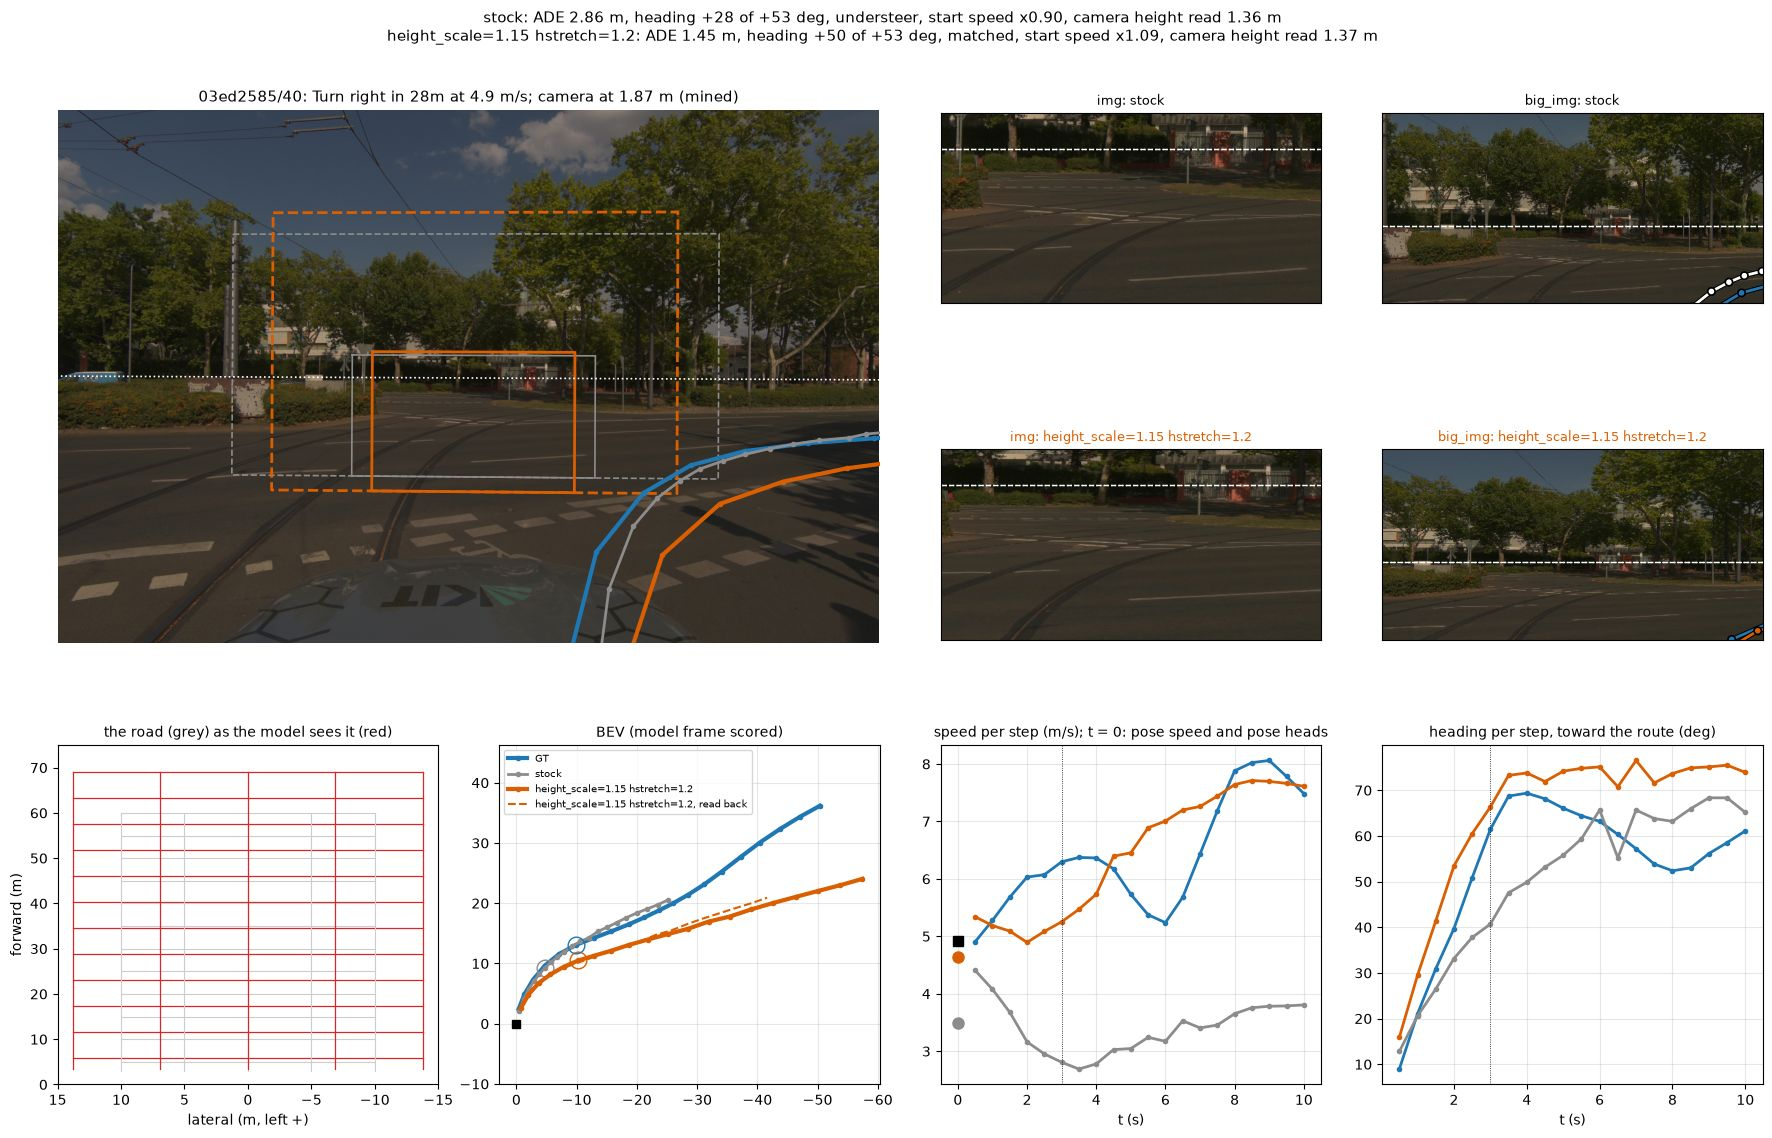

In [11]:
look(EXAMPLE_SID, setting=TRY_ST)

**Each knob on the example turn.** `strip(key, knob, values=None, view="big_img")` draws one row per knob. Each panel is the wide view the model is handed at one value, stock first, with:
- the GT where it really is, in blue;
- the plan where the model puts it, in the value's colour.

The panel on the right shows every plan in BEV.

The wide view is drawn because on a turn it is the one that sees the turn. Pass `view="img"` for the narrow one.

These are the same runs §7 scores. Look here for what each knob does to the image; read §7 for whether it helps.

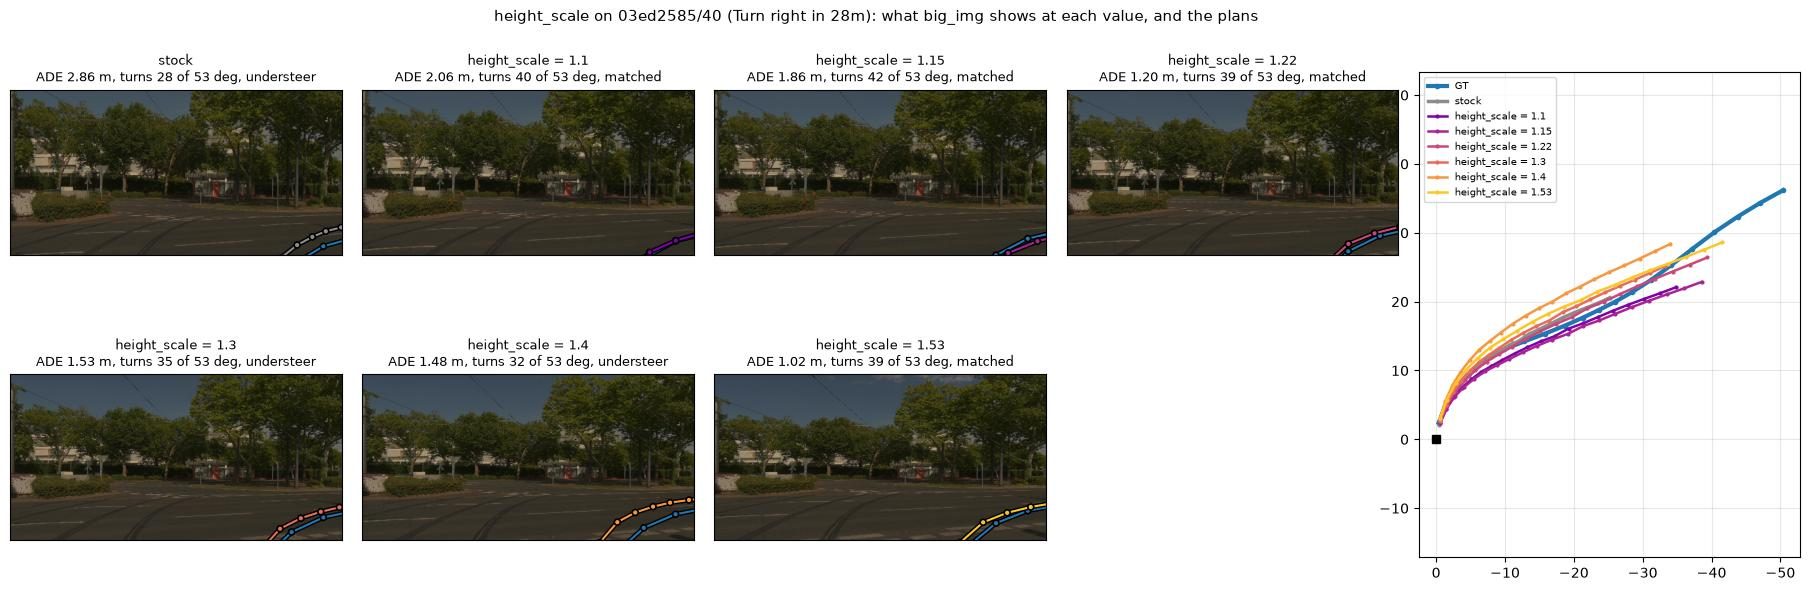

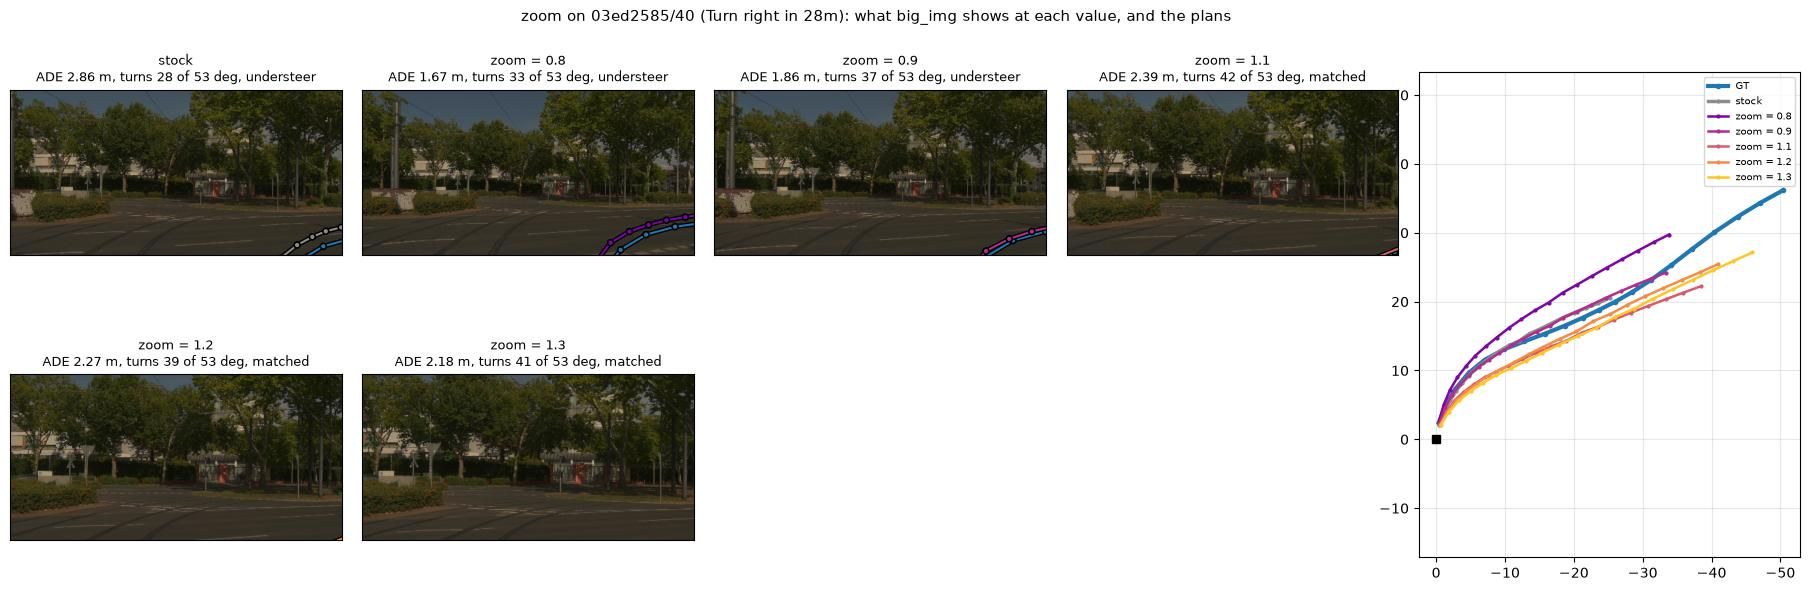

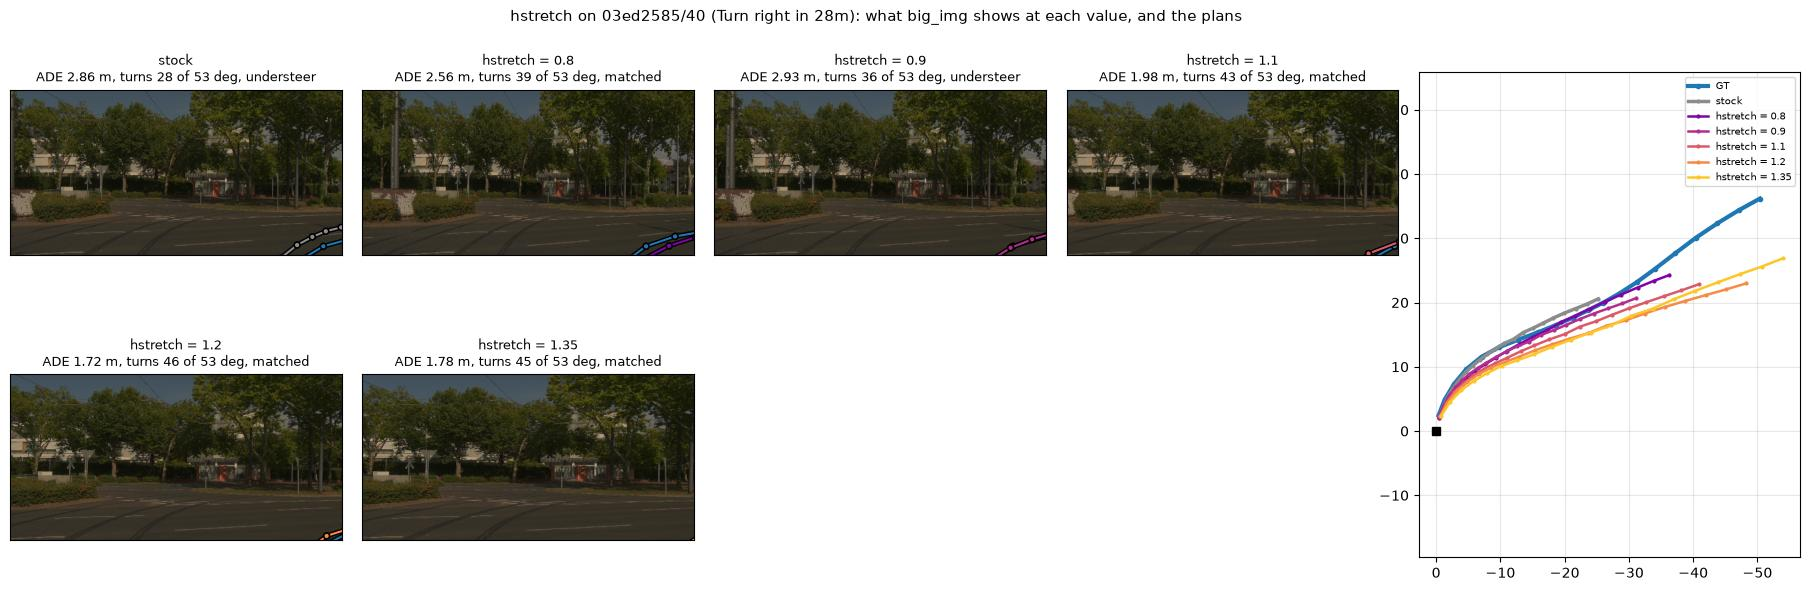

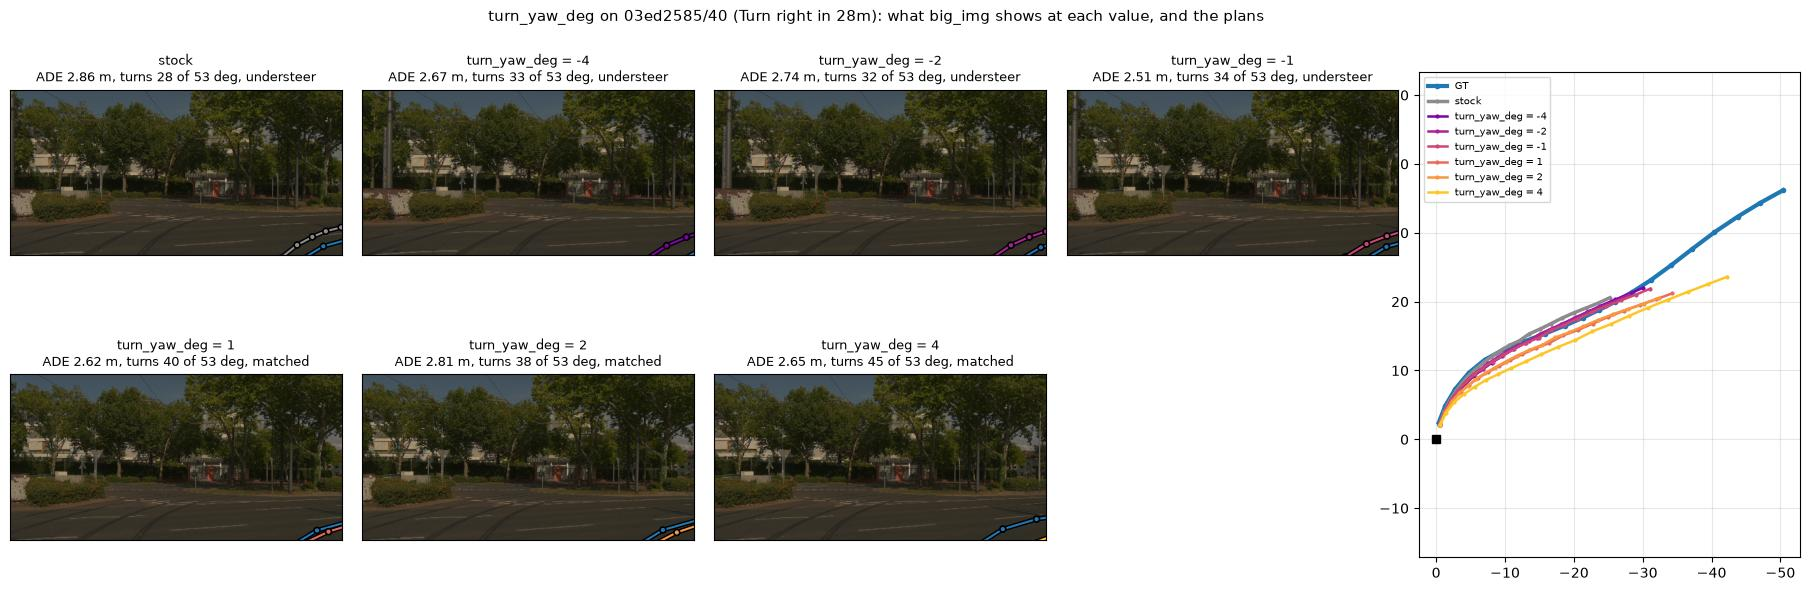

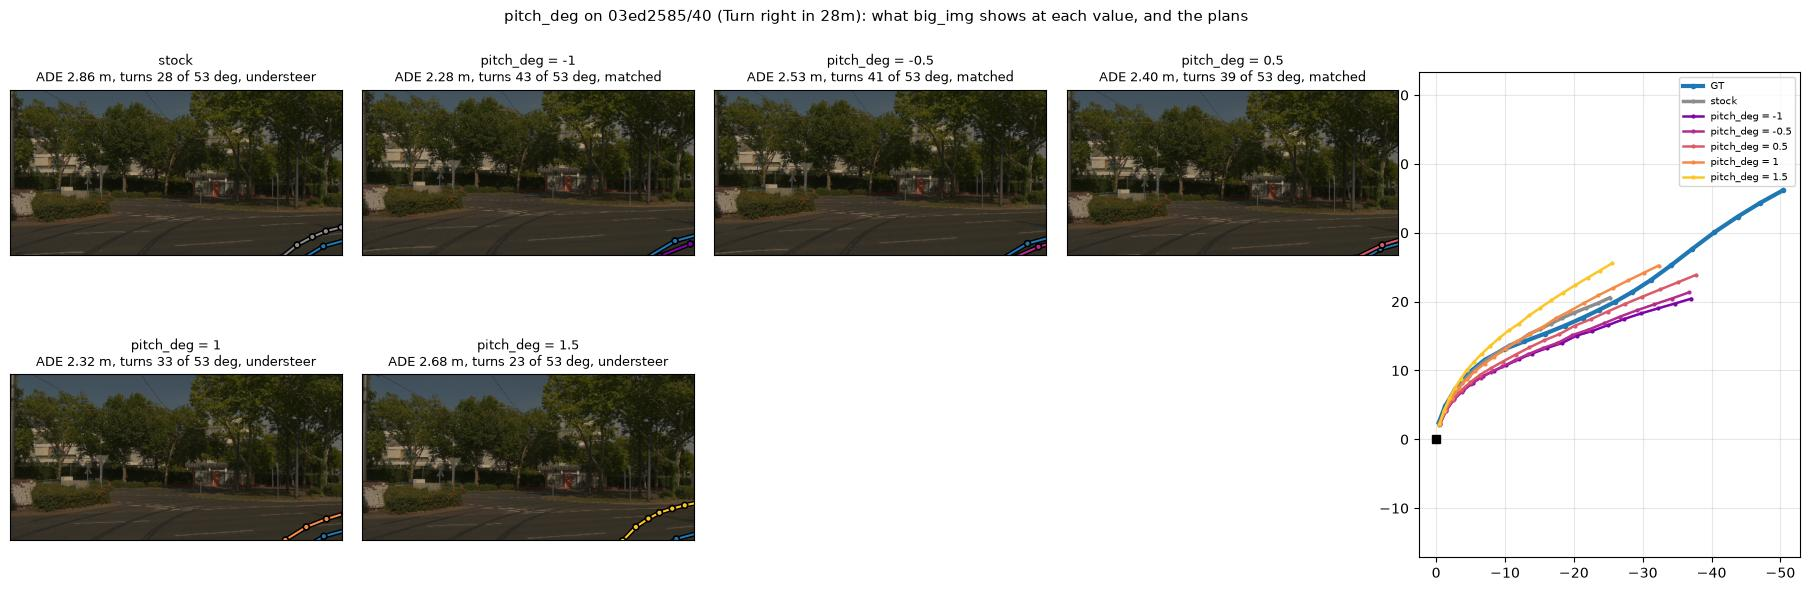

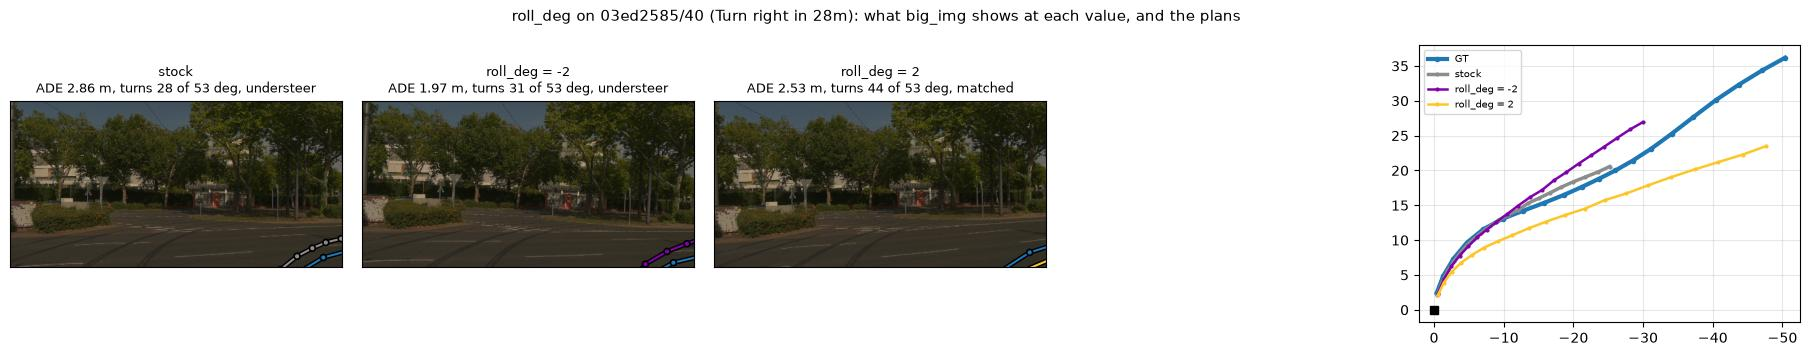

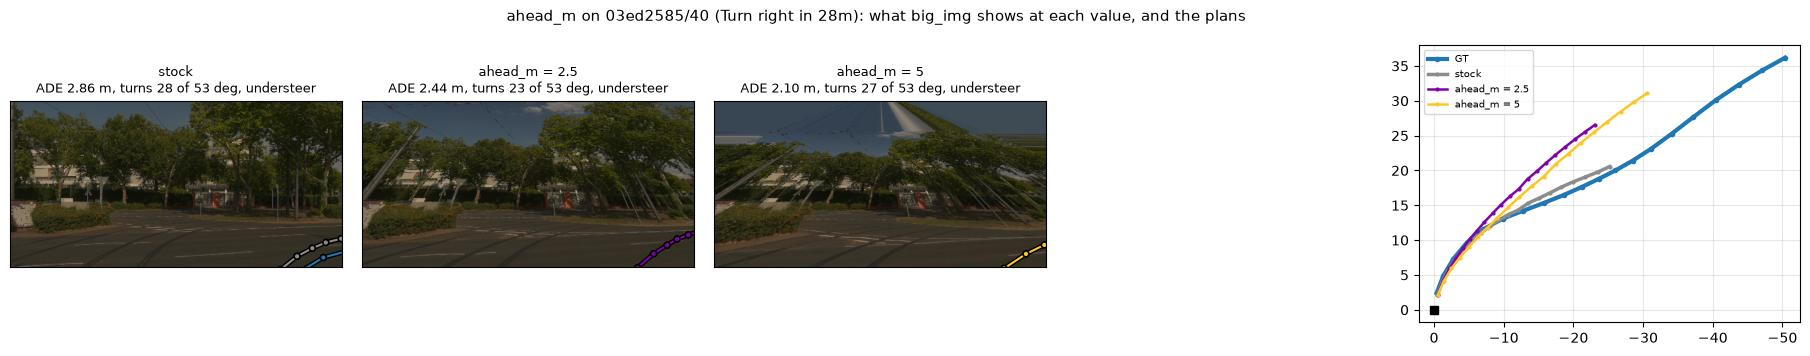

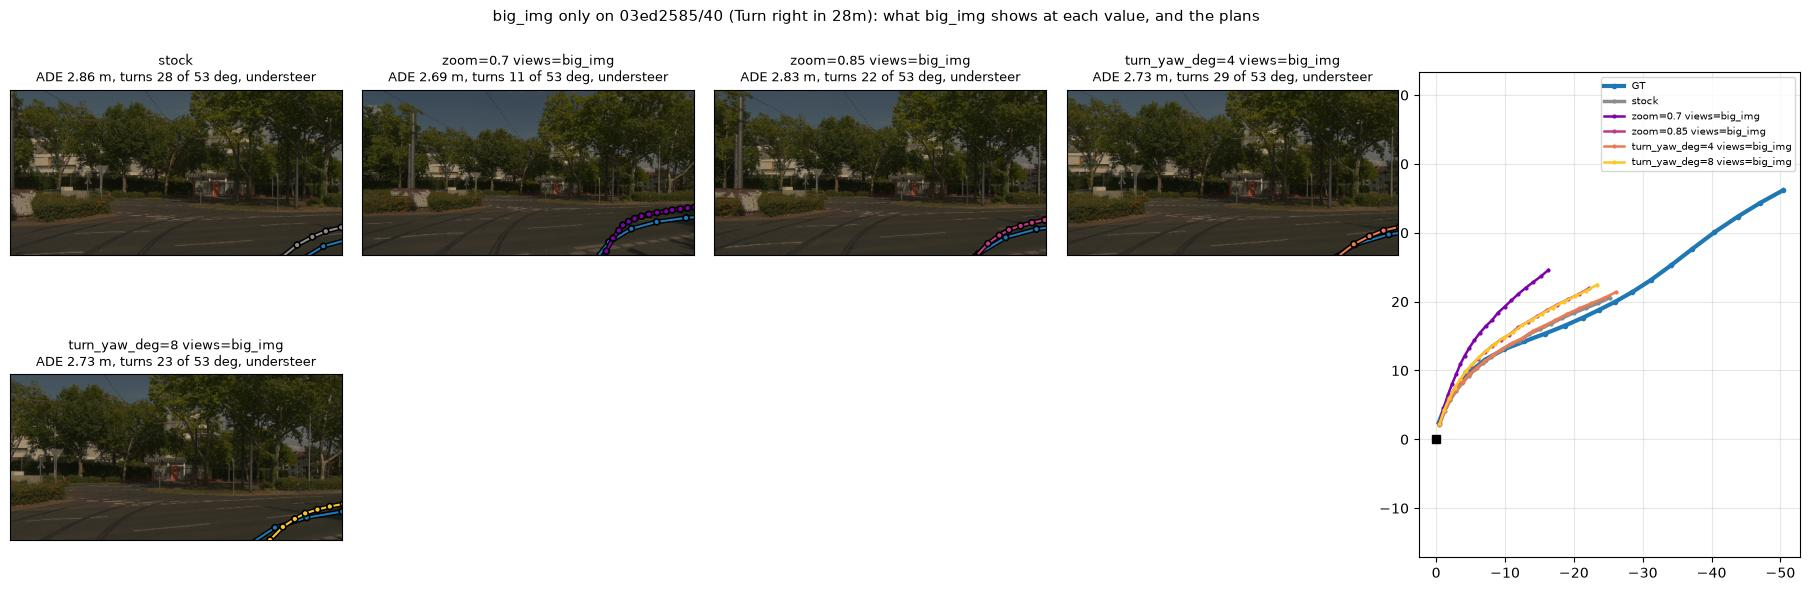

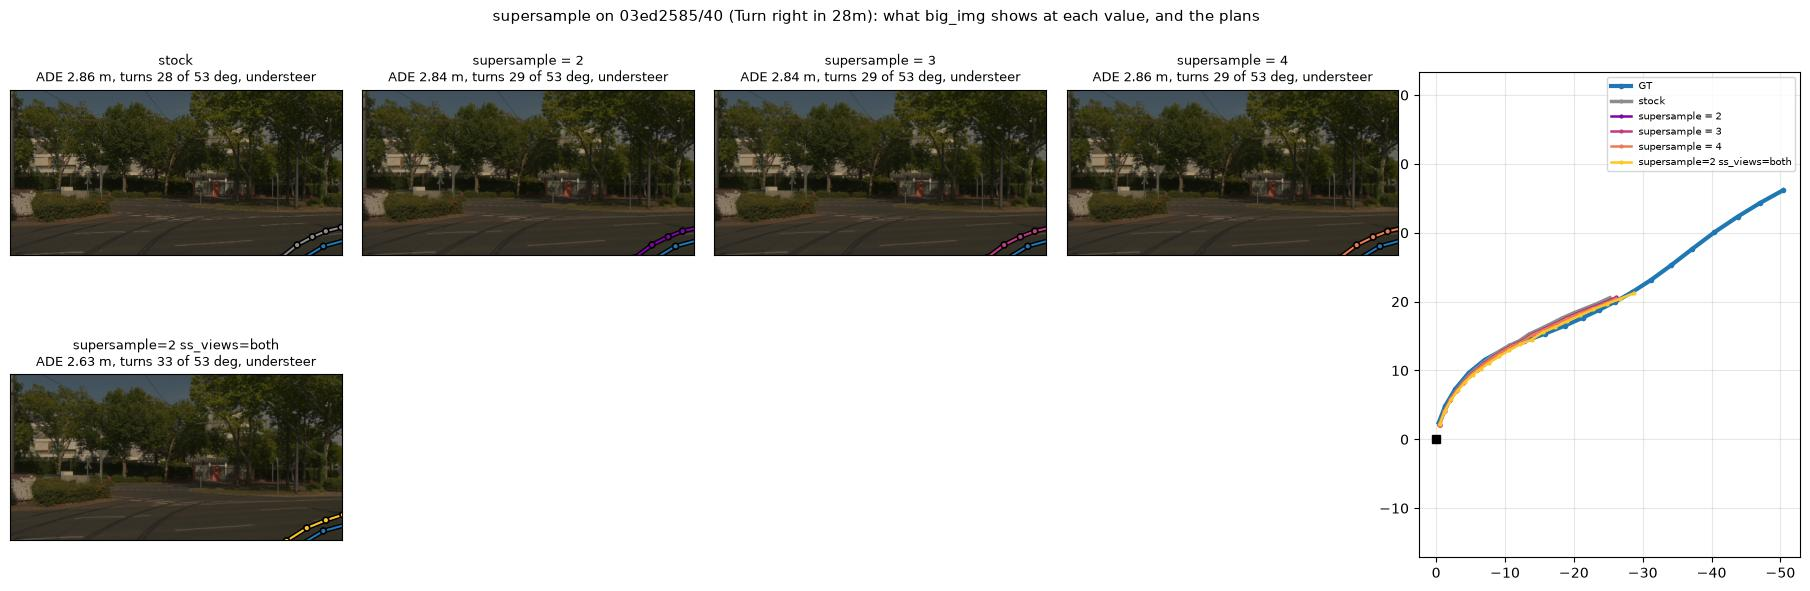

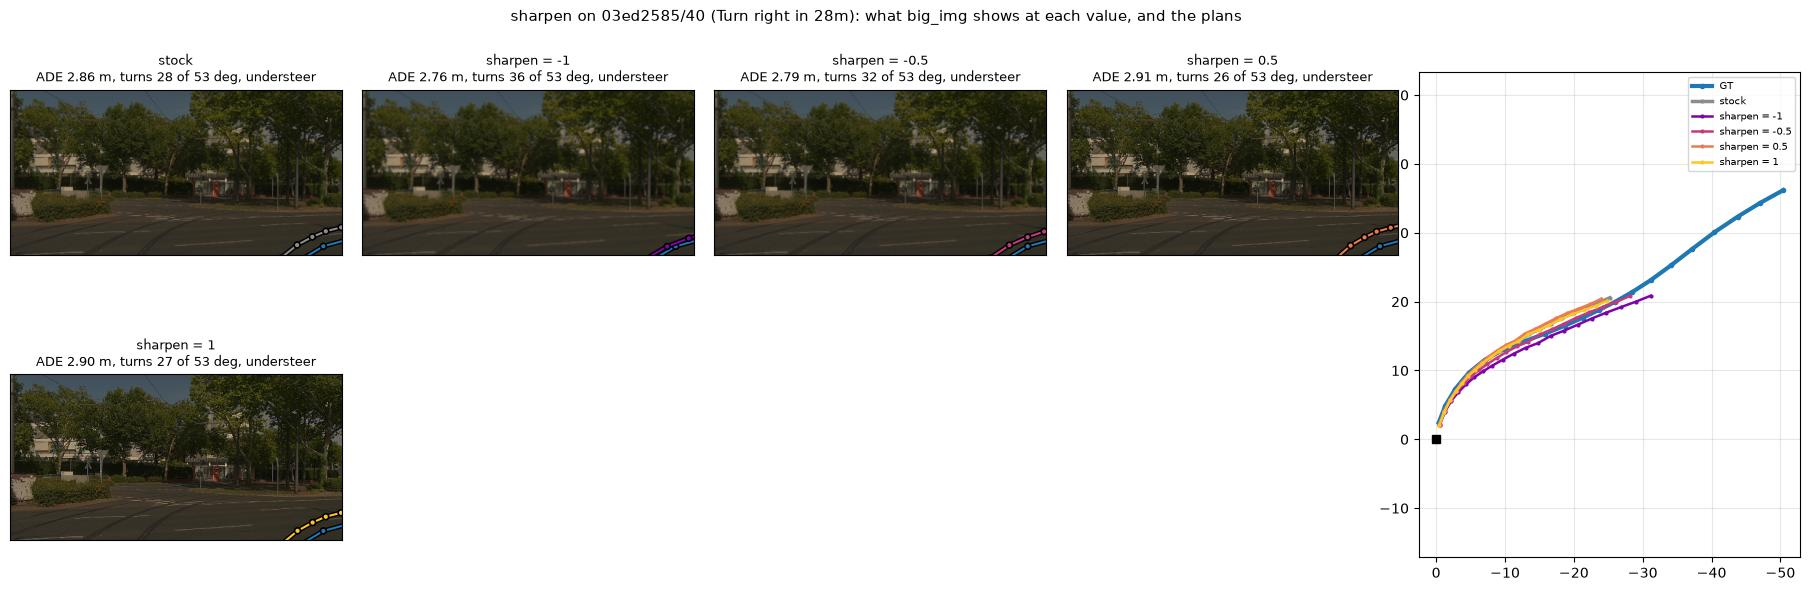

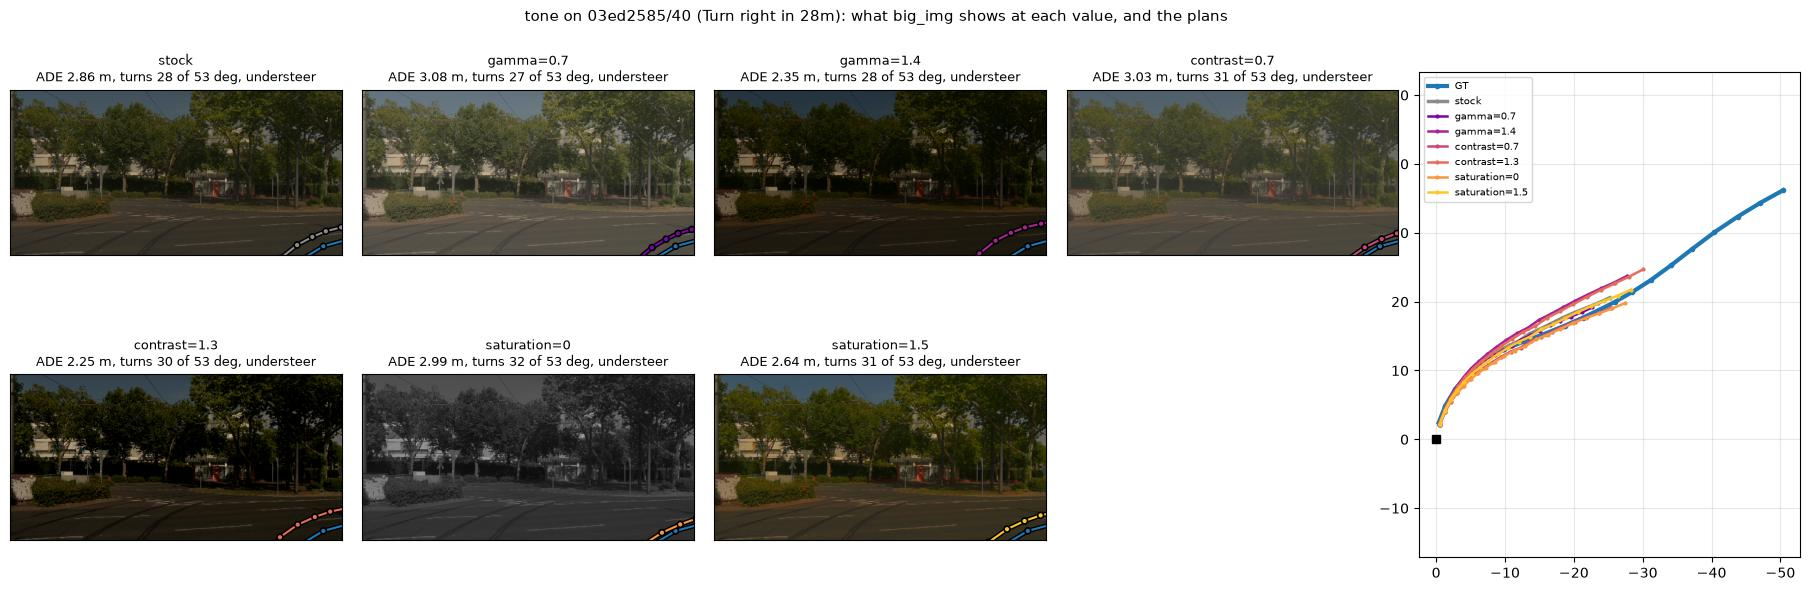

In [12]:
for knob in ("height_scale", "zoom", "hstretch", "turn_yaw_deg", "pitch_deg", "roll_deg", "ahead_m", "big_img only", "supersample", "sharpen"):
    strip(EXAMPLE_SID, knob)
strip(EXAMPLE_SID, "tone", values=[{"gamma": 0.7}, {"gamma": 1.4}, {"contrast": 0.7}, {"contrast": 1.3}, {"saturation": 0.0}, {"saturation": 1.5}])

## 6 Signs, and the noise floor

**Signs.** Before asking whether a knob helps, check that it does what §3 says it does. The model's own heads are the instrument. Each check is a knob at a moderate value on the active turns, and what it should do to one reading:

| knob | reading | expected, if the model follows the image exactly |
|---|---|---|
| `height_scale` 1.3 | `head_ratio`, its speed over the true speed | × 1.3: the road looks 1.3× farther, so it moves 1.3× faster |
| `zoom` 1.2 | `head_ratio` | × 1/1.2: everything looks 1.2× closer |
| `tick_rate` 1.6 | `v0_ratio`, the plan's start speed over the true speed | × 2/1.6 on average: each frame's motion takes 1.6 ticks instead of 2 |
| `yaw_deg` +2 | `vel_yaw`, the bearing it says the car moves on | −2°: a view turned left sees the car move to its right |
| `pitch_deg` +1 | `vel_pitch`, the same, upward | −1°: a view tilted up sees the car move down in it |

The table prints the measured mean change and how many turns moved the expected way.
- **The direction is the check.** A knob that moves its reading the wrong way on most turns is not doing what §3 says.
- **The size need not match.** The model does not follow the image all the way: the note's Q4 measured the pose head's speed going as s^0.54 with the height scale, on 54 keyframes. So at 1.3 expect less than ×1.3.
- **Why the tick rate is read off the plan.** The model is handed the newest frame and the one 4 ticks back (`frame_skip`, in the adapter's `supercombo.py`). The pose head reads that one pair; the plan also reads the history.
    - At 1.6, 1.75 and 1.9, the keyframe's last pair still spans two frames, as at stock. So the pose head should read stock's speed exactly, and the plan alone should feel the faster average.
    - At 2.2, the last pair spans one frame on the keyframe-40 turns, and the pose head reads half the speed. §7's row for 2.2 is that, not a timing calibration.

**The noise floor.** A shift of half a model pixel is about 0.03° in the narrow view: no geometry at all. But each pixel then comes from a different camera pixel, and the model's plan moves anyway. Eight such shifts on each turn (`dx_px`, `dy_px` and both, ±0.5) are eight settings that should do nothing, so what they do is the floor:
- **per turn:** the median |change| in one turn's reading;
- **for the mean over the turns:** the range of the eight shifts' means.

§7 and §8 draw that range as a grey band. A knob whose mean change falls inside it is indistinguishable from resampling the image, whatever its bootstrap interval says.

In [13]:
SIGNS = [
    ("height_scale", 1.3, "head_ratio", "ratio", 1.3),
    ("zoom", 1.2, "head_ratio", "ratio", 1 / 1.2),
    ("tick_rate", 1.6, "v0_ratio", "ratio", 2 / 1.6),
    ("yaw_deg", 2.0, "vel_yaw", "diff", -2.0),
    ("pitch_deg", 1.0, "vel_pitch", "diff", -1.0),
]
sign_df = table([Setting(**{k: v}) for k, v, *_ in SIGNS])
base = sign_df[sign_df.setting == "stock"].set_index("key")
rows = []
for knob, value, col, how, expect in SIGNS:
    got = sign_df[sign_df.setting == Setting(**{knob: value}).label()].set_index("key")
    ch = got[col] / base[col] if how == "ratio" else got[col] - base[col]
    toward = ch > 1 if (how == "ratio" and expect > 1) else ch < 1 if how == "ratio" else ch > 0 if expect > 0 else ch < 0
    rows.append(
        {
            "knob": f"{knob} = {value:g}",
            "reading": col,
            "expected": f"x{expect:.2f}" if how == "ratio" else f"{expect:+.1f} deg",
            "measured (mean)": f"x{ch.mean():.2f}" if how == "ratio" else f"{ch.mean():+.2f} deg",
            "measured (range)": f"{ch.min():.2f} .. {ch.max():.2f}",
            "the expected way": f"{int(toward.sum())}/{len(ch)}",
            "road head pitch, yaw (deg)": f"{(got.road_pitch - base.road_pitch).mean():+.2f}, {(got.road_yaw - base.road_yaw).mean():+.2f}",
        }
    )
display(pd.DataFrame(rows).set_index("knob"))

,reading,expected,measured (mean),measured (range),the expected way,"road head pitch, yaw (deg)"
knob,,,,,,
height_scale = 1.3,head_ratio,x1.30,x1.20,1.10 .. 1.32,10/10,"-0.02, -0.06"
zoom = 1.2,head_ratio,x0.83,x0.87,0.66 .. 1.08,9/10,"-0.02, -0.10"
tick_rate = 1.6,v0_ratio,x1.25,x1.08,1.00 .. 1.26,9/10,"+0.00, +0.00"
yaw_deg = 2,vel_yaw,-2.0 deg,-0.35 deg,-1.22 .. 0.97,8/10,"-0.00, -0.26"
pitch_deg = 1,vel_pitch,-1.0 deg,-0.43 deg,-1.16 .. -0.06,10/10,"+0.23, +0.01"


In [14]:
FLOOR = [Setting(dx_px=x, dy_px=y) for x, y in [(0.5, 0), (-0.5, 0), (0, 0.5), (0, -0.5), (0.5, 0.5), (-0.5, 0.5), (0.5, -0.5), (-0.5, -0.5)]]
floor_df = table(FLOOR)


def change(df, col, settings, base="stock"):
    """(turns x settings): each setting's change in `col` from `base`, per turn."""
    b = df[df.setting == base].set_index("key")[col]
    return pd.DataFrame({st.label(): df[df.setting == st.label()].set_index("key")[col] - b for st in settings})


FLOOR_COLS = ("ade", "dpsi_err", "v0_ratio", "head_ratio", "ade_long")
BAND = {c: (float(change(floor_df, c, FLOOR).mean().min()), float(change(floor_df, c, FLOOR).mean().max())) for c in FLOOR_COLS}
moved = [
    np.abs(plan(r)[:N_H] - plan(s)[:N_H]).max()
    for st in FLOOR
    for r, s in zip(fetch([(st, k) for k in ACTIVE]), fetch([(STOCK, k) for k in ACTIVE]))
]
print(f"eight half-pixel shifts on {len(ACTIVE)} turn(s): a plan moves by up to {max(moved):.2f} m within H (median {np.median(moved):.2f})")
display(
    pd.DataFrame(
        {
            "per turn: median |change|": {c: float(np.nanmedian(np.abs(change(floor_df, c, FLOOR).values))) for c in FLOOR_COLS},
            "mean over the turns: lowest": {c: BAND[c][0] for c in FLOOR_COLS},
            "mean over the turns: highest": {c: BAND[c][1] for c in FLOOR_COLS},
        }
    ).round(3)
)
print("each shift's change in ADE (m), per turn:")
d_floor = change(floor_df, "ade", FLOOR)
display(d_floor.round(2).assign(median=d_floor.median(axis=1).round(2)))

eight half-pixel shifts on 10 turn(s): a plan moves by up to 1.15 m within H (median 0.19)


,per turn: median |change|,mean over the turns: lowest,mean over the turns: highest
ade,0.058,-0.022,0.024
dpsi_err,0.399,-0.551,0.654
v0_ratio,0.006,-0.003,0.001
head_ratio,0.009,-0.002,0.006
ade_long,0.206,-0.173,0.135


each shift's change in ADE (m), per turn:


,dx_px=0.5,dx_px=-0.5,dy_px=0.5,dy_px=-0.5,dx_px=0.5 dy_px=0.5,dx_px=-0.5 dy_px=0.5,dx_px=0.5 dy_px=-0.5,dx_px=-0.5 dy_px=-0.5,median
key,,,,,,,,,
dbba76d9/130,0.04,-0.00,-0.05,-0.07,0.03,-0.00,-0.03,0.03,-0.00
5bf1c78c/40,-0.01,-0.00,0.03,0.08,0.03,0.03,0.09,0.10,0.03
d96782f8/220,-0.02,-0.01,0.03,0.03,0.05,0.07,0.01,0.05,0.03
8c501afb/40,0.00,-0.07,-0.08,0.13,0.08,0.06,0.04,-0.08,0.02
18775d16/40,-0.06,-0.05,0.01,-0.22,0.05,0.02,-0.23,-0.13,-0.05
03ed2585/40,-0.09,0.00,-0.16,-0.04,-0.29,-0.21,-0.06,-0.14,-0.11
2673dca8/220,0.04,-0.04,0.04,0.03,0.02,-0.03,0.05,-0.02,0.02
5d443f77/40,-0.03,-0.08,-0.10,-0.13,-0.10,-0.17,-0.13,-0.15,-0.12
0cfdeb83/40,0.04,0.09,0.09,0.06,0.09,0.15,0.06,0.10,0.09


## 7 One knob at a time

Every value in `SWEEPS`, each knob alone, on the active turns. Two views of the same runs:

**The table** has one row per setting, best ADE first. The columns are `summary()`'s:
- `dADE` [`lo`, `hi`]: the mean change in ADE from stock, with its 95% bootstrap interval over scenes, which on the ten are the turns;
- `better`: turns whose ADE dropped;
- `planned`: turns planned toward the route;
- `dpsi_err`: the mean heading error over H, negative for too little turn; `|dpsi_err|` is its size;
- `v0_ratio`, `head_ratio`: the plan's start speed, and the pose head's speed, over the true speed;
- `cam_h`: the height the road head reads;
- `ade_long`, `turn_frac`: the whole turn, past H;
- `gt_in_big_img`: the share of the GT's waypoints inside the wide view, so how much of the turn the model can see at all;
- `floor`: whether `dADE` is outside §6's band. A row marked `in` changed the score no more than a half-pixel shift does.

**The plots** have one panel per knob, the value on x, stock at the knob's default. Each draws:
- each turn's change, faint: left turns in one colour, right turns in another;
- the mean, in black, with its 95% interval;
- §6's band, in grey;
- for heading and speed, a dashed line where the mean would be exactly right. It stays on the axis even where it squashes the curves, because how far each knob falls short of it is the point.

In [15]:
def swept(knob, values=None):
    """The settings a knob's sweep runs, in its order: SWEEPS[knob] by default."""
    vals = SWEEPS[knob] if values is None else values
    return [as_setting(v) if isinstance(v, dict) else Setting(**{knob: v}) for v in vals]


SWEPT = {knob: swept(knob) for knob in SWEEPS}
sweep_df = table([st for sts in SWEPT.values() for st in sts])
S7 = summary(sweep_df)
_knob_of = {st.label(): k for k, sts in SWEPT.items() for st in sts}
S7.insert(0, "knob", [_knob_of.get(name, "") for name in S7.index])
S7["floor"] = np.where((S7.dADE >= BAND["ade"][0]) & (S7.dADE <= BAND["ade"][1]), "in", "out")
display(S7.sort_values("dADE").round(2))

,knob,n,ADE,dADE,lo,hi,better,planned,dpsi_err,|dpsi_err|,v0_ratio,head_ratio,cam_h,ade_long,turn_frac,gt_in_big_img,in_bounds,floor
setting,,,,,,,,,,,,,,,,,,
height_scale=1.22,height_scale,10,0.88,-0.72,-1.11,-0.31,9/10,5/10,-17.25,20.01,1.01,0.95,1.40,8.63,0.44,0.33,1.00,out
height_scale=1.15,height_scale,10,0.96,-0.63,-1.01,-0.28,9/10,5/10,-17.18,19.55,0.96,0.90,1.42,8.63,0.42,0.33,1.00,out
zoom=0.9,zoom,10,0.99,-0.61,-0.96,-0.27,9/10,5/10,-18.09,20.27,0.96,0.90,1.43,9.17,0.45,0.35,1.00,out
height_scale=1.3,height_scale,10,1.02,-0.58,-0.97,-0.17,7/10,5/10,-18.19,20.28,1.05,0.97,1.38,8.65,0.44,0.35,1.00,out
height_scale=1.1,height_scale,10,1.10,-0.49,-0.76,-0.24,9/10,5/10,-17.85,19.40,0.93,0.88,1.44,9.18,0.42,0.31,1.00,out
height_scale=1.4,height_scale,10,1.12,-0.48,-0.94,0.00,7/10,5/10,-18.41,20.76,1.10,1.01,1.37,9.24,0.43,0.36,1.00,out
zoom=0.8,zoom,10,1.29,-0.30,-0.73,0.12,7/10,5/10,-18.25,20.14,1.05,0.98,1.43,8.88,0.46,0.41,1.00,out
tick_rate=1.6,tick_rate,10,1.31,-0.29,-0.66,-0.03,7/10,5/10,-18.16,21.00,0.94,0.82,1.43,10.00,0.44,0.30,1.00,out
pitch_deg=-1,pitch_deg,10,1.33,-0.26,-0.38,-0.13,9/10,5/10,-18.74,20.35,0.90,0.84,1.42,9.59,0.40,0.31,1.00,out


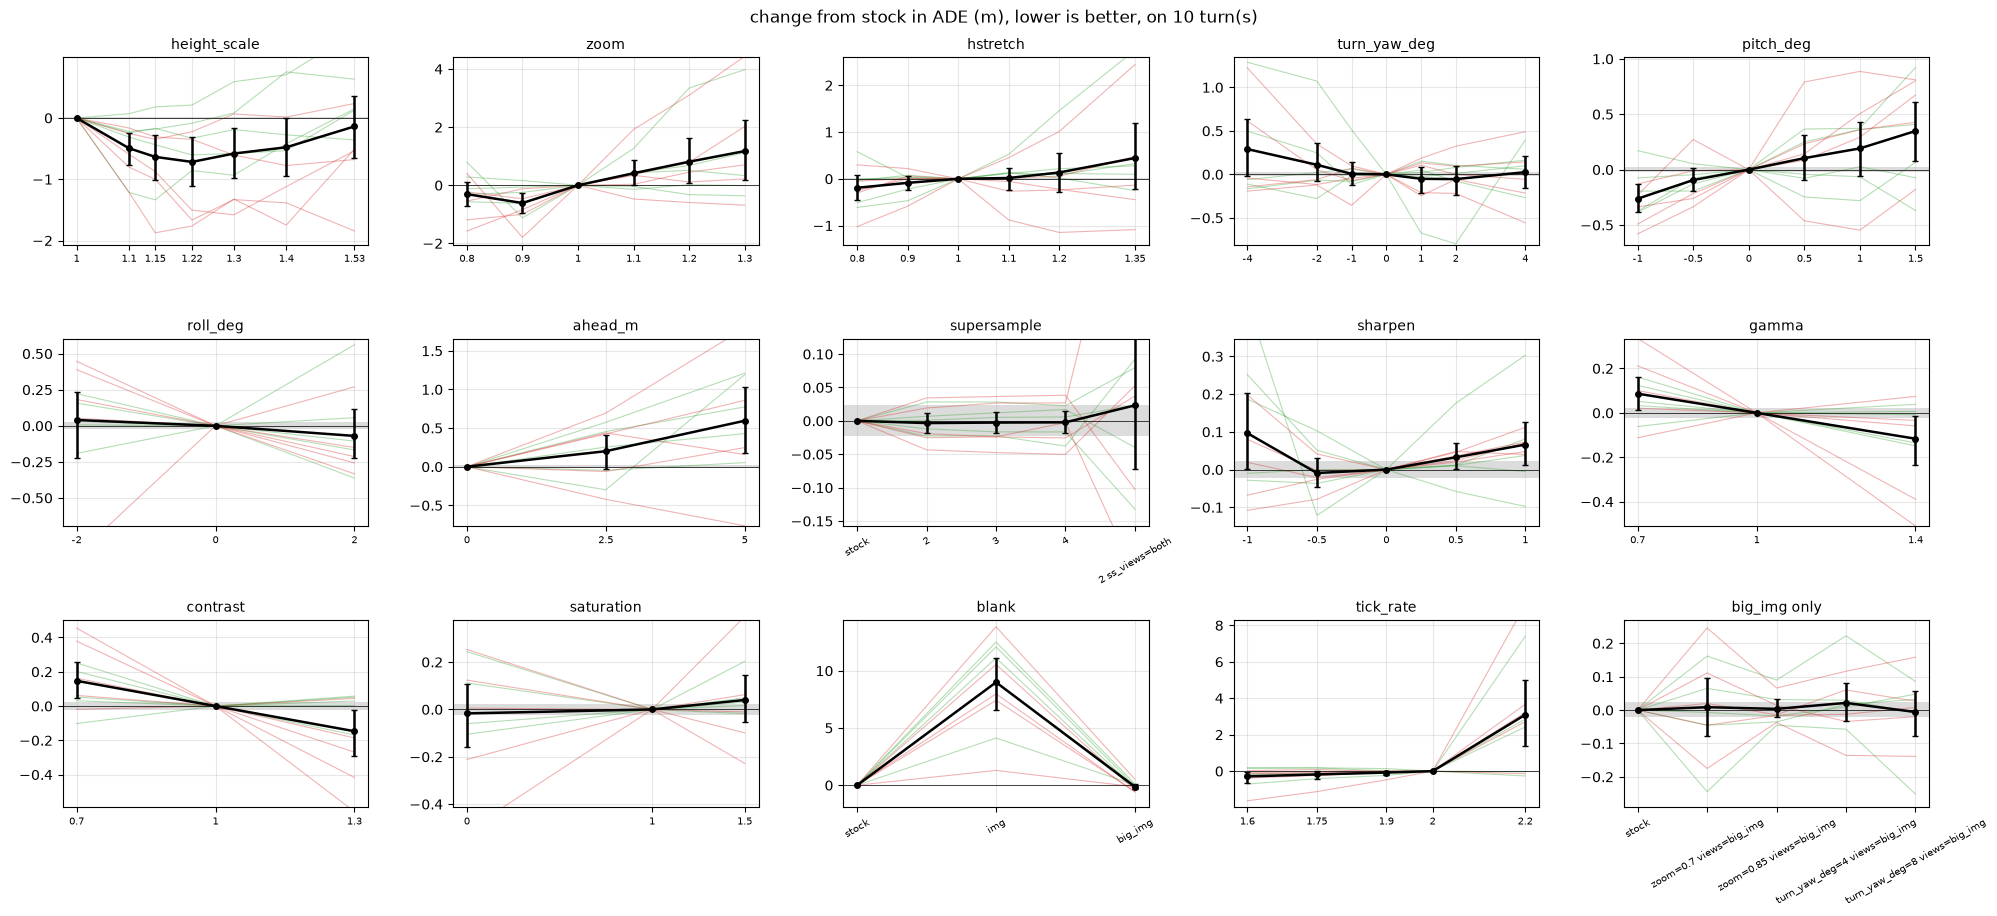

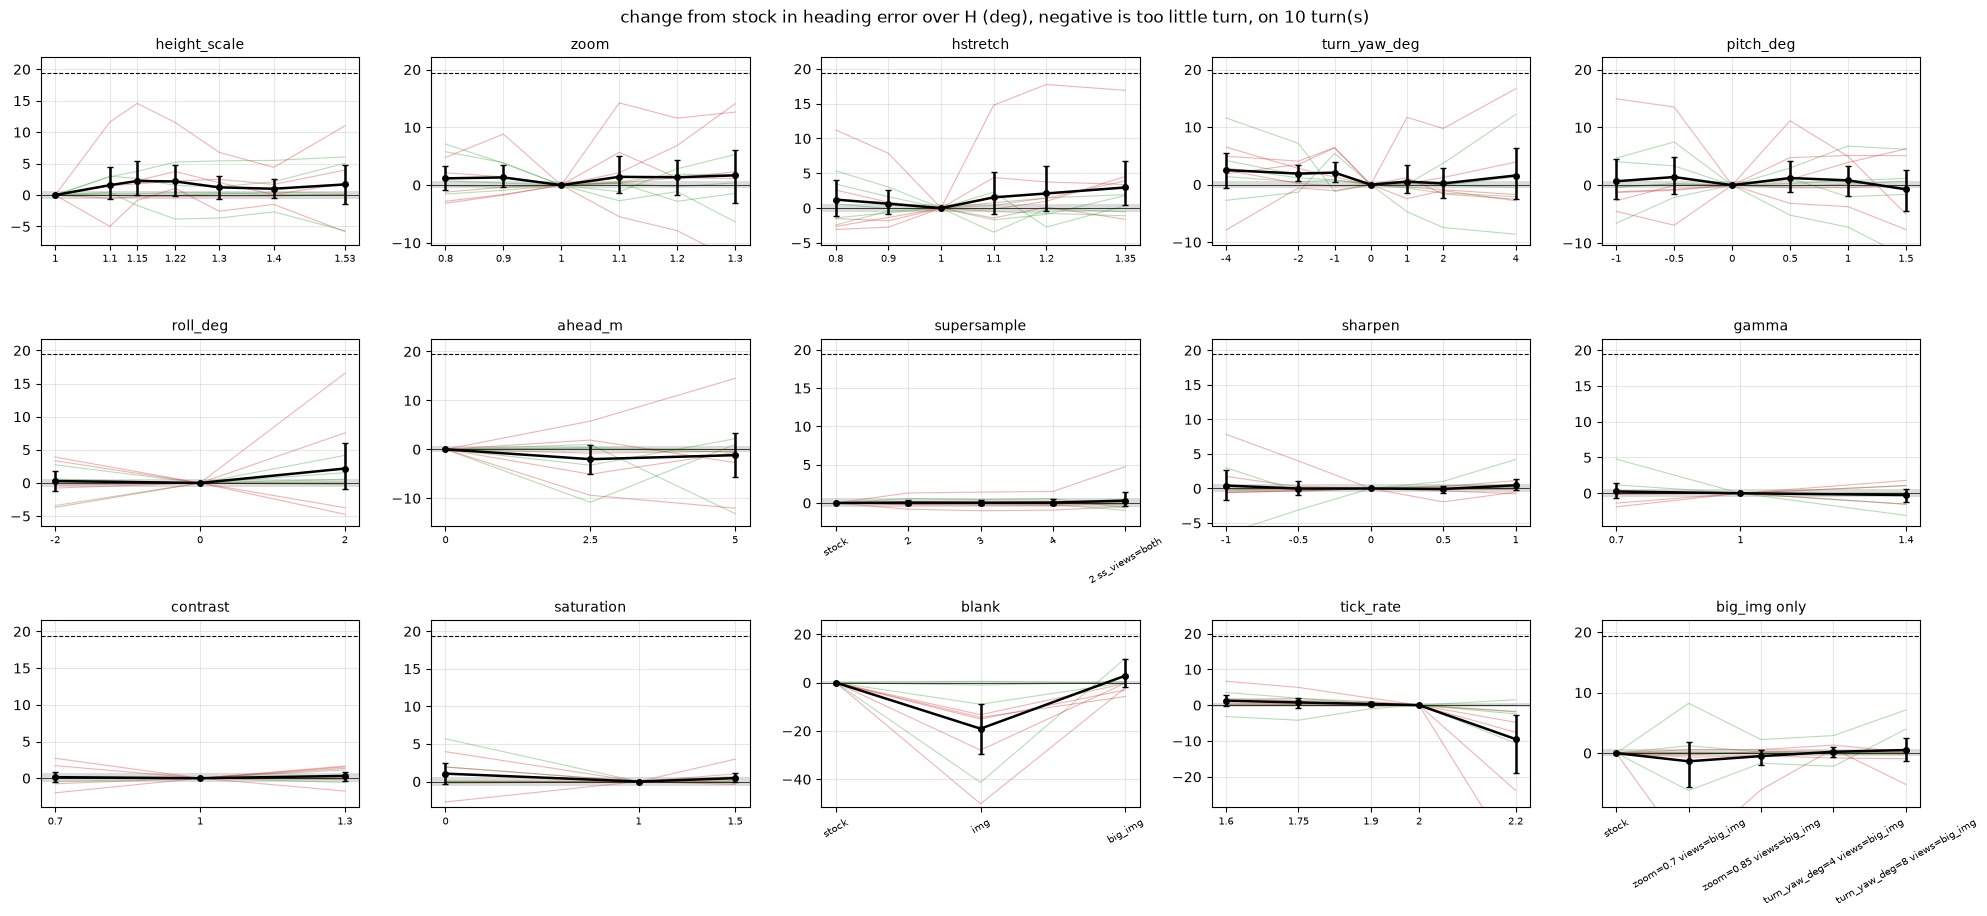

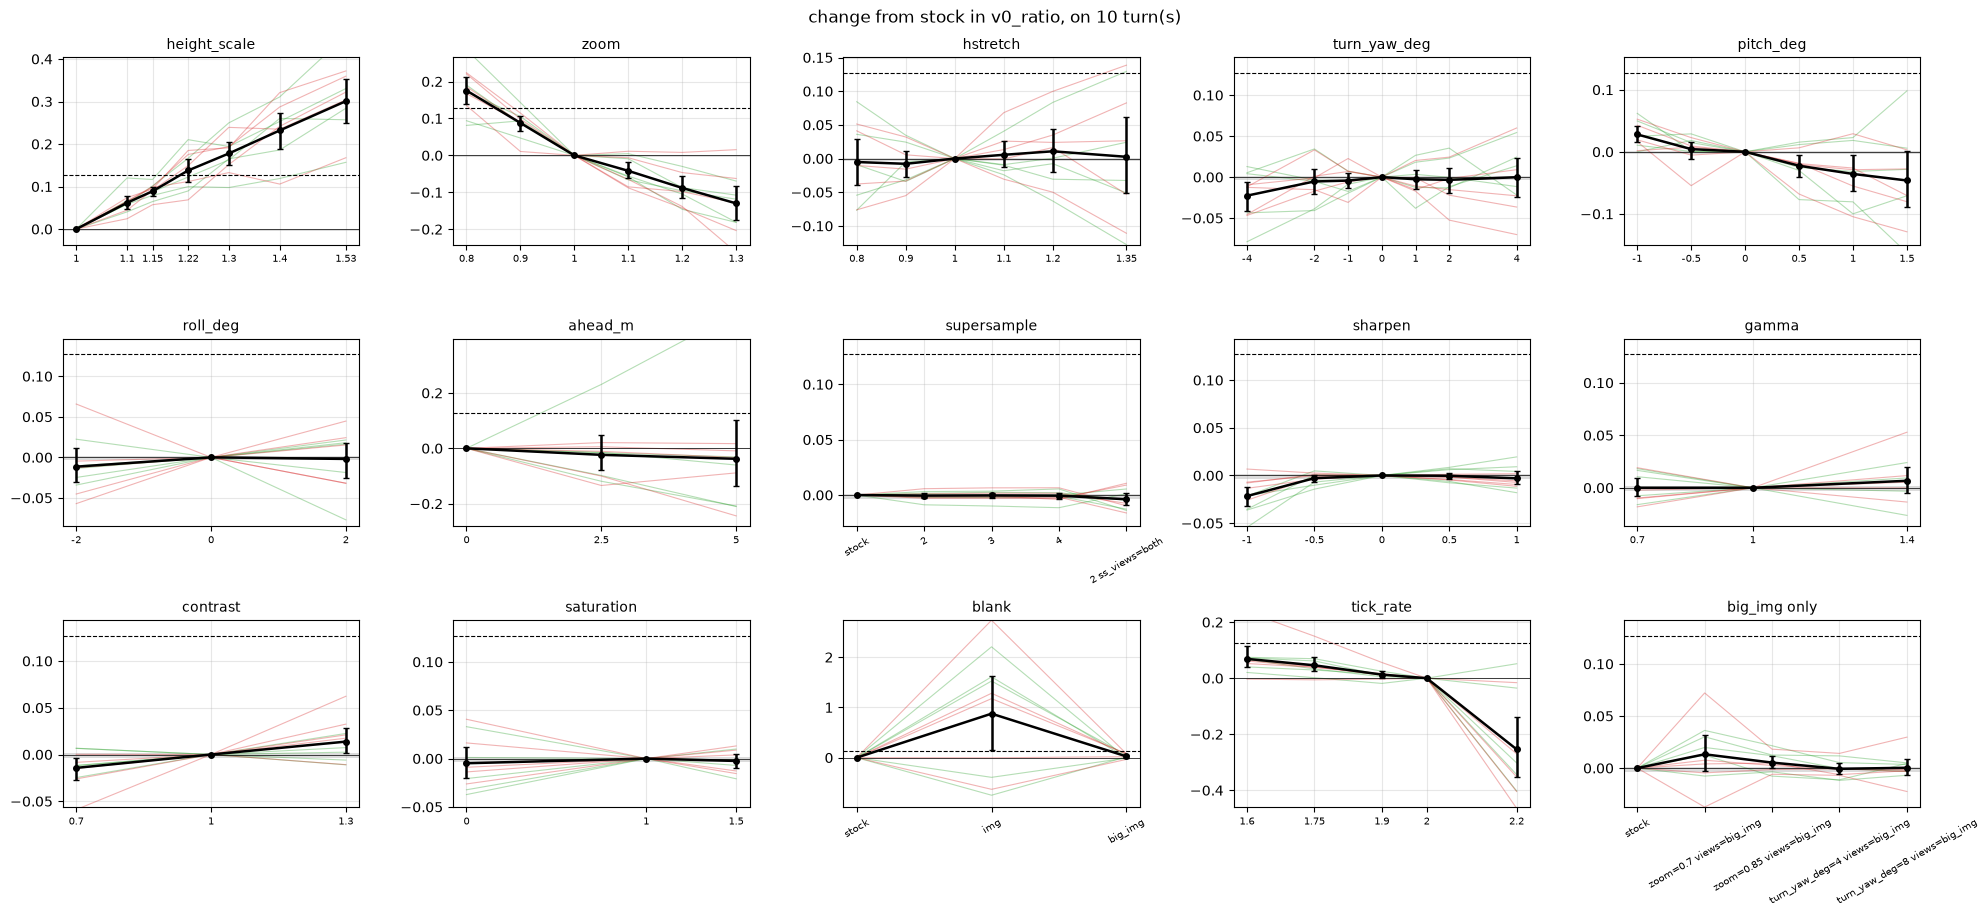

In [16]:
LEFT_RIGHT = {"left": "#2ca02c", "right": "#d62728"}  # each turn's line, by the route's side
TARGET = {"dpsi_err": 0.0, "v0_ratio": 1.0, "head_ratio": 1.0}  # where a mean reading would be exactly right


def _x_of(knob, sts):
    """(x positions, tick labels, numeric): a knob's values on x, with stock at its default."""
    vals = [getattr(st, knob) if knob in Setting.__dataclass_fields__ else None for st in sts]
    numeric = all(isinstance(v, float | int) and not isinstance(v, bool) for v in vals) and len(set(vals)) == len(vals)
    if numeric:
        default = 2.0 if knob == "tick_rate" else Setting.__dataclass_fields__[knob].default  # None: the adapter's 2
        xs = [default] + vals
        return xs, [f"{x:g}" for x in xs], True
    labels = ["stock"] + [st.label().replace(f"{knob}=", "") for st in sts]
    return list(range(len(labels))), labels, False


def sweep_plot(df, col="ade", knobs=None, ncol=5):
    """Each knob's change in `col` from stock against its value (§7 says what is drawn)."""
    knobs = [k for k in (knobs or SWEPT) if k in SWEPT]
    nrow = -(-len(knobs) // ncol)
    fig, axs = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.1 * nrow), squeeze=False)
    base = df[df.setting == "stock"].set_index("key")[col]
    for ax, knob in zip(axs.flat, knobs):
        sts = SWEPT[knob]
        xs, labels, numeric = _x_of(knob, sts)
        d = change(df, col, sts)
        d.insert(0, "stock", 0.0)
        order = np.argsort(xs, kind="stable")
        xs, labels, d = [xs[i] for i in order], [labels[i] for i in order], d.iloc[:, order]
        for key, row in d.iterrows():
            side = df[df.key == key].route.iloc[0]
            ax.plot(xs, row.values, "-", color=LEFT_RIGHT.get(side, GREY), lw=0.8, alpha=0.35)
        mean = d.mean(axis=0).values
        ci = np.array([boot_ci(d[c]) if c != "stock" else (0.0, 0.0) for c in d.columns])
        ax.errorbar(xs, mean, yerr=[mean - ci[:, 0], ci[:, 1] - mean], fmt="o-", color="black", lw=1.8, ms=4, capsize=2)
        if col in BAND:
            ax.axhspan(*BAND[col], color=GREY, alpha=0.3, lw=0)
        if col in TARGET:
            ax.axhline(TARGET[col] - base.mean(), color="black", ls="--", lw=0.8)
        ax.axhline(0, color="black", lw=0.5)
        ax.set_xticks(xs)
        ax.set_xticklabels(labels, fontsize=7, rotation=0 if numeric else 30)
        ax.set_title(knob, fontsize=10)
        ax.grid(alpha=0.3)
        lo, hi = np.nanpercentile(d.values, [2, 98])
        lo, hi = min(lo, mean.min()), max(hi, mean.max())
        if col in TARGET:  # kept on the axis even where it squashes the curves: how far every knob falls short is the point
            lo, hi = min(lo, TARGET[col] - base.mean()), max(hi, TARGET[col] - base.mean())
        pad = 0.1 * (hi - lo + 1e-9)
        ax.set_ylim(lo - pad, hi + pad)
    for ax in axs.flat[len(knobs) :]:
        ax.set_visible(False)
    what = {"ade": "ADE (m), lower is better", "dpsi_err": "heading error over H (deg), negative is too little turn"}
    fig.suptitle(f"change from stock in {what.get(col, col)}, on {len(ACTIVE)} turn(s)", fontsize=12)
    fig.tight_layout()
    plt.show()


sweep_plot(sweep_df, "ade")
sweep_plot(sweep_df, "dpsi_err")
sweep_plot(sweep_df, "v0_ratio")

## 8 Two knobs at once

`GRIDS` puts two knobs on a grid. They were chosen from §7, each to ask whether two effects add:
- **height × pitch:** the two knobs that raised the start speed and cut ADE on most turns;
- **height × hstretch:** a narrower view (0.8, 0.9) cut ADE a little, a wider one (1.2) turned the plan a little more;
- **height × turn_yaw:** a view turned away from the route turned the plan more. With the speed right, does that cut ADE?
- **zoom × hstretch:** zoom below 1 shows more of the road and slows it at once.

Each cell is one setting run on every active turn.
- The left map is the mean change in ADE from stock, blue for better. Its text is that change and how many turns improved.
- The right map is the mean heading error over H, so 0 is a plan that turns as much as the GT on average. Stock's is the cell where both knobs are at their defaults.

A cell's text is grey where its ADE change is inside §6's band.

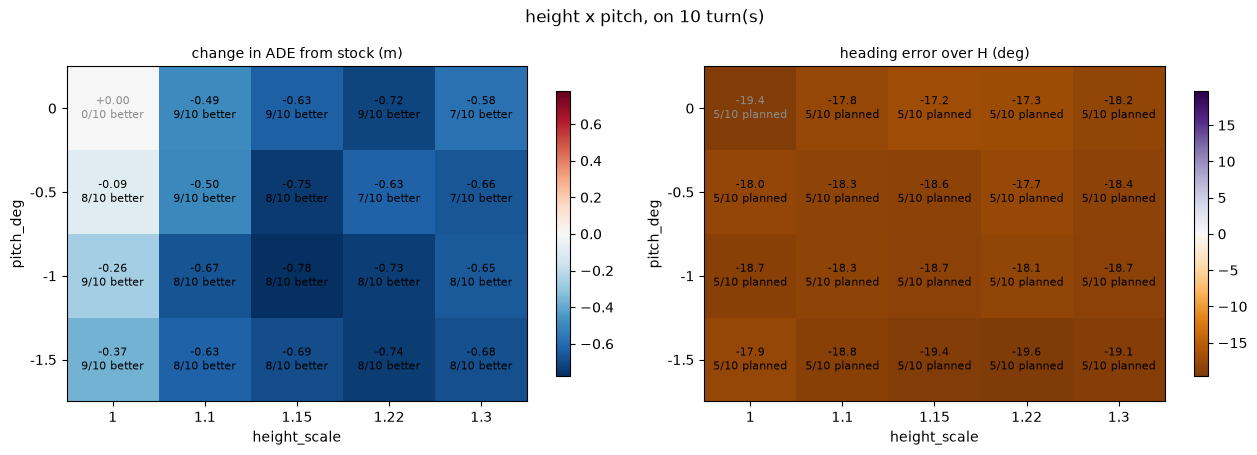

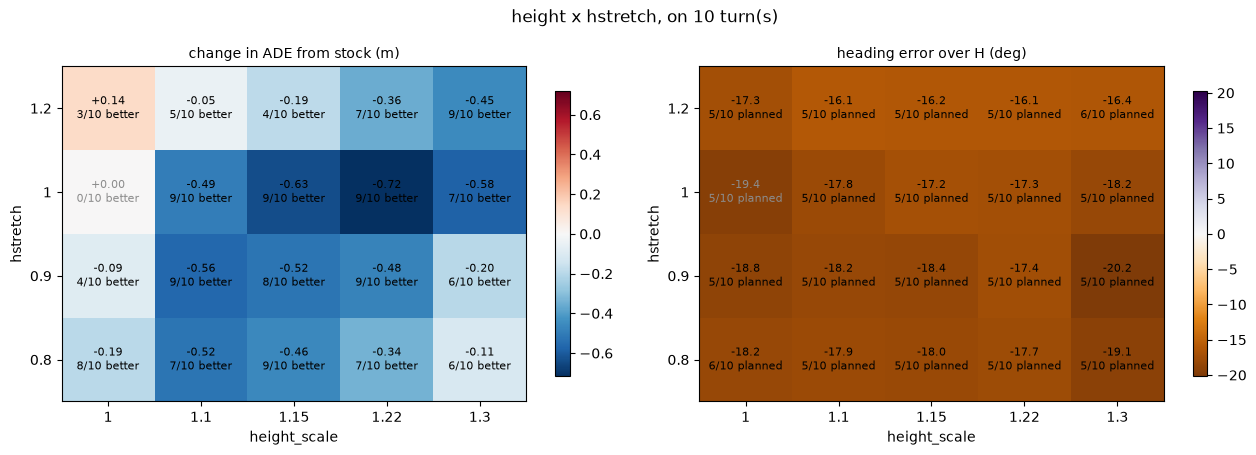

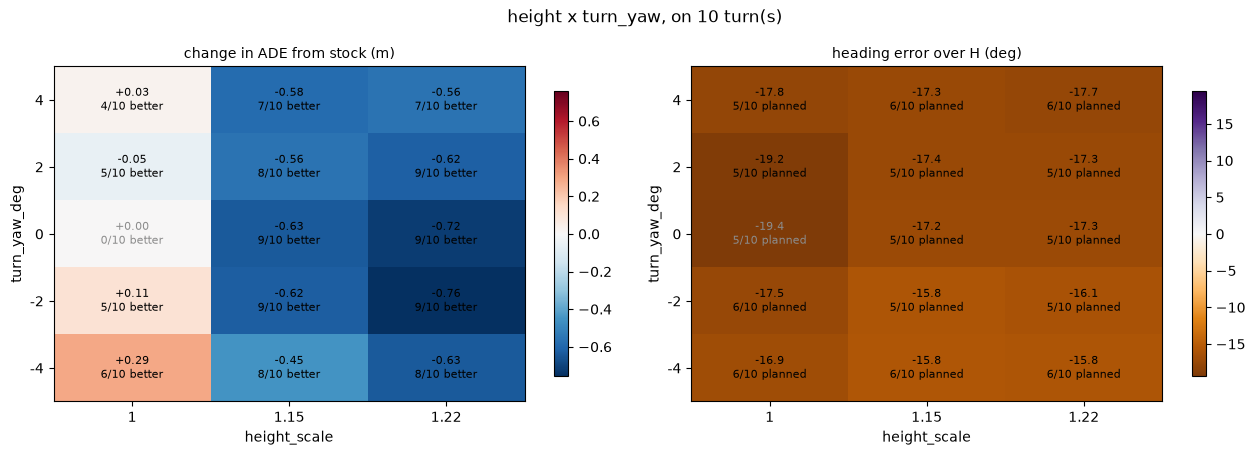

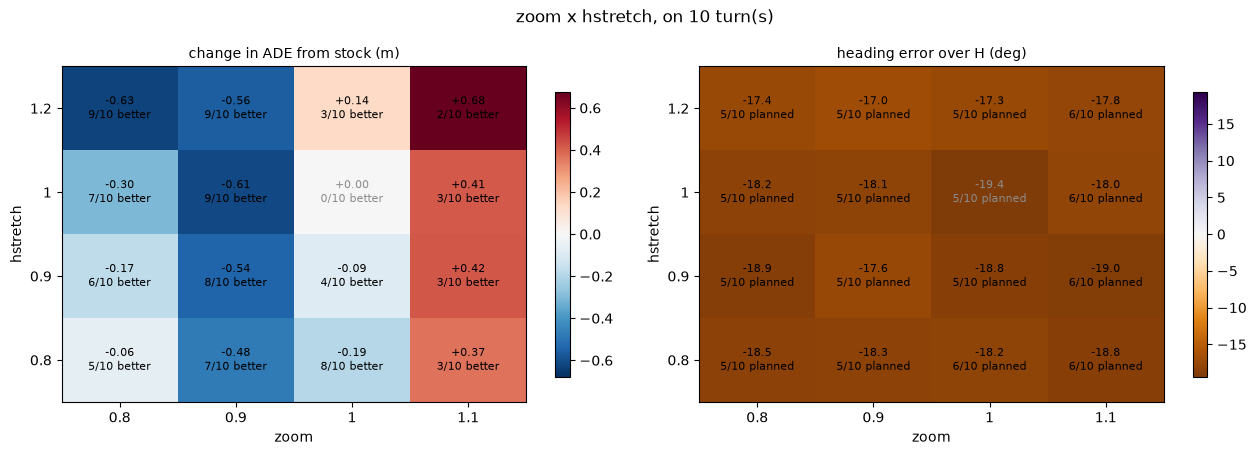

the five best cells over every grid:


,n,ADE,dADE,lo,hi,better,planned,dpsi_err,|dpsi_err|,v0_ratio,head_ratio,cam_h,ade_long,turn_frac,gt_in_big_img,in_bounds
setting,,,,,,,,,,,,,,,,
height_scale=1.15 pitch_deg=-1,10,0.82,-0.78,-1.15,-0.38,8/10,5/10,-18.71,20.31,0.99,0.93,1.42,8.41,0.44,0.34,1.0
height_scale=1.22 turn_yaw_deg=-2,10,0.84,-0.76,-1.08,-0.41,9/10,5/10,-16.12,18.86,1.02,0.96,1.42,7.99,0.41,0.32,1.0
height_scale=1.15 pitch_deg=-0.5,10,0.85,-0.75,-1.16,-0.33,8/10,5/10,-18.56,20.44,0.98,0.93,1.43,8.39,0.42,0.33,1.0
height_scale=1.22 pitch_deg=-1.5,10,0.86,-0.74,-1.19,-0.25,8/10,5/10,-19.64,19.96,1.04,0.95,1.37,8.34,0.46,0.36,1.0
height_scale=1.22 pitch_deg=-1,10,0.86,-0.73,-1.19,-0.26,8/10,5/10,-18.15,20.20,1.02,0.95,1.39,8.58,0.45,0.35,1.0


In [17]:
def gridded(kx, vx, ky, vy):
    """{(x, y): Setting} over a grid of two knobs."""
    return {(x, y): Setting(**{kx: x, ky: y}) for y in vy for x in vx}


def grid_plot(name, df):
    kx, vx, ky, vy = GRIDS[name]
    cells = gridded(kx, vx, ky, vy)
    s = summary(df[df.setting.isin(["stock"] + [st.label() for st in cells.values()])])
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
    for ax, col, cmap, title in (
        (axs[0], "dADE", "RdBu_r", "change in ADE from stock (m)"),
        (axs[1], "dpsi_err", "PuOr", "heading error over H (deg)"),
    ):
        m = np.array([[s.loc[cells[(x, y)].label(), col] for x in vx] for y in vy])
        lim = np.nanmax(np.abs(m)) or 1.0
        im = ax.imshow(m, cmap=cmap, vmin=-lim, vmax=lim, origin="lower", aspect="auto")
        for j, y in enumerate(vy):
            for i, x in enumerate(vx):
                row = s.loc[cells[(x, y)].label()]
                inside = BAND["ade"][0] <= row.dADE <= BAND["ade"][1]
                text = f"{row[col]:+.2f}\n{row.better} better" if col == "dADE" else f"{row[col]:+.1f}\n{row.planned} planned"
                ax.text(i, j, text, ha="center", va="center", fontsize=8, color=GREY if inside else "black")
        ax.set_xticks(range(len(vx)))
        ax.set_xticklabels([f"{x:g}" for x in vx])
        ax.set_yticks(range(len(vy)))
        ax.set_yticklabels([f"{y:g}" for y in vy])
        ax.set_xlabel(kx)
        ax.set_ylabel(ky)
        ax.set_title(title, fontsize=10)
        fig.colorbar(im, ax=ax, shrink=0.85)
    fig.suptitle(f"{name}, on {len(ACTIVE)} turn(s)", fontsize=12)
    fig.tight_layout()
    plt.show()
    return s


grid_df = table([st for kx, vx, ky, vy in GRIDS.values() for st in gridded(kx, vx, ky, vy).values()])
S8 = {}
for name in GRIDS:
    S8[name] = grid_plot(name, grid_df)
S8_ALL = summary(grid_df)
print("the five best cells over every grid:")
display(S8_ALL.drop("stock").sort_values("dADE").head(5).round(2))

## 9 Comparators: the route, self-calibration, and the plan's own scale

The image knobs need something to beat. These comparators change no pixel's content, or are not chosen on the ten turns, or both:

1. **The route as a desire** (`desire=True`). This is openpilot's own input for a turn, sent on the keyframe only.
    - The note's Q1 measured it on all 223 keyframes, in run `INTENT_RUN`. The node is checked against that run first, to §4's tolerance.
    - Then it is measured here: alone, with the best image setting of §7 and §8, and with 3's rescale.
2. **Self-calibration** from the stock model's own readings of the keyframe, per turn, with no GT. Each one is an image setting a car could choose from what the model says plus what the car knows anyway:
    - **`height from cam_h`:** s = h / `cam_h`, the camera's real height over the height the road head reads. If the model held on to its height reading whatever the image, this would make its distances right.
    - **`height from speed, one step`:** s = 1 / `head_ratio`, the car's own speed over the pose head's. If the model followed the image exactly, it would then read the right speed. It does not (§6), so this undershoots.
    - **`height from speed`:** the same target, searched. Each step runs the turn again and moves s along the line through the last two (log s, log `head_ratio`) points, until the pose head reads the car's speed. A car could run this online, from its own odometry.
    - **`+ pitch from motion`:** the searched scale, with the view pitched by the angle the pose head says the car moves at. That is what openpilot's calibrationd corrects, over minutes of straight driving rather than one keyframe.
3. **Rescaling the plan instead of the image,** also with no GT. The stock plan times v / v_plan, where:
    - v is the car's speed;
    - v_plan is the plan's first step.

    The note's Q3 found the start speed 64% of ADE over all keyframes. This removes it at the output, without the model seeing anything new.

    The best image setting's plan, rescaled the same way, asks whether the image does anything the rescale does not.
4. **The oracle:** the same rescale, to the GT's own first step (`ade_net`). No car has this. It bounds what any fix to the speed alone can do.
5. **The route, only when the turn is near.** The note's Q1 found the desire's whole cost on turns 40 m or more ahead, which the model does not see yet. `gated()` sends it only under `NEAR_M`:
    - the rows are composed from runs made anyway, the desire's on the near turns and the same setting's without it on the rest, so they are not a run;
    - alone, with the best image setting, and with the rescale, they put each fix where [the note's synthesis](openpilot_drv_supcombo_kitscenes_four_questions.md#the-four-questions-as-one-problem) says it belongs.

None of 2–4 is chosen on the ten turns, so none needs §10's check, except the rescaled best image setting: its image was chosen here. Neither is 5's 40 m, but it was chosen in Q1, after seeing all 39 turns.

In [18]:
DESIRE = Setting(desire=True)
_against(INTENT_RUN, DESIRE, f"the route as a desire vs {INTENT_RUN}")

_s7 = S7[S7.n == len(ACTIVE)].drop("stock")
_s8 = S8_ALL[S8_ALL.n == len(ACTIVE)].drop("stock")
_by_label = {st.label(): st for sts in SWEPT.values() for st in sts} | {
    st.label(): st for g in GRIDS.values() for st in gridded(*g).values()
}
BEST_SINGLE = _by_label[_s7.dADE.idxmin()]
BEST_GRID = _by_label[_s8.dADE.idxmin()]
BEST = BEST_GRID if _s8.dADE.min() < _s7.dADE.min() else BEST_SINGLE
print(f"best single knob: {BEST_SINGLE.label()}; best grid cell: {BEST_GRID.label()}; best: {BEST.label()} (chosen on these turns)")


def per_turn(name, make, keys=None):
    """table()'s rows for a setting chosen per turn: make(stock's row, scene) -> Setting. Every row is labelled
    `name`, so summary() treats them as one setting, and `chose` says what each turn got."""
    sids = [sid_of(k) for k in (ACTIVE if keys is None else keys)]
    base = table([], keys=sids).set_index("key")
    sts = {sid: make(base.loc[scene(sid).label], scene(sid)) for sid in sids}
    res = fetch([(st, sid) for sid, st in sts.items()] + [(STOCK, sid) for sid in sids])
    out = []
    for i, sid in enumerate(sids):
        row = _row(sts[sid], scene(sid), res[i], res[len(sids) + i], PLAN_FRAME)
        out.append(row | {"setting": name, "chose": sts[sid].label()})
    return pd.DataFrame(out)


def rescaled(name, factor, keys=None, setting=None):
    """Rows for a setting's plan (stock's by default) times factor(scene, plan, extras): a change to the output,
    scored like a setting."""
    st = STOCK if setting is None else setting
    sids = [sid_of(k) for k in (ACTIVE if keys is None else keys)]
    out = []
    for sid, r in zip(sids, fetch([(st, sid) for sid in sids])):
        sc = scene(sid)
        xy = apply_h(np.linalg.inv(road_map(st, sc)), plan(r)) if PLAN_FRAME == "world" else plan(r)
        k = factor(sc, xy, r["extras"])
        k = k if np.isfinite(k) and k > 0 else 1.0
        out.append(
            {"setting": name, "key": sc.label, "route": sc.side, "chose": f"x{k:.2f}"}
            | {"in_bounds": min(r["in_bounds"].values()) if r.get("in_bounds") else 1.0}
            | turn_metrics(sc, xy * k, r["extras"])
            | _angles(r["extras"])
        )
    return pd.DataFrame(out)


def _scale(x):
    """A height scale from a reading, to 3 decimals so the cache sees one value; 1 where the reading is missing."""
    return float(np.round(np.clip(x, 0.8, 1.8), 3)) if np.isfinite(x) and x > 0 else 1.0


def _head(r, sc):
    return r["extras"]["pose"]["velocity"][0] / sc.v if "error" not in r and sc.v >= P["v_go"] else np.nan


SPEED_STEPS = 3  # runs per turn in the search for the scale at which the pose head reads the car's speed


def speed_scale(keys=None, steps=SPEED_STEPS):
    """{sample id: height scale}: per turn, a secant search on log head_ratio against log s, from stock. The first
    step assumes the model follows the image exactly; each later one uses the response the turn has shown."""
    sids = [sid_of(k) for k in (ACTIVE if keys is None else keys)]
    s = {sid: [1.0] for sid in sids}
    r = {sid: [_head(x, scene(sid))] for sid, x in zip(sids, fetch([(STOCK, sid) for sid in sids]))}
    for _ in range(steps):
        for sid in sids:
            (s0, s1), (r0, r1) = ([np.nan] + s[sid])[-2:], ([np.nan] + r[sid])[-2:]
            a = np.log(r1 / r0) / np.log(s1 / s0) if np.isfinite(r0) and s1 != s0 else 1.0
            a = float(np.clip(a, 0.2, 1.5)) if np.isfinite(a) else 1.0
            s[sid].append(_scale(s1 * (1.0 / r1) ** (1.0 / a)) if np.isfinite(r1) else s1)
        res = fetch([(Setting(height_scale=s[sid][-1]), sid) for sid in sids])
        for sid, x in zip(sids, res):
            r[sid].append(_head(x, scene(sid)))
    return {sid: s[sid][-1] for sid in sids}


SELF_CAL = {
    "height from cam_h": lambda row, sc: Setting(height_scale=_scale(sc.h / row.cam_h)),
    "height from speed, one step": lambda row, sc: Setting(height_scale=_scale(1.0 / row.head_ratio)),
    "height from speed": lambda row, sc: Setting(height_scale=SPEED_SCALE[sc.sid]),
    "height from speed + pitch from motion": lambda row, sc: Setting(
        height_scale=SPEED_SCALE[sc.sid], pitch_deg=round(float(row.vel_pitch), 2)
    ),
}
OUTPUT = {
    "plan x v / v_plan": lambda sc, xy, ex: sc.v / _first_speed(xy),
    "oracle: plan x v_gt / v_plan": lambda sc, xy, ex: _first_speed(sc.gt) / _first_speed(xy),
}
BOTH = f"{BEST.label()} + plan x v / v_plan"  # the best image, and the rescale on top
DESIRE_OUT = f"{DESIRE.label()} + plan x v / v_plan"
NEAR_M = 40  # the note's Q1 cut: the desire cost ADE only on turns this far ahead or further
GATED = {  # name: (the setting on turns under NEAR_M ahead, the setting on the rest)
    f"desire under {NEAR_M} m": (DESIRE.label(), "stock"),
    f"desire under {NEAR_M} m + {BEST.label()}": ((DESIRE + BEST).label(), BEST.label()),
    f"desire under {NEAR_M} m + plan x v / v_plan": (DESIRE_OUT, "plan x v / v_plan"),
}


def gated(name, df, near, far):
    """Rows labelled `name`: setting `near`'s on turns under NEAR_M ahead, setting `far`'s on the rest. Composed
    from df's rows, so a desire sent only when the turn is near costs no run, and is not one."""
    rows = df.drop_duplicates(["setting", "key"]).set_index(["setting", "key"])
    return pd.DataFrame(
        [
            rows.loc[(near if scene(k).nav_m < NEAR_M else far, k)].to_dict() | {"setting": name, "key": k, "chose": None}
            for k in rows.loc[far].index
        ]
    )


def comparators(keys=None, image=()):
    """Every §9 comparator on `keys`, plus the image settings in `image`, as one table."""
    SPEED_SCALE.update(speed_scale(keys))
    parts = [table([BEST, DESIRE, DESIRE + BEST, *image], keys=keys)]
    parts += [per_turn(name, make, keys) for name, make in SELF_CAL.items()]
    parts += [rescaled(name, f, keys) for name, f in OUTPUT.items()]
    parts += [rescaled(BOTH, OUTPUT["plan x v / v_plan"], keys, setting=BEST)]
    parts += [rescaled(DESIRE_OUT, OUTPUT["plan x v / v_plan"], keys, setting=DESIRE)]
    df = pd.concat(parts, ignore_index=True)
    return pd.concat([df] + [gated(name, df, near, far) for name, (near, far) in GATED.items()], ignore_index=True)


SPEED_SCALE = {}  # {sample id: the searched height scale}, filled by comparators()
comp_df = comparators()
S9 = summary(comp_df)
display(S9.round(2))
_d = change(comp_df, "ade", [DESIRE])[DESIRE.label()]
_far = pd.Series({k: not scene(k).nav_m < NEAR_M for k in _d.index})
print(
    f"the desire's change in ADE: {_d[_far].mean():+.2f} m on the {int(_far.sum())} turn(s) {NEAR_M} m or more ahead, "
    f"{_d[~_far].mean():+.2f} m on the other {int((~_far).sum())} (the note's Q1 found its cost on the far turns)"
)
print("what each turn's self-calibration chose:")
display(comp_df[comp_df.chose.notna()].pivot_table(index="key", columns="setting", values="chose", aggfunc="first"))

the route as a desire vs 20260930T014333-d329a6 on 10: largest difference within H 0.016 m, over 10 s 0.19 m; ADE differs by 0.001 m on average, 0.003 at most
best single knob: height_scale=1.22; best grid cell: height_scale=1.15 pitch_deg=-1; best: height_scale=1.15 pitch_deg=-1 (chosen on these turns)


,n,ADE,dADE,lo,hi,better,planned,dpsi_err,|dpsi_err|,v0_ratio,head_ratio,cam_h,ade_long,turn_frac,gt_in_big_img,in_bounds
setting,,,,,,,,,,,,,,,,
stock,10,1.60,0.00,0.00,0.00,0/10,5/10,-19.42,21.97,0.87,0.82,1.43,10.55,0.41,0.30,1.0
height_scale=1.15 pitch_deg=-1,10,0.82,-0.78,-1.15,-0.38,8/10,5/10,-18.71,20.31,0.99,0.93,1.42,8.41,0.44,0.34,1.0
desire=True,10,2.11,0.51,-0.11,1.29,5/10,8/10,-25.80,27.73,0.93,0.82,1.43,12.73,0.81,0.30,1.0
height_scale=1.15 pitch_deg=-1 desire=True,10,1.57,-0.02,-0.57,0.51,6/10,9/10,-23.90,25.07,1.04,0.93,1.42,11.06,0.87,0.34,1.0
height from cam_h,10,0.94,-0.66,-1.09,-0.20,9/10,5/10,-18.52,20.45,1.08,0.99,1.42,8.71,0.45,0.36,1.0
"height from speed, one step",10,1.03,-0.57,-0.95,-0.20,8/10,5/10,-18.90,21.34,1.04,0.95,1.43,9.19,0.44,0.34,1.0
height from speed,10,1.29,-0.31,-0.86,0.30,7/10,5/10,-18.38,20.47,1.12,1.02,1.42,9.31,0.44,0.35,1.0
height from speed + pitch from motion,10,1.28,-0.32,-0.83,0.18,6/10,5/10,-18.21,18.84,1.10,1.00,1.40,8.95,0.46,0.35,1.0
plan x v / v_plan,10,1.02,-0.58,-1.01,-0.15,8/10,5/10,-19.42,21.97,1.02,0.82,1.43,10.04,0.41,NaN,1.0


the desire's change in ADE: +2.43 m on the 2 turn(s) 40 m or more ahead, +0.04 m on the other 8 (the note's Q1 found its cost on the far turns)
what each turn's self-calibration chose:


setting,desire=True + plan x v / v_plan,height from cam_h,height from speed,height from speed + pitch from motion,"height from speed, one step",height_scale=1.15 pitch_deg=-1 + plan x v / v_plan,oracle: plan x v_gt / v_plan,plan x v / v_plan
key,,,,,,,,
03ed2585/40,x0.99,height_scale=1.372,height_scale=1.67,height_scale=1.67 pitch_deg=-0.31,height_scale=1.408,x0.94,x1.11,x1.12
0cfdeb83/40,x0.95,height_scale=1.364,height_scale=1.338,height_scale=1.338 pitch_deg=-1.99,height_scale=1.14,x0.95,x1.08,x1.07
18775d16/40,x1.09,height_scale=1.138,height_scale=1.088,height_scale=1.088 pitch_deg=-0.38,height_scale=1.065,x0.99,x1.08,x1.06
2673dca8/220,x1.06,height_scale=1.363,height_scale=1.272,height_scale=1.272 pitch_deg=-0.23,height_scale=1.238,x0.99,x1.06,x1.11
5bf1c78c/40,x1.15,height_scale=1.429,height_scale=1.505,height_scale=1.505 pitch_deg=0.12,height_scale=1.305,x1.11,x1.24,x1.35
5d443f77/40,x1.22,height_scale=1.443,height_scale=1.418,height_scale=1.418 pitch_deg=0.2,height_scale=1.5,x1.09,x1.35,x1.31
8c501afb/40,x1.18,height_scale=1.341,height_scale=1.637,height_scale=1.637 pitch_deg=0.32,height_scale=1.378,x1.20,x1.26,x1.28
b8002a79/40,x1.18,height_scale=1.15,height_scale=1.167,height_scale=1.167 pitch_deg=-0.6,height_scale=1.133,x1.02,x1.09,x1.10
d96782f8/220,x1.06,height_scale=1.361,height_scale=1.311,height_scale=1.311 pitch_deg=0.39,height_scale=1.131,x1.01,x1.02,x1.10


## 10 Leave one turn out

§7 and §8 tried about a hundred settings on ten turns, and the best of a hundred noisy numbers is optimistic. This section measures by how much.

For each turn in turn:
1. Choose the setting with the lowest mean ADE over the other nine.
2. Score that choice on the turn left out.

The mean of those ten scores is what choosing a setting this way would do to a turn it was not chosen on. Its distance from the best's in-sample mean is the optimism. `chosen` counts how often each setting won. One setting winning every time is a stable choice; a different winner each time is a choice made on noise.

In [19]:
def loso(df):
    """(table, picks): per held-out turn, the setting best on the others, and its change in ADE on that turn."""
    ok = df[df["error"].isna()] if "error" in df.columns else df
    ade = ok.drop_duplicates(["setting", "key"]).pivot(index="setting", columns="key", values="ade")
    d = (ade - ade.loc["stock"]).dropna()
    rows = []
    for k in d.columns:
        rest = d.drop(columns=k).mean(axis=1)
        pick = rest.idxmin()
        rows.append({"held out": k, "chosen on the others": pick, "dADE on the others": rest[pick], "dADE held out": d.loc[pick, k]})
    return pd.DataFrame(rows).set_index("held out"), d


L10, _d_all = loso(pd.concat([sweep_df, grid_df]))
display(L10.round(2))
lo, hi = boot_ci(L10["dADE held out"])
_optimism = L10["dADE held out"].mean() - _d_all.loc[BEST.label()].mean()
print(
    f"held out: mean dADE {L10['dADE held out'].mean():+.2f} m [{lo:+.2f}, {hi:+.2f}], "
    f"{int((L10['dADE held out'] < 0).sum())}/{len(L10)} better; in sample, the best ({BEST.label()}) "
    f"{_d_all.loc[BEST.label()].mean():+.2f} m. Optimism: {_optimism:.2f} m, how much better the in-sample number looks"
)
print("chosen:", L10["chosen on the others"].value_counts().to_dict())

,chosen on the others,dADE on the others,dADE held out
held out,,,
03ed2585/40,height_scale=1.15 pitch_deg=-1,-0.69,-1.53
0cfdeb83/40,height_scale=1.22 turn_yaw_deg=-2,-0.83,-0.08
18775d16/40,height_scale=1.15 pitch_deg=-1,-0.71,-1.41
2673dca8/220,height_scale=1.15 pitch_deg=-1,-0.80,-0.56
5bf1c78c/40,height_scale=1.15 pitch_deg=-1,-0.79,-0.65
5d443f77/40,height_scale=1.15 pitch_deg=-1,-0.72,-1.33
8c501afb/40,height_scale=1.15 pitch_deg=-1,-0.89,0.20
b8002a79/40,height_scale=1.22 turn_yaw_deg=-2,-0.69,-1.33
d96782f8/220,height_scale=1.22 pitch_deg=-1,-0.88,0.58


held out: mean dADE -0.65 m [-1.07, -0.22], 8/10 better; in sample, the best (height_scale=1.15 pitch_deg=-1) -0.78 m. Optimism: 0.13 m, how much better the in-sample number looks
chosen: {'height_scale=1.15 pitch_deg=-1': 7, 'height_scale=1.22 turn_yaw_deg=-2': 2, 'height_scale=1.22 pitch_deg=-1': 1}


## 11 By hand

`look(key, **knobs)` takes every knob, so any cell can draw any setting on any turn. `run=False` draws only what the model would be shown, in under a second.

With `WIDGETS = True` (§1, or `PADDOCK_ANALYSIS_WIDGETS=1`), `explore()` puts the knobs on sliders:
- **draw** draws without the model;
- **run** runs it.

Either way it prints the `look()` call, so a setting found by hand can be pasted into a cell or into `TRY`. The widgets are off by default: VS Code cannot draw saved widgets, so a committed notebook would show only a placeholder.

In [20]:
SLIDERS = {  # knob: (lowest, highest, step)
    "height_scale": (0.8, 1.8, 0.01),
    "zoom": (0.7, 1.5, 0.01),
    "hstretch": (0.7, 1.6, 0.01),
    "turn_yaw_deg": (-6.0, 6.0, 0.25),
    "yaw_deg": (-4.0, 4.0, 0.25),
    "pitch_deg": (-3.0, 3.0, 0.1),
    "roll_deg": (-4.0, 4.0, 0.25),
    "ahead_m": (-5.0, 10.0, 0.5),
    "sharpen": (-1.0, 2.0, 0.1),
    "gamma": (0.5, 2.0, 0.05),
    "contrast": (0.5, 1.5, 0.05),
    "saturation": (0.0, 2.0, 0.1),
}


def explore(key=None, setting=None):
    """Sliders for the knobs, a turn, and draw/run buttons; prints the look() call each draws."""
    if W is None:
        print("ipywidgets is not installed here: call look() directly")
        return
    start = as_setting(setting if setting is not None else TRY)
    turn = W.Dropdown(options=[(scene(s).label, s) for s in TEN], value=sid_of(key or EXAMPLE_SID), description="turn")
    sl = {
        k: W.FloatSlider(value=getattr(start, k), min=lo, max=hi, step=step, description=k, continuous_update=False)
        for k, (lo, hi, step) in SLIDERS.items()
    }
    ss = W.IntSlider(value=start.supersample, min=1, max=4, description="supersample")
    desire = W.Checkbox(value=start.desire, description="desire")
    draw, run, reset = W.Button(description="draw"), W.Button(description="run", button_style="primary"), W.Button(description="stock")
    out = W.Output()

    def go(with_model):
        knobs = {k: round(w.value, 4) for k, w in sl.items()} | {"supersample": ss.value, "desire": desire.value}
        st = as_setting(start, **knobs)  # the knobs without a slider keep their value from `setting`
        out.clear_output(wait=True)
        with out:
            args = ", ".join(f"{k}={v!r}" for k, v in st.changed().items())
            print(f"look({scene(turn.value).label!r}{', ' + args if args else ''}{'' if with_model else ', run=False'})")
            look(turn.value, setting=st, run=with_model)

    def to_stock(_):
        for k, w in sl.items():
            w.value = getattr(STOCK, k)
        ss.value, desire.value = 1, False

    draw.on_click(lambda _: go(False))
    run.on_click(lambda _: go(True))
    reset.on_click(to_stock)
    display(W.VBox([W.HBox([turn, draw, run, reset]), W.GridBox(list(sl.values()) + [ss, desire], layout=W.Layout(grid_template_columns="repeat(4, 300px)")), out]))


if WIDGETS:
    explore()
else:
    print("WIDGETS is off: explore() draws nothing in a saved notebook. Set it in §1, or call look() directly, e.g.")
    print(f"    look({scene(EXAMPLE_SID).label!r}, {', '.join(f'{k}={v!r}' for k, v in TRY_ST.changed().items())}, run=False)")

WIDGETS is off: explore() draws nothing in a saved notebook. Set it in §1, or call look() directly, e.g.
    look('03ed2585/40', height_scale=1.15, hstretch=1.2, run=False)


## 12 Scores

Every comparison in one table, on the active turns, with what each row could be used for:
- **image, chosen here:** an image setting picked on these turns. Its score is optimistic; §10 says by how much.
- **image, held out:** §10's choice, each turn scored by a setting chosen without it.
- **image, self-calibrated:** chosen per turn from the stock model's own readings. No GT, no choosing on these turns.
- **input:** the route as a desire.
- **output:** the plan rescaled. **oracle:** the same with the GT's start speed, which no car has.
- **composed:** §9's desire sent only on turns under `NEAR_M` ahead, put together from runs made anyway. The 40 m was chosen in the note's Q1 after seeing these turns, so these rows are hypotheses for a run.

In [21]:
KIND = {"stock": "", TRY_ST.label(): "image, TRY", BEST_SINGLE.label(): "image, chosen here", BEST_GRID.label(): "image, chosen here"}
KIND |= {DESIRE.label(): "input", (DESIRE + BEST).label(): "input + image chosen here"}
KIND |= {name: "image, self-calibrated" for name in SELF_CAL} | {name: "output" for name in OUTPUT}
KIND[BOTH] = "image chosen here + output"
KIND[DESIRE_OUT] = "input + output"
KIND |= dict(zip(GATED, ["composed: input", "composed: input + image chosen here", "composed: input + output"]))
KIND["oracle: plan x v_gt / v_plan"] = "oracle"
KIND["held out (§10)"] = "image, held out"
_cand = pd.concat([sweep_df, grid_df]).drop_duplicates(["setting", "key"]).set_index(["setting", "key"])
_held = pd.DataFrame(
    [_cand.loc[(pick, k)].to_dict() | {"setting": "held out (§10)", "key": k} for k, pick in L10["chosen on the others"].items()]
)
score_df = pd.concat([table([TRY_ST, BEST_SINGLE, BEST_GRID]), comp_df, _held], ignore_index=True)
SCORES = summary(score_df.drop_duplicates(["setting", "key"]))
SCORES.insert(0, "kind", [KIND.get(name, "") for name in SCORES.index])
cols = ["kind", "n", "ADE", "dADE", "lo", "hi", "better", "planned", "dpsi_err", "|dpsi_err|", "v0_ratio", "head_ratio", "ade_long", "turn_frac"]
display(SCORES[cols].round(2))
_img = pd.concat([S7.drop(columns=["knob", "floor"]), S8_ALL])
_img = _img[~_img.index.duplicated()].drop(["stock", "blank=img", "tick_rate=2.2"], errors="ignore")
_planned = _img.planned.str.split("/").str[0].astype(int)
print(
    f"the {len(_img)} image settings of §7 and §8, but for blank=img and tick_rate=2.2 (§6): heading error over H "
    f"{_img.dpsi_err.min():+.1f} to {_img.dpsi_err.max():+.1f} deg, against stock's {S7.loc['stock', 'dpsi_err']:+.1f}; "
    f"turns planned {_planned.min()} to {_planned.max()} of {len(ACTIVE)}, against stock's {S7.loc['stock', 'planned']}"
)

,kind,n,ADE,dADE,lo,hi,better,planned,dpsi_err,|dpsi_err|,v0_ratio,head_ratio,ade_long,turn_frac
setting,,,,,,,,,,,,,,
stock,,10,1.60,0.00,0.00,0.00,0/10,5/10,-19.42,21.97,0.87,0.82,10.55,0.41
height_scale=1.15 hstretch=1.2,"image, TRY",10,1.41,-0.19,-0.66,0.26,4/10,5/10,-16.23,19.85,0.95,0.88,9.36,0.40
height_scale=1.22,"image, chosen here",10,0.88,-0.72,-1.11,-0.31,9/10,5/10,-17.25,20.01,1.01,0.95,8.63,0.44
height_scale=1.15 pitch_deg=-1,"image, chosen here",10,0.82,-0.78,-1.15,-0.38,8/10,5/10,-18.71,20.31,0.99,0.93,8.41,0.44
desire=True,input,10,2.11,0.51,-0.11,1.29,5/10,8/10,-25.80,27.73,0.93,0.82,12.73,0.81
height_scale=1.15 pitch_deg=-1 desire=True,input + image chosen here,10,1.57,-0.02,-0.57,0.51,6/10,9/10,-23.90,25.07,1.04,0.93,11.06,0.87
height from cam_h,"image, self-calibrated",10,0.94,-0.66,-1.09,-0.20,9/10,5/10,-18.52,20.45,1.08,0.99,8.71,0.45
"height from speed, one step","image, self-calibrated",10,1.03,-0.57,-0.95,-0.20,8/10,5/10,-18.90,21.34,1.04,0.95,9.19,0.44
height from speed,"image, self-calibrated",10,1.29,-0.31,-0.86,0.30,7/10,5/10,-18.38,20.47,1.12,1.02,9.31,0.44


the 95 image settings of §7 and §8, but for blank=img and tick_rate=2.2 (§6): heading error over H -21.4 to -15.8 deg, against stock's -19.4; turns planned 5 to 6 of 10, against stock's 5/10


### The answer

Measured on the ten turns with §1's defaults, against stock's ADE of 1.60 m. The CIs are 95% bootstrap intervals over the turns, each in its own scene.

**The image can cut the score, through the speed** (measured):
- **The height scale is the lever.** At 1.22, the note's s\*, ADE falls to 0.88 m (−0.72, CI −1.11 to −0.31), better on 9 of 10. The plan's start speed goes from 0.87 to 1.01 of the GT's.
- **A zoom is the same lever.** At 0.9, ADE is 0.99 m.
- **Little else adds to it.** §8's best cell is height 1.15 with the view pitched 1° down, at 0.82 m.
    - Choosing on nine turns and scoring the tenth (§10) gives 0.95 m, better on 8 of 10.
    - So 0.13 m of the in-sample gain is choosing on noise.
- **A setting a car could choose itself does about as well.** `height from cam_h`, the camera's height over the height the road head reads, gives 0.94 m, with no GT and nothing chosen here.

**It does not make the plan turn** (measured):
- **The heading hardly moves.** Over the 95 image settings of §7 and §8, all but `blank=img` and `tick_rate=2.2`:
    - the heading error over H stays between −21.4° and −15.8°, against stock's −19.4°;
    - at most 6 of the 10 plans turn toward the route, against stock's 5.
- **So ADE nearly halves while the plans turn little more.** What moves is the speed.
    - Setting only the plan's start speed right, the oracle row, takes 0.62 m off stock's ADE here.
    - The image takes off more, 0.72 m at 1.22, so it changes more of the plan than its start.
- **More of the turn in view does not help.** Zooming the wide view out, or turning it to the route, puts up to 48% of the GT's waypoints inside it, against 30%. Neither ADE nor the heading gets better by more than §6's floor.
- **The plan comes from the narrow view.** Blanking it adds 9.0 m to ADE. Blanking the wide view changes ADE by −0.14 m.

**The route makes it turn, later** (measured):
- **More plans take the turn.** Sent as a desire, the route takes the plans that turn toward it from 5 to 8 of 10. The plan's turn over the whole GT goes from 0.41 to 0.81 of the GT's (median).
- **But within H the plan turns less** (−25.8°), and ADE rises to 2.11 m.
    - Nearly all of that rise is on the two turns 64–66 m ahead (+2.43 m on average).
    - On the other eight the change is +0.04 m, as the note's Q1 found.
- **With the best image setting as well,** 9 of 10 turn toward the route, at about stock's ADE (1.57 m).
- **Sent only on the turns under 40 m ahead** (§9's 5, composed), the far turns' cost goes, and the later turn stays.
    - Alone, ADE is 1.63 m, with 7 of 10 plans turning toward the route.
    - With the speed fixed as well, the desire costs more than it did alone: 1.19 m with the best image (0.82 without the desire), and 1.31 m with the rescale (1.02 without).
    - Within H, those plans turn less than stock's: −24.6° and −26.8°, against −19.4°.

**The output does as well as the image** (measured):
- **The rescale alone.** Rescaling stock's plan by v / v_plan gives 1.02 m, and the oracle 0.98 m. The image, held out, gives 0.95 m.
- **The best image's plan, rescaled the same way, gives 0.88 m,** 0.14 m better than the rescale alone. But that image was chosen here; §13 tries it where it was not.

**What it means** (argued): an image calibration fixes the speed the model reads, and through it nearly half of ADE on these turns. It does not fix the turn. That is decided by what the narrow view shows and what the model is told, and when. Told at the keyframe, the model starts the turn then, where the note's Q1 found half of the 39 turns already underway.

## 13 The other 29 turns

Everything above was measured on the ten turns it was chosen on. Here every setting a car could use runs on the 29 turns this notebook never looked at:
- `TRY`, and the best single knob and best grid cell, as chosen on the ten;
- the self-calibrations, the desire and the output rescale, which were not chosen on anything;
- §9's composed rows, whose 40 m was chosen in the note's Q1, on all 39 turns.

The 29 are new keyframes, not all new scenes: two share a scene with one of the ten, 9 s or more from it. The CIs resample scenes, as everywhere here.

Stock plans most of the 29 well. So the second table splits them by stock's mode: a knob that fixes too little turn may overdo a turn that was right.

In [22]:
if HOLDOUT:
    _scene_of = {sid: scene(sid).label.split("/")[0] for sid in TURNS}
    _shared = [scene(sid).label for sid in OTHERS if _scene_of[sid] in {_scene_of[t] for t in TEN}]
    print(f"{len(OTHERS)} turns over {len({_scene_of[sid] for sid in OTHERS})} scenes; in a scene of the ten: {', '.join(_shared) or 'none'}")
    hold_df = pd.concat([table([TRY_ST, BEST_SINGLE, BEST_GRID], keys=OTHERS), comparators(keys=OTHERS)], ignore_index=True)
    hold_df = hold_df.drop_duplicates(["setting", "key"])
    HOLD = summary(hold_df)
    HOLD.insert(0, "kind", [KIND.get(name, "") for name in HOLD.index])
    display(HOLD[cols].round(2))
    ok = hold_df[hold_df["error"].isna()] if "error" in hold_df.columns else hold_df
    base = ok[ok.setting == "stock"].set_index("key")
    by = ok.assign(
        dADE=ok.ade.values - base.ade.reindex(ok.key).values,
        stock_mode=np.where(base["mode"].reindex(ok.key).values == "matched", "matched at stock", "not matched at stock"),
    )
    print("mean change in ADE from stock (m), and the turns, by what stock did:")
    display(
        by.pivot_table(index="setting", columns="stock_mode", values="dADE", aggfunc=["mean", "count"], sort=False).round(2)
    )
else:
    print("HOLDOUT is off")

29 turns over 25 scenes; in a scene of the ten: b8002a79/130, d96782f8/40


,kind,n,ADE,dADE,lo,hi,better,planned,dpsi_err,|dpsi_err|,v0_ratio,head_ratio,ade_long,turn_frac
setting,,,,,,,,,,,,,,
stock,,29,1.77,0.00,0.00,0.00,0/29,26/29,-4.28,6.73,0.96,0.82,7.80,0.86
height_scale=1.15 hstretch=1.2,"image, TRY",29,1.88,0.11,-0.20,0.46,13/29,27/29,-2.41,9.28,1.03,0.92,8.98,0.98
height_scale=1.22,"image, chosen here",29,1.44,-0.33,-0.73,0.07,18/29,26/29,-4.64,7.78,1.07,0.96,6.94,0.88
height_scale=1.15 pitch_deg=-1,"image, chosen here",29,1.44,-0.33,-0.71,0.07,18/29,26/29,-4.61,7.58,1.05,0.95,7.11,0.84
desire=True,input,29,2.00,0.23,-0.12,0.61,16/29,27/29,-10.93,12.40,0.99,0.82,10.84,0.97
height_scale=1.15 pitch_deg=-1 desire=True,input + image chosen here,29,1.70,-0.07,-0.49,0.41,15/29,27/29,-8.97,11.12,1.09,0.95,9.72,1.12
height from cam_h,"image, self-calibrated",29,1.57,-0.20,-0.69,0.32,17/29,26/29,-3.97,6.86,1.14,1.05,6.99,0.86
"height from speed, one step","image, self-calibrated",29,1.50,-0.27,-0.68,0.14,18/29,25/29,-5.36,7.69,1.08,0.99,7.26,0.86
height from speed,"image, self-calibrated",29,1.47,-0.30,-0.81,0.20,14/29,25/29,-5.16,8.77,1.11,1.02,6.96,0.90


mean change in ADE from stock (m), and the turns, by what stock did:


mean  \
stock_mode                                         matched at stock   
setting                                                               
stock                                                          0.00   
height_scale=1.15 hstretch=1.2                                 0.22   
height_scale=1.22                                             -0.22   
height_scale=1.15 pitch_deg=-1                                -0.23   
desire=True                                                    0.40   
height_scale=1.15 pitch_deg=-1 desire=True                     0.08   
height from cam_h                                             -0.09   
height from speed, one step                                   -0.21   
height from speed                                             -0.20   
height from speed + pitch from motion                         -0.19   
plan x v / v_plan                                             -0.79   
oracle: plan x v_gt / v_plan                                  -0.85   
height_scale=1.15 pitch_deg=-1 + plan x v / v_plan            -0.82   
desire=True + plan x v / v_plan                               -0.35   
desire under 40 m                                             -0.04   
desire under 40 m + height_scale=1.15 pitch_deg=-1            -0.29   
desire under 40 m + plan x v / v_plan                         -0.68   

                                                                         \
stock_mode                                         not matched at stock   
setting                                                                   
stock                                                              0.00   
height_scale=1.15 hstretch=1.2                                    -0.17   
height_scale=1.22                                                 -0.62   
height_scale=1.15 pitch_deg=-1                                    -0.60   
desire=True                                                       -0.20   
height_scale=1.15 pitch_deg=-1 desire=True                        -0.46   
height from cam_h                                                 -0.47   
height from speed, one step                                       -0.42   
height from speed                                                 -0.56   
height from speed + pitch from motion                             -0.64   
plan x v / v_plan                                                 -1.33   
oracle: plan x v_gt / v_plan                                      -1.51   
height_scale=1.15 pitch_deg=-1 + plan x v / v_plan                -1.22   
desire=True + plan x v / v_plan                                   -1.19   
desire under 40 m                                                 -0.18   
desire under 40 m + height_scale=1.15 pitch_deg=-1                -0.53   
desire under 40 m + plan x v / v_plan                             -1.30   

                                                              count  \
stock_mode                                         matched at stock   
setting                                                               
stock                                                            21   
height_scale=1.15 hstretch=1.2                                   21   
height_scale=1.22                                                21   
height_scale=1.15 pitch_deg=-1                                   21   
desire=True                                                      21   
height_scale=1.15 pitch_deg=-1 desire=True                       21   
height from cam_h                                                21   
height from speed, one step                                      21   
height from speed                                                21   
height from speed + pitch from motion                            21   
plan x v / v_plan                                                21   
oracle: plan x v_gt / v_plan                                     21   
height_scale=1.15 pitch_deg=-1 + plan x v / v_plan               21   
desir

### The answer

Measured on the 29 turns with §1's defaults, against stock's ADE of 1.77 m. Stock plans 26 of them toward the route, with a heading error over H of −4.3°, so these are mostly turns it already gets right.

- **The speed fix carries over, at half the size.** Height 1.22 gives 1.44 m (−0.33, CI −0.73 to +0.07), better on 18 of 29.
    - It cuts 0.22 m on the 21 turns stock matched, and 0.62 m on the 8 it did not.
    - Stock's plan starts nearer the right speed here: 0.96 of the GT's on average, against 0.87 on the ten. Its pose head reads 0.82 of the car's speed on both.
    - So one scale for every turn overshoots, to 1.07.
- **Choosing the scale per turn, from the model's own readings, does no better:** −0.20 to −0.32 m.
    - Searched until the pose head reads the car's speed (1.02 of it), the plan starts 11% fast.
    - The search corrects the pose head, and the plan does not start at the pose head's speed.
- **The output rescale gains about three times as much.** v / v_plan gives 0.83 m (−0.94, CI −1.35 to −0.57), better on 24 of 29.
    - It cuts 0.79 m on the turns stock matched and 1.33 m on the rest.
    - The oracle gives 0.74 m.
- **With the rescale, the image adds nothing.** The best image's plan, rescaled, gives 0.84 m. So on turns it was not chosen on, the image's whole gain in ADE was the speed.
- **The route as a desire costs 0.23 m.** That is +0.40 m on the turns stock matched and −0.20 m on the rest. Within H the plans turn less (−10.9°, against −4.3°).
- **Sent only on the turns under 40 m ahead** (composed), it costs nothing alone (1.69 m) or with the best image (1.41 m), and 0.09 m with the rescale (0.92 m, against 0.83). Within H the plans still turn less (−11.0°).

**So** (argued): to fix the speed, rescale the plan rather than the image. An image scale near 1.2 gives part of the same gain, and nothing on top of it. Neither fixes the turn, and the desire, gated or not, takes the turn later than the driver did. [The note](openpilot_drv_supcombo_kitscenes_four_questions.md#the-four-questions-as-one-problem) takes the four questions up as one problem, after Q4.

## 14 Scratch

Everything above is a function of keyword arguments, so experiments go here. Some starting points:

```python
look("5bf1c78c", height_scale=1.22, against=dict(desire=True))     # the speed fix, against the route as a desire
look("2673dca8", turn_yaw_deg=-3, hstretch=1.2, run=False)          # what the model would be shown, in under a second
strip("18775d16", "pitch_deg", values=[-2, -1, 1, 2])               # one knob on one turn, at values of your own
strip("03ed2585", "height_scale", view="img")                       # the narrow view, the one the plan comes from
summary(table([dict(height_scale=1.22, zoom=0.95), dict(height_scale=1.1, pitch_deg=-1)]))  # score new settings
summary(table([dict(height_scale=1.22)], keys=OTHERS))              # the same, on the 29 held-out turns
sweep_plot(sweep_df, "head_ratio")                                  # any column of table(), against each knob
summary(pd.concat([table([]), rescaled("1.22, rescaled", OUTPUT["plan x v / v_plan"], setting=Setting(height_scale=1.22))]))
GRIDS["zoom x pitch"] = ("zoom", [0.85, 0.9, 1.0], "pitch_deg", [-1.0, 0.0])
grid_plot("zoom x pitch", table(list(gridded(*GRIDS["zoom x pitch"]).values())))
```

`FOCUS` in §1 runs every section on fewer turns, and `EXAMPLE` picks the one §5 draws.

## 15 Stopping the nodes

They also stop with the kernel, and start again on the next call that needs one.

In [23]:
POOL.close()